# Energy attachment experiment

Team A | Rishitha Gogineni

Test one change to the original heuristic: prepare a Bench Pokemon after the Active Pokemon has enough energy for all its printed attacks. Keep the sample deck, all other decisions, the shared feature encoder and the original A-R1 model unchanged.

Use a fresh Colab CPU session. Upload only the official competition ZIP when prompted. The exact original heuristic and A-R1 checkpoint are included in this notebook. No installation, training, Kaggle credentials or submission is needed.

The new rule is an experiment. It has not been shown to improve gameplay. This notebook has not been executed with the native engine during preparation.


## 1. Fixed experiment

Run two fixed batches of 40 individual games for each comparison: original heuristic against A-R1, energy rule against original heuristic, and energy rule against A-R1. This gives 240 games in total. Seats and the SDK reverse flag alternate. These results use individual games, not the common notebook's match unit.

Do not change the settings between batches. Python seeds are recorded, but they do not control the native shuffles or coin flips. Matching seed numbers do not create paired identical deals.


In [1]:
import ast
import csv
import importlib.metadata
import json
import os
import platform
import shutil
import signal
import subprocess
import sys
import time
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath

assert platform.system() == 'Linux' and platform.machine() == 'x86_64', 'Use a fresh Colab CPU session.'
os.environ.update(CUDA_VISIBLE_DEVICES='-1', OPENBLAS_NUM_THREADS='1', OMP_NUM_THREADS='1', MKL_NUM_THREADS='1')
BATCHES = 2
GAMES_PER_COMPARISON_PER_BATCH = 40
SEED_STARTS = [120000, 130000]
MAX_STEPS = 10000
PHASE_TIMEOUT_SECONDS = 900
MAX_DIAGNOSTIC_ROWS = 50000
COMPARISONS = [('original_vs_ar1', 'original', 'ar1'),
               ('energy_vs_original', 'energy', 'original'),
               ('energy_vs_ar1', 'energy', 'ar1')]
assert BATCHES == len(SEED_STARTS) and GAMES_PER_COMPARISON_PER_BATCH % 4 == 0
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
work_dir = Path('/content/ptcg_energy_experiment') / RUN_ID
output_dir = work_dir / 'outputs'
source_dir = output_dir / 'source'
sdk_dir = work_dir / 'official_sample'
agent_dirs = {name: work_dir/name for name in ('original', 'energy', 'ar1')}
for directory in [source_dir, sdk_dir, *agent_dirs.values()]:
    directory.mkdir(parents=True, exist_ok=False)
print('Run:', RUN_ID, '| CPU')
print('Planned games:', BATCHES*GAMES_PER_COMPARISON_PER_BATCH*len(COMPARISONS))


Run: 20261126T211344Z_3118d91a | CPU
Planned games: 240


## 2. Reference agents and rule

The new rule changes only the target of an attachment that the original heuristic already selected. It keeps the same Energy card and chooses from current legal options.

The Active Pokemon must meet every printed attack cost. A Bench target must lack a cost-ready attack, and the proposed card must reduce its minimum attack cost deficit. Prefer the target closest to meeting an attack cost, then the healthier target, then Bench index and option order.

Unknown metadata and special energy leave the original decision unchanged. The rule also keeps the original choice for recognized attacks that discard energy from the attacker, return attached energy, or scale with attached energy. This is a conservative text guard, not full card effect reasoning. Printed cost readiness does not guarantee an attack is legal or strategically best. The rule ignores future evolutions, damage modifiers and hidden information.


In [2]:
SOURCES = {'common_benchmark_core.py': '"""Neutral shared benchmark helpers. No team model or private policy is included."""\nfrom contextlib import contextmanager\nimport hashlib\nimport inspect\nimport json\nimport math\nimport os\nfrom pathlib import Path, PurePosixPath\nimport random\nimport sys\nimport tarfile\n\nOPPONENTS = (\'sample_random\', \'first_options\', \'last_options\')\nDRAW_RULE = \'At most three games; stop at two wins. At the cap, more game wins takes the match; equal wins is a draw.\'\n\n\ndef save_json(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    temporary = path.with_suffix(path.suffix + \'.tmp\')\n    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + \'\\n\', encoding=\'utf-8\')\n    temporary.replace(path)\n\n\ndef digest_bytes(value):\n    return hashlib.sha256(value).hexdigest()\n\n\ndef digest_json(value):\n    return digest_bytes(json.dumps(value, sort_keys=True, separators=(\',\', \':\'), allow_nan=False).encode())\n\n\ndef file_hash(path):\n    digest = hashlib.sha256()\n    with Path(path).open(\'rb\') as handle:\n        for block in iter(lambda: handle.read(1024*1024), b\'\'):\n            digest.update(block)\n    return digest.hexdigest()\n\n\ndef deck_ids(path):\n    values = [int(line) for line in Path(path).read_text(encoding=\'utf-8-sig\').splitlines() if line.strip()]\n    if len(values) != 60:\n        raise ValueError(\'deck.csv must contain 60 integer card IDs.\')\n    return values\n\n\ndef extract_agent(path, destination, maximum_bytes=512*1024*1024, maximum_files=5000):\n    destination = Path(destination)\n    destination.mkdir(parents=True, exist_ok=False)\n    seen, total = set(), 0\n    with tarfile.open(path, \'r:gz\') as archive:\n        for member in archive:\n            relative = PurePosixPath(member.name)\n            if relative.is_absolute() or \'..\' in relative.parts or \'\\\\\' in member.name:\n                raise ValueError(\'Unsafe archive path: \' + member.name)\n            if member.isdir():\n                continue\n            if not member.isfile() or member.issym() or member.islnk():\n                raise ValueError(\'Only regular files and directories are supported.\')\n            name = relative.as_posix()\n            if name in seen or name == \'.\':\n                raise ValueError(\'Duplicate or invalid archive file: \' + name)\n            seen.add(name)\n            total += member.size\n            if len(seen) > maximum_files or total > maximum_bytes:\n                raise ValueError(\'Archive exceeds the notebook extraction budget.\')\n            target = destination.joinpath(*relative.parts)\n            target.parent.mkdir(parents=True, exist_ok=True)\n            content = archive.extractfile(member).read()\n            if len(content) != member.size:\n                raise ValueError(\'Archive member size mismatch.\')\n            target.write_bytes(content)\n            target.chmod(0o755 if member.mode & 0o111 else 0o644)\n    if not {\'main.py\', \'deck.csv\'} <= seen:\n        raise ValueError(\'The archive must contain main.py and deck.csv at its root.\')\n    return {\'unpacked_bytes\': total, \'files\': {name: file_hash(destination / name) for name in sorted(seen)}}\n\n\ndef validate_action(action, selection):\n    if not isinstance(action, list) or not all(type(index) is int for index in action):\n        raise ValueError(\'Actions must be a list of Python integer option indices.\')\n    options = selection[\'option\']\n    if not selection[\'minCount\'] <= len(action) <= selection[\'maxCount\']:\n        raise ValueError(\'Invalid selection count.\')\n    if len(set(action)) != len(action) or any(index < 0 or index >= len(options) for index in action):\n        raise ValueError(\'Duplicate or out-of-range option indices.\')\n\n\ndef reference_action(name, observation, deck, rng):\n    if observation.get(\'select\') is None:\n        return list(deck)\n    selection = observation[\'select\']\n    count, total = selection[\'maxCount\'], len(selection[\'option\'])\n    if name == \'sample_random\':\n        action = rng.sample(range(total), count)\n    elif name == \'first_options\':\n        action = list(range(count))\n    elif name == \'last_options\':\n        action = list(range(total-count, total))\n    else:\n        raise ValueError(\'Unknown reference opponent.\')\n    validate_action(action, selection)\n    return action\n\n\n@contextmanager\ndef package_context(directory):\n    previous_cwd, previous_path = os.getcwd(), list(sys.path)\n    os.chdir(directory)\n    sys.path.insert(0, str(directory))\n    try:\n        yield\n    finally:\n        os.chdir(previous_cwd)\n        sys.path[:] = previous_path\n\n\ndef load_candidate(directory):\n    directory = Path(directory).resolve()\n    path = directory / \'main.py\'\n    namespace = {}\n    with package_context(directory):\n        exec(compile(path.read_text(encoding=\'utf-8-sig\'), str(path), \'exec\'), namespace)\n    callables = [value for value in namespace.values() if callable(value)]\n    function = namespace.get(\'agent\')\n    if not callable(function) or not callables or callables[-1] is not function:\n        raise ValueError(\'agent must be the final callable in main.py.\')\n    signature = inspect.signature(function)\n    configuration = {\'__raw_path__\': str(path)}\n    sentinel = object()\n    try:\n        signature.bind(sentinel, configuration)\n        mode = \'two_positional_arguments\'\n    except TypeError:\n        try:\n            signature.bind(sentinel, configuration=configuration)\n            mode = \'configuration_keyword\'\n        except TypeError:\n            signature.bind(sentinel)\n            mode = \'one_argument\'\n\n    def invoke(observation, seed):\n        configuration[\'seed\'] = seed\n        with package_context(directory):\n            if mode == \'two_positional_arguments\':\n                return function(observation, configuration)\n            if mode == \'configuration_keyword\':\n                return function(observation, configuration=configuration)\n            return function(observation)\n\n    return invoke, mode\n\n\ndef match_outcome(outcomes):\n    if not outcomes or any(value not in (\'win\', \'loss\', \'draw\') for value in outcomes):\n        return \'error\'\n    wins, losses = outcomes.count(\'win\'), outcomes.count(\'loss\')\n    if wins >= 2:\n        return \'win\'\n    if losses >= 2:\n        return \'loss\'\n    if len(outcomes) < 3:\n        return None\n    return \'win\' if wins > losses else \'loss\' if losses > wins else \'draw\'\n\n\ndef wilson(wins, total):\n    if not total:\n        return None\n    z = 1.959963984540054\n    p, denominator = wins/total, 1+z*z/total\n    center = (p+z*z/(2*total))/denominator\n    half = z*math.sqrt(p*(1-p)/total+z*z/(4*total*total))/denominator\n    return [max(0.0, center-half), min(1.0, center+half)]\n\n\ndef score_bound(mean, total):\n    if not total or mean is None:\n        return None\n    radius = math.sqrt(math.log(40)/(2*total))\n    return [max(0.0, mean-radius), min(1.0, mean+radius)]\n\n\ndef summarize(report, requested, process_ok):\n    matches = report.get(\'matches\', [])\n    valid = [row for row in matches if row.get(\'outcome\') in (\'win\', \'loss\', \'draw\')]\n    wins = sum(row[\'outcome\'] == \'win\' for row in valid)\n    losses = sum(row[\'outcome\'] == \'loss\' for row in valid)\n    draws = sum(row[\'outcome\'] == \'draw\' for row in valid)\n    errors = sum(row.get(\'outcome\') == \'error\' for row in matches)\n    games = [game for row in matches for game in row.get(\'games\', [])]\n    invalid = sum(game.get(\'invalid_responses\', 0) for game in games)\n    rejected = sum(game.get(\'engine_rejections\', 0) for game in games)\n    complete = (process_ok and report.get(\'contract_passed\') is True and report.get(\'status\') == \'passed\'\n                and len(valid) == requested and errors == 0 and invalid == rejected == 0)\n    score = (wins+.5*draws)/len(valid) if valid else None\n    decisions = sum(game.get(\'candidate_decisions\', 0) for game in games)\n    return {\'requested_matches\': requested, \'valid_matches\': len(valid), \'error_matches\': errors,\n            \'unfinished_or_unstarted_matches\': requested-len(valid)-errors,\n            \'wins\': wins, \'losses\': losses, \'draws\': draws,\n            \'win_rate\': wins/len(valid) if valid else None, \'score_rate\': score,\n            \'win_rate_wilson_95\': wilson(wins, len(valid)),\n            \'score_rate_hoeffding_95\': score_bound(score, len(valid)),\n            \'games_played\': len(games), \'invalid_responses\': invalid, \'engine_rejections\': rejected,\n            \'candidate_decisions\': decisions,\n            \'candidate_mean_decision_ms\': sum(game.get(\'candidate_total_decision_ms\', 0) for game in games)/decisions if decisions else None,\n            \'candidate_max_decision_ms\': max([game.get(\'candidate_max_decision_ms\', 0) for game in games] or [0]),\n            \'complete_and_valid\': complete}\n', 'energy_rule.py': '"""Conservative attachment target experiment. Other choices stay unchanged."""\nfrom collections import Counter\nimport re\nimport unicodedata\n\nRULE_VERSION = \'energy-target-v1\'\n\n\ndef missing_energy(cost, attached):\n    need, have = Counter(cost), Counter(attached)\n    colored = sum(max(0, count-have[color]) for color, count in need.items() if color != 0)\n    used = sum(min(count, have[color]) for color, count in need.items() if color != 0)\n    colorless = max(0, need[0] - (len(attached)-used))\n    return colored + colorless\n\n\ndef card_attacks(card, cards, attacks):\n    metadata = cards.get(str(card.get(\'id\')))\n    if not metadata or not metadata.get(\'attacks\'):\n        return None\n    values = []\n    for attack_id in metadata[\'attacks\']:\n        attack = attacks.get(str(attack_id))\n        if not attack or not isinstance(attack.get(\'energies\'), list):\n            return None\n        if any(type(color) is not int or color not in range(10) for color in attack[\'energies\']):\n            return None\n        values.append(attack)\n    return values\n\n\ndef basic_attached(card, cards):\n    attached = card.get(\'energies\')\n    if not isinstance(attached, list) or any(type(color) is not int or color not in range(1, 10) for color in attached):\n        return None\n    physical = card.get(\'energyCards\')\n    if not isinstance(physical, list) or len(physical) != len(attached):\n        return None\n    for item in physical:\n        metadata = cards.get(str(item.get(\'id\'))) if isinstance(item, dict) else None\n        if not metadata or metadata.get(\'cardType\') != 5:\n            return None\n    return attached\n\n\ndef has_energy_effect(attacks):\n    for attack in attacks:\n        text = unicodedata.normalize(\'NFKD\', attack.get(\'text\') or \'\').encode(\'ascii\', \'ignore\').decode().lower()\n        refuel = \'discard\' in text and \'energy\' in text and \'from this pokemon\' in text\n        scales = bool(re.search(r\'for each.{0,100}energy.{0,100}attached\', text))\n        returns = \'energy\' in text and \'return\' in text and \'attached\' in text\n        if refuel or scales or returns:\n            return True\n    return False\n\n\ndef energy_decision(observation, original_action, cards, attacks):\n    detail = {\'rule_version\': RULE_VERSION, \'eligible\': False, \'changed\': False,\n              \'reason\': \'outside_supported_attachment\', \'original_action\': list(original_action),\n              \'action\': list(original_action), \'targets\': []}\n    selection = observation.get(\'select\') or {}\n    if (selection.get(\'type\') != 0 or selection.get(\'minCount\') != 1 or selection.get(\'maxCount\') != 1\n            or len(original_action) != 1):\n        return original_action, detail\n    options = selection.get(\'option\') or []\n    original = options[original_action[0]]\n    if original.get(\'type\') != 8 or original.get(\'area\') != 2 or original.get(\'inPlayArea\') != 4:\n        return original_action, detail\n    detail[\'eligible\'] = True\n    current = observation.get(\'current\') or {}\n    players, who = current.get(\'players\'), current.get(\'yourIndex\')\n    if not isinstance(players, list) or len(players) != 2 or type(who) is not int or who not in (0, 1):\n        detail[\'reason\'] = \'unknown_state\'\n        return original_action, detail\n    own = players[who]\n    hand, active = own.get(\'hand\') or [], own.get(\'active\') or []\n    index = original.get(\'index\')\n    if type(index) is not int or index not in range(len(hand)) or len(active) != 1:\n        detail[\'reason\'] = \'unknown_source_or_active\'\n        return original_action, detail\n    energy = cards.get(str(hand[index].get(\'id\')))\n    if not energy or energy.get(\'cardType\') != 5 or type(energy.get(\'energyType\')) is not int:\n        detail[\'reason\'] = \'unsupported_energy_card\'\n        return original_action, detail\n    color = energy[\'energyType\']\n    if color not in range(1, 10):\n        detail[\'reason\'] = \'unsupported_energy_type\'\n        return original_action, detail\n    active_moves = card_attacks(active[0], cards, attacks)\n    active_energy = basic_attached(active[0], cards)\n    if active_moves is None or active_energy is None:\n        detail[\'reason\'] = \'unknown_active_metadata_or_special_energy\'\n        return original_action, detail\n    detail[\'active_attack_deficits\'] = [missing_energy(move[\'energies\'], active_energy) for move in active_moves]\n    if has_energy_effect(active_moves):\n        detail[\'reason\'] = \'keep_active_for_energy_effect\'\n        return original_action, detail\n    if any(detail[\'active_attack_deficits\']):\n        detail[\'reason\'] = \'active_still_needs_energy\'\n        return original_action, detail\n    bench = own.get(\'bench\') or []\n    candidates = []\n    seen = set()\n    for option_index, option in enumerate(options):\n        if (option.get(\'type\') != 8 or option.get(\'area\') != 2 or option.get(\'index\') != index\n                or option.get(\'inPlayArea\') != 5):\n            continue\n        target_index = option.get(\'inPlayIndex\')\n        if type(target_index) is not int or target_index not in range(len(bench)) or target_index in seen:\n            continue\n        seen.add(target_index)\n        target = bench[target_index]\n        moves, attached = card_attacks(target, cards, attacks), basic_attached(target, cards)\n        if moves is None or attached is None:\n            continue\n        before = min(missing_energy(move[\'energies\'], attached) for move in moves)\n        after = min(missing_energy(move[\'energies\'], attached+[color]) for move in moves)\n        hp, maximum = target.get(\'hp\'), target.get(\'maxHp\')\n        if type(hp) not in (int, float) or type(maximum) not in (int, float) or maximum <= 0 or hp <= 0:\n            continue\n        item = {\'option_index\': option_index, \'bench_index\': target_index, \'card_id\': target.get(\'id\'),\n                \'missing_before\': before, \'missing_after\': after, \'hp_fraction\': hp/maximum}\n        detail[\'targets\'].append(item)\n        if before > 0 and after < before:\n            candidates.append(((after, -hp/maximum, target_index, option_index), option_index))\n    if not candidates:\n        detail[\'reason\'] = \'no_supported_bench_target_benefits\'\n        return original_action, detail\n    chosen = min(candidates)[1]\n    action = [chosen]\n    detail.update(changed=True, reason=\'active_ready_prepare_bench\', action=action)\n    return action, detail\n', 'energy_experiment_worker.py': '"""Isolated direct SDK evaluation for the energy target experiment."""\nimport csv\nfrom dataclasses import asdict\nimport json\nfrom pathlib import Path\nimport random\nimport sys\nimport time\nimport traceback\n\nfrom common_benchmark_core import deck_ids, digest_json, package_context, save_json, validate_action\n\n\ndef load_agent(directory):\n    directory = Path(directory).resolve()\n    main = directory / \'main.py\'\n    namespace = {}\n    with package_context(directory):\n        exec(compile(main.read_text(encoding=\'utf-8-sig\'), str(main), \'exec\'), namespace)\n    function = namespace[\'agent\']\n    if [value for value in namespace.values() if callable(value)][-1] is not function:\n        raise ValueError(\'agent must be the final callable.\')\n    config = {\'__raw_path__\': str(main)}\n\n    def callback(observation, seed):\n        config[\'seed\'] = seed\n        with package_context(directory):\n            return function(observation, config)\n\n    return callback, namespace\n\n\ndef main(job_path):\n    job = json.loads(Path(job_path).read_text())\n    output = Path(job[\'output_dir\'])\n    report = {\'status\': \'running\', \'contract_passed\': False, \'games\': [], \'error\': None,\n              \'diagnostic_rows\': 0, \'diagnostics_truncated\': False, \'metadata_sha256\': None}\n    fields = [\'game_id\', \'seed\', \'candidate_seat\', \'reverse_player\', \'outcome\', \'status\', \'steps\',\n              \'seconds\', \'invalid_responses\', \'engine_rejections\', \'rule_eligible\', \'rule_changes\',\n              \'candidate_decisions\', \'candidate_total_decision_ms\', \'candidate_max_decision_ms\',\n              \'error\', \'cleanup_error\']\n\n    def checkpoint():\n        save_json(output / \'report.json\', report)\n        temporary = output / \'games.csv.tmp\'\n        with temporary.open(\'w\', newline=\'\', encoding=\'utf-8\') as handle:\n            writer = csv.DictWriter(handle, fieldnames=fields, extrasaction=\'ignore\', lineterminator=\'\\n\')\n            writer.writeheader()\n            writer.writerows(report[\'games\'])\n        temporary.replace(output / \'games.csv\')\n\n    checkpoint()\n    try:\n        sys.path.insert(0, job[\'sdk_dir\'])\n        from cg.api import all_card_data, all_attack\n        from cg.game import battle_start, battle_select, battle_finish\n        from cg.sim import Battle\n        metadata = {\'cards\': {str(item.cardId): asdict(item) for item in all_card_data()},\n                    \'attacks\': {str(item.attackId): asdict(item) for item in all_attack()}}\n        # JSON removes IntEnum values before rule type checks.\n        metadata = json.loads(json.dumps(metadata))\n        report[\'metadata_sha256\'] = digest_json(metadata)\n        save_json(output / \'energy_metadata.json\', metadata)\n        save_json(Path(job[\'agent_dirs\'][\'energy\']) / \'energy_metadata.json\', metadata)\n        random.seed(job[\'seed_start\'])\n        first, first_namespace = load_agent(job[\'agent_dirs\'][job[\'candidate\']])\n        second, second_namespace = load_agent(job[\'agent_dirs\'][job[\'opponent\']])\n        expected = deck_ids(Path(job[\'sdk_dir\']) / \'deck.csv\')\n        initial = {\'select\': None, \'current\': None, \'logs\': [], \'search_begin_input\': None}\n        for callback in (first, second):\n            returned = callback(dict(initial), job[\'seed_start\'])\n            if not isinstance(returned, list) or any(type(card) is not int for card in returned) or returned != expected:\n                raise ValueError(\'Agent deck callback differs from the fixed sample deck.\')\n        report[\'contract_passed\'] = True\n        checkpoint()\n        with (output / \'decisions.jsonl\').open(\'w\', encoding=\'utf-8\') as log:\n            for index in range(job[\'games\']):\n                seat, seed = index % 2, job[\'seed_start\']+index\n                reverse = bool((index//2) % 2)\n                agents = [(first, first_namespace, job[\'candidate\']), (second, second_namespace, job[\'opponent\'])]\n                if seat == 1:\n                    agents.reverse()\n                random.seed(seed)\n                began = time.perf_counter()\n                row = dict(game_id=index+1, seed=seed, candidate_seat=seat, reverse_player=reverse,\n                           outcome=\'error\', status=\'running\', steps=0, seconds=None, invalid_responses=0,\n                           engine_rejections=0, rule_eligible=0, rule_changes=0, candidate_decisions=0,\n                           candidate_total_decision_ms=0.0, candidate_max_decision_ms=0.0,\n                           error=\'\', cleanup_error=\'\')\n                report[\'games\'].append(row)\n                checkpoint()\n                try:\n                    decks = [callback(dict(initial), seed) for callback, _, _ in agents]\n                    if any(not isinstance(deck, list) or any(type(card) is not int for card in deck) or deck != expected for deck in decks):\n                        row[\'invalid_responses\'] += 1\n                        raise ValueError(\'Deck changed during evaluation.\')\n                    observation, start_info = battle_start(decks[0], decks[1], reverse)\n                    if observation is None:\n                        raise RuntimeError(\'Battle start failed: \'+str(start_info))\n                    for step in range(job[\'max_steps\']+1):\n                        current = observation[\'current\']\n                        result = current[\'result\']\n                        if result != -1:\n                            if result not in (0, 1, 2):\n                                raise ValueError(\'Unexpected terminal result.\')\n                            row.update(status=\'passed\', outcome=\'draw\' if result == 2 else \'win\' if result == seat else \'loss\',\n                                       final_visible_current=current)\n                            break\n                        if step == job[\'max_steps\']:\n                            raise RuntimeError(\'Selection limit reached.\')\n                        player, selection = current[\'yourIndex\'], observation.get(\'select\')\n                        if player not in (0, 1) or selection is None:\n                            raise ValueError(\'Invalid acting state.\')\n                        callback, namespace, policy = agents[player]\n                        before = time.perf_counter()\n                        action = callback(observation, seed)\n                        elapsed = (time.perf_counter()-before)*1000\n                        if player == seat:\n                            row[\'candidate_decisions\'] += 1\n                            row[\'candidate_total_decision_ms\'] += elapsed\n                            row[\'candidate_max_decision_ms\'] = max(row[\'candidate_max_decision_ms\'], elapsed)\n                        try:\n                            validate_action(action, selection)\n                        except Exception:\n                            row[\'invalid_responses\'] += 1\n                            raise\n                        detail = namespace.get(\'ENERGY_LAST_DECISION\') if policy == \'energy\' else None\n                        if detail and player == seat:\n                            row[\'rule_eligible\'] += bool(detail[\'eligible\'])\n                            row[\'rule_changes\'] += bool(detail[\'changed\'])\n                        record = {\'game_id\': index+1, \'step\': step, \'player\': player, \'policy\': policy,\n                                  \'selection_type\': selection.get(\'type\'), \'context\': selection.get(\'context\'),\n                                  \'action\': action, \'chosen_options\': [selection[\'option\'][i] for i in action],\n                                  \'energy_rule\': detail}\n                        if any(option.get(\'type\') == 8 for option in record[\'chosen_options\']):\n                            record[\'visible_observation\'] = {\'current\': current, \'select\': selection}\n                        if report[\'diagnostic_rows\'] < job[\'max_diagnostic_rows\']:\n                            log.write(json.dumps(record, allow_nan=False)+\'\\n\')\n                            log.flush()\n                            report[\'diagnostic_rows\'] += 1\n                        else:\n                            report[\'diagnostics_truncated\'] = True\n                        try:\n                            observation = battle_select(action)\n                            if observation is None:\n                                raise RuntimeError(\'Simulator rejected the response.\')\n                        except Exception:\n                            row[\'engine_rejections\'] += 1\n                            raise\n                        row[\'steps\'] += 1\n                except Exception as error:\n                    row.update(status=\'error\', outcome=\'error\', error=type(error).__name__+\': \'+str(error),\n                               traceback=traceback.format_exc())\n                finally:\n                    try:\n                        if Battle.battle_ptr:\n                            battle_finish()\n                    except Exception as error:\n                        row.update(status=\'cleanup_error\', outcome=\'error\', cleanup_error=str(error))\n                    finally:\n                        Battle.battle_ptr = None\n                    row[\'seconds\'] = time.perf_counter()-began\n                    checkpoint()\n                print(\'Game\', index+1, \'/\', job[\'games\'], row[\'outcome\'], \'| rule changes:\', row[\'rule_changes\'], flush=True)\n        report[\'status\'] = \'passed\' if all(row[\'status\'] == \'passed\' for row in report[\'games\']) else \'failed\'\n    except Exception as error:\n        report.update(status=\'error\', error={\'type\': type(error).__name__, \'message\': str(error), \'traceback\': traceback.format_exc()})\n    finally:\n        checkpoint()\n    return 0 if report[\'status\'] == \'passed\' else 1\n\n\nif __name__ == \'__main__\':\n    raise SystemExit(main(sys.argv[1]))\n', 'energy_summary.py': '"""Aggregate completed games without hiding failed or incomplete runs."""\nfrom common_benchmark_core import wilson\n\n\ndef summarize_phase(report, requested, process_ok):\n    games = report.get(\'games\', [])\n    valid = [row for row in games if row.get(\'status\') == \'passed\' and row.get(\'outcome\') in (\'win\', \'loss\', \'draw\')]\n    wins = sum(row[\'outcome\'] == \'win\' for row in valid)\n    losses = sum(row[\'outcome\'] == \'loss\' for row in valid)\n    draws = sum(row[\'outcome\'] == \'draw\' for row in valid)\n    invalid = sum(row.get(\'invalid_responses\', 0) for row in games)\n    rejected = sum(row.get(\'engine_rejections\', 0) for row in games)\n    complete = (process_ok and report.get(\'status\') == \'passed\' and report.get(\'contract_passed\') is True\n                and len(valid) == requested and len(games) == requested and invalid == rejected == 0\n                and not report.get(\'diagnostics_truncated\', False))\n    return {\'requested\': requested, \'valid\': len(valid), \'failed_or_unfinished\': requested-len(valid),\n            \'wins\': wins, \'losses\': losses, \'draws\': draws,\n            \'win_rate\': wins/len(valid) if valid else None,\n            \'score_rate\': (wins+0.5*draws)/len(valid) if valid else None,\n            \'win_rate_wilson_95\': wilson(wins, len(valid)),\n            \'invalid_responses\': invalid, \'engine_rejections\': rejected,\n            \'rule_eligible\': sum(row.get(\'rule_eligible\', 0) for row in games),\n            \'rule_changes\': sum(row.get(\'rule_changes\', 0) for row in games),\n            \'complete_and_valid\': complete}\n\n\ndef aggregate(rows, name):\n    values = [row for row in rows if row[\'comparison\'] == name]\n    totals = {key: sum(row[key] for row in values) for key in\n              [\'requested\', \'valid\', \'failed_or_unfinished\', \'wins\', \'losses\', \'draws\',\n               \'invalid_responses\', \'engine_rejections\', \'rule_eligible\', \'rule_changes\']}\n    n = totals[\'valid\']\n    return {\'comparison\': name, **totals,\n            \'win_rate\': totals[\'wins\']/n if n else None,\n            \'score_rate\': (totals[\'wins\']+0.5*totals[\'draws\'])/n if n else None,\n            \'win_rate_wilson_95\': wilson(totals[\'wins\'], n),\n            \'complete_and_valid\': bool(values) and all(row[\'complete_and_valid\'] for row in values)}\n\n\ndef assess(rows, batches):\n    required = (\'original_vs_ar1\', \'energy_vs_original\', \'energy_vs_ar1\')\n    mapping = {(row[\'batch\'], row[\'comparison\']): row for row in rows}\n    expected = {(batch, name) for batch in range(batches) for name in required}\n    if set(mapping) != expected or len(mapping) != len(rows) or not all(row[\'complete_and_valid\'] for row in rows):\n        return \'incomplete_or_invalid\'\n    if sum(row[\'rule_changes\'] for row in rows if row[\'comparison\'].startswith(\'energy_\')) == 0:\n        return \'no_target_changes_observed\'\n    positive = all(mapping[batch, \'energy_vs_original\'][\'score_rate\'] > .5 and\n                   mapping[batch, \'energy_vs_ar1\'][\'score_rate\'] > mapping[batch, \'original_vs_ar1\'][\'score_rate\']\n                   for batch in range(batches))\n    return \'promising_pilot_repeat_before_selection\' if positive else \'no_consistent_gain_across_both_batches\'\n', 'test_energy_rule.py': '"""Synthetic checks only. No game engine or trained policy is imported."""\nfrom copy import deepcopy\nimport unittest\n\nfrom energy_rule import energy_decision, missing_energy\nfrom energy_summary import assess, summarize_phase\n\n\ndef fixture():\n    cards = {\'3\': {\'cardType\': 5, \'energyType\': 3, \'attacks\': []},\n             \'10\': {\'cardType\': 0, \'attacks\': [101]}, \'11\': {\'cardType\': 0, \'attacks\': [102]}}\n    attacks = {\'101\': {\'energies\': [3, 3], \'text\': \'\'}, \'102\': {\'energies\': [3], \'text\': \'\'}}\n    def pokemon(card_id, count, hp=100):\n        return {\'id\': card_id, \'hp\': hp, \'maxHp\': 100, \'energies\': [3]*count, \'energyCards\': [{\'id\': 3}]*count}\n    own = {\'hand\': [{\'id\': 3}], \'active\': [pokemon(10, 2)], \'bench\': [pokemon(11, 0)]}\n    observation = {\'current\': {\'yourIndex\': 0, \'players\': [own, {}]},\n                   \'select\': {\'type\': 0, \'minCount\': 1, \'maxCount\': 1,\n                              \'option\': [{\'type\': 8, \'area\': 2, \'index\': 0, \'inPlayArea\': 4, \'inPlayIndex\': 0},\n                                         {\'type\': 8, \'area\': 2, \'index\': 0, \'inPlayArea\': 5, \'inPlayIndex\': 0},\n                                         {\'type\': 13, \'attackId\': 101}]}}\n    return observation, cards, attacks\n\n\nclass EnergyRuleChecks(unittest.TestCase):\n    def test_cost_matching(self):\n        self.assertEqual(missing_energy([3, 0], [3, 2]), 0)\n        self.assertEqual(missing_energy([3, 3], [3, 2]), 1)\n        self.assertEqual(missing_energy([3, 0, 0], [3]), 2)\n        self.assertEqual(missing_energy([3, 3, 0], [3, 2]), 1)\n        self.assertEqual(missing_energy([], []), 0)\n\n    def test_ready_active_prepares_bench(self):\n        obs, cards, attacks = fixture()\n        before = deepcopy(obs)\n        action, detail = energy_decision(obs, [0], cards, attacks)\n        self.assertEqual(action, [1])\n        self.assertTrue(detail[\'eligible\'] and detail[\'changed\'])\n        self.assertEqual(detail[\'targets\'][0][\'missing_after\'], 0)\n        self.assertEqual(obs, before)\n\n    def test_active_needs_energy(self):\n        obs, cards, attacks = fixture()\n        obs[\'current\'][\'players\'][0][\'active\'][0][\'energies\'].pop()\n        obs[\'current\'][\'players\'][0][\'active\'][0][\'energyCards\'].pop()\n        action, detail = energy_decision(obs, [0], cards, attacks)\n        self.assertEqual(action, [0])\n        self.assertEqual(detail[\'reason\'], \'active_still_needs_energy\')\n\n    def test_all_active_attacks_must_be_ready(self):\n        obs, cards, attacks = fixture()\n        cards[\'10\'][\'attacks\'].append(103)\n        attacks[\'103\'] = {\'energies\': [3, 3, 3], \'text\': \'\'}\n        self.assertEqual(energy_decision(obs, [0], cards, attacks)[0], [0])\n\n    def test_other_choices_and_selection_types_unchanged(self):\n        obs, cards, attacks = fixture()\n        self.assertEqual(energy_decision(obs, [2], cards, attacks)[0], [2])\n        self.assertEqual(energy_decision(obs, [1], cards, attacks)[0], [1])\n        for selection_type in (1, 4, 8, 9):\n            obs[\'select\'][\'type\'] = selection_type\n            self.assertEqual(energy_decision(obs, [0], cards, attacks)[0], [0])\n\n    def test_unknown_metadata_unchanged(self):\n        obs, cards, attacks = fixture()\n        del cards[\'10\']\n        self.assertEqual(energy_decision(obs, [0], cards, attacks)[0], [0])\n        obs, cards, attacks = fixture()\n        del cards[\'11\']\n        self.assertEqual(energy_decision(obs, [0], cards, attacks)[0], [0])\n\n    def test_special_energy_unchanged(self):\n        obs, cards, attacks = fixture()\n        cards[\'3\'][\'cardType\'] = 6\n        self.assertEqual(energy_decision(obs, [0], cards, attacks)[0], [0])\n        obs, cards, attacks = fixture()\n        obs[\'current\'][\'players\'][0][\'active\'][0][\'energies\'] = [10, 3]\n        self.assertEqual(energy_decision(obs, [0], cards, attacks)[0], [0])\n\n    def test_energy_effect_guards(self):\n        for text in (\'Discard 2 Energy from this Pokémon.\',\n                     \'This attack does 20 damage for each Energy attached to this Pokémon.\',\n                     \'Return an attached Energy to your hand.\'):\n            obs, cards, attacks = fixture()\n            attacks[\'101\'][\'text\'] = text\n            action, detail = energy_decision(obs, [0], cards, attacks)\n            self.assertEqual(action, [0], text)\n            self.assertEqual(detail[\'reason\'], \'keep_active_for_energy_effect\')\n\n    def test_wrong_energy_and_already_ready_bench_unchanged(self):\n        obs, cards, attacks = fixture()\n        attacks[\'102\'][\'energies\'] = [2]\n        self.assertEqual(energy_decision(obs, [0], cards, attacks)[0], [0])\n        obs, cards, attacks = fixture()\n        bench = obs[\'current\'][\'players\'][0][\'bench\'][0]\n        bench.update(energies=[3], energyCards=[{\'id\': 3}])\n        self.assertEqual(energy_decision(obs, [0], cards, attacks)[0], [0])\n\n    def test_same_energy_card_is_preserved(self):\n        obs, cards, attacks = fixture()\n        obs[\'select\'][\'option\'][1][\'index\'] = 1\n        obs[\'current\'][\'players\'][0][\'hand\'].append({\'id\': 3})\n        self.assertEqual(energy_decision(obs, [0], cards, attacks)[0], [0])\n\n    def test_health_breaks_equal_deficit_tie(self):\n        obs, cards, attacks = fixture()\n        own = obs[\'current\'][\'players\'][0]\n        own[\'bench\'][0][\'hp\'] = 20\n        own[\'bench\'].append({\'id\': 11, \'hp\': 80, \'maxHp\': 100, \'energies\': [], \'energyCards\': []})\n        obs[\'select\'][\'option\'].append({\'type\': 8, \'area\': 2, \'index\': 0, \'inPlayArea\': 5, \'inPlayIndex\': 1})\n        self.assertEqual(energy_decision(obs, [0], cards, attacks)[0], [3])\n\n    def test_summary_rejects_missing_or_failed_games(self):\n        report = {\'contract_passed\': True, \'status\': \'passed\', \'games\': [{\'status\': \'passed\', \'outcome\': \'win\'}]}\n        self.assertTrue(summarize_phase(report, 1, True)[\'complete_and_valid\'])\n        self.assertFalse(summarize_phase(report, 2, True)[\'complete_and_valid\'])\n        self.assertFalse(summarize_phase(report, 1, False)[\'complete_and_valid\'])\n        report[\'diagnostics_truncated\'] = True\n        self.assertFalse(summarize_phase(report, 1, True)[\'complete_and_valid\'])\n\n    def test_assessment_requires_changes_and_consistency(self):\n        rows = []\n        for batch in range(2):\n            for name, score in [(\'original_vs_ar1\', .4), (\'energy_vs_original\', .6), (\'energy_vs_ar1\', .6)]:\n                rows.append({\'batch\': batch, \'comparison\': name, \'score_rate\': score,\n                             \'complete_and_valid\': True, \'rule_changes\': 0 if name.startswith(\'original\') else 2})\n        self.assertEqual(assess(rows, 2), \'promising_pilot_repeat_before_selection\')\n        rows[-1][\'score_rate\'] = .3\n        self.assertEqual(assess(rows, 2), \'no_consistent_gain_across_both_batches\')\n        for row in rows:\n            row[\'rule_changes\'] = 0\n        self.assertEqual(assess(rows, 2), \'no_target_changes_observed\')\n        self.assertEqual(assess(rows[:-1], 2), \'incomplete_or_invalid\')\n\n\nif __name__ == \'__main__\':\n    unittest.main(verbosity=2)\n', 'heuristic_main.py': '"""Team A: rule-based action-selection baseline, with no learned model.\nThe available options are already legal. Only their indices are returned.\n"""\nimport os\n\n# Values from cabt\'s documented OptionType and SelectContext enums.\nSELECT_MAIN = 0\nSELECT_CARD = 1\nSELECT_ENERGY = 4\nSELECT_COUNT = 8\nSELECT_YES_NO = 9\nTYPE_NUMBER = 0\nTYPE_YES = 1\nTYPE_NO = 2\nTYPE_CARD = 3\nTYPE_ENERGY = 6\nTYPE_PLAY = 7\nTYPE_ATTACH = 8\nTYPE_EVOLVE = 9\nTYPE_ABILITY = 10\nTYPE_DISCARD = 11\nTYPE_RETREAT = 12\nTYPE_ATTACK = 13\nTYPE_END = 14\nAREA_HAND = 2\nAREA_ACTIVE = 4\nAREA_BENCH = 5\n\n# Generated from the official local SDK. These are base attack damage values,\n# not guaranteed effective damage after weakness, resistance or effects.\nATTACK_DAMAGE = {1: 0, 2: 100, 3: 10, 4: 60, 5: 150, 6: 0, 7: 120, 8: 0, 9: 100, 10: 0, 11: 70, 12: 0, 13: 100, 14: 10, 15: 0, 16: 120, 17: 70, 18: 140, 19: 0, 20: 60, 21: 30, 22: 70, 23: 0, 24: 10, 25: 20, 26: 20, 27: 0, 28: 0, 29: 140, 30: 30, 31: 30, 32: 80, 33: 170, 34: 0, 35: 30, 36: 110, 37: 0, 38: 30, 39: 0, 40: 20, 41: 240, 42: 0, 43: 50, 44: 60, 45: 260, 46: 10, 47: 30, 48: 160, 49: 0, 50: 40, 51: 130, 52: 0, 53: 0, 54: 120, 55: 0, 56: 40, 57: 10, 58: 30, 59: 100, 60: 90, 61: 30, 62: 0, 63: 160, 64: 0, 65: 30, 66: 30, 67: 70, 68: 120, 69: 0, 70: 130, 71: 0, 72: 0, 73: 20, 74: 10, 75: 30, 76: 90, 77: 50, 78: 0, 79: 20, 80: 20, 81: 0, 82: 0, 83: 140, 84: 10, 85: 40, 86: 110, 87: 30, 88: 10, 89: 180, 90: 10, 91: 10, 92: 30, 93: 80, 94: 240, 95: 0, 96: 20, 97: 20, 98: 180, 99: 160, 100: 70, 101: 0, 102: 10, 103: 50, 104: 60, 105: 40, 106: 160, 107: 0, 108: 20, 109: 10, 110: 30, 111: 50, 112: 60, 113: 180, 114: 10, 115: 0, 116: 0, 117: 0, 118: 0, 119: 20, 120: 30, 121: 0, 122: 20, 123: 0, 124: 0, 125: 140, 126: 10, 127: 0, 128: 30, 129: 100, 130: 20, 131: 60, 132: 30, 133: 30, 134: 250, 135: 20, 136: 100, 137: 10, 138: 0, 139: 10, 140: 30, 141: 60, 142: 40, 143: 20, 144: 50, 145: 80, 146: 250, 147: 70, 148: 140, 149: 0, 150: 10, 151: 40, 152: 70, 153: 70, 154: 200, 155: 50, 156: 30, 157: 0, 158: 80, 159: 180, 160: 50, 161: 0, 162: 10, 163: 0, 164: 30, 165: 0, 166: 170, 167: 20, 168: 250, 169: 0, 170: 30, 171: 50, 172: 150, 173: 0, 174: 90, 175: 100, 176: 10, 177: 0, 178: 0, 179: 110, 180: 0, 181: 130, 182: 190, 183: 0, 184: 0, 185: 100, 186: 0, 187: 20, 188: 0, 189: 0, 190: 20, 191: 50, 192: 0, 193: 30, 194: 20, 195: 30, 196: 10, 197: 30, 198: 60, 199: 280, 200: 0, 201: 0, 202: 0, 203: 150, 204: 250, 205: 60, 206: 80, 207: 110, 208: 0, 209: 110, 210: 180, 211: 0, 212: 30, 213: 0, 214: 120, 215: 0, 216: 20, 217: 0, 218: 20, 219: 60, 220: 130, 221: 0, 222: 30, 223: 30, 224: 80, 225: 160, 226: 0, 227: 130, 228: 0, 229: 60, 230: 70, 231: 130, 232: 0, 233: 180, 234: 0, 235: 20, 236: 80, 237: 90, 238: 250, 239: 50, 240: 40, 241: 120, 242: 0, 243: 200, 244: 10, 245: 0, 246: 50, 247: 0, 248: 20, 249: 0, 250: 50, 251: 130, 252: 0, 253: 220, 254: 30, 255: 100, 256: 40, 257: 100, 258: 150, 259: 0, 260: 0, 261: 100, 262: 0, 263: 160, 264: 0, 265: 100, 266: 10, 267: 120, 268: 0, 269: 0, 270: 30, 271: 20, 272: 130, 273: 30, 274: 60, 275: 10, 276: 70, 277: 10, 278: 0, 279: 160, 280: 30, 281: 120, 282: 300, 283: 40, 284: 0, 285: 0, 286: 0, 287: 90, 288: 140, 289: 0, 290: 0, 291: 160, 292: 10, 293: 10, 294: 20, 295: 0, 296: 100, 297: 0, 298: 20, 299: 80, 300: 0, 301: 30, 302: 160, 303: 0, 304: 130, 305: 0, 306: 80, 307: 30, 308: 110, 309: 0, 310: 20, 311: 0, 312: 60, 313: 200, 314: 130, 315: 10, 316: 100, 317: 0, 318: 280, 319: 40, 320: 150, 321: 0, 322: 100, 323: 10, 324: 0, 325: 230, 326: 0, 327: 40, 328: 130, 329: 280, 330: 60, 331: 0, 332: 280, 333: 0, 334: 110, 335: 0, 336: 60, 337: 280, 338: 0, 339: 10, 340: 160, 341: 0, 342: 0, 343: 160, 344: 0, 345: 200, 346: 20, 347: 100, 348: 20, 349: 0, 350: 0, 351: 20, 352: 90, 353: 20, 354: 50, 355: 0, 356: 90, 357: 160, 358: 20, 359: 70, 360: 130, 361: 60, 362: 10, 363: 20, 364: 0, 365: 100, 366: 30, 367: 30, 368: 230, 369: 10, 370: 70, 371: 20, 372: 0, 373: 70, 374: 10, 375: 30, 376: 30, 377: 50, 378: 60, 379: 130, 380: 20, 381: 0, 382: 0, 383: 50, 384: 0, 385: 30, 386: 0, 387: 10, 388: 20, 389: 50, 390: 180, 391: 20, 392: 60, 393: 0, 394: 20, 395: 40, 396: 0, 397: 20, 398: 30, 399: 140, 400: 150, 401: 30, 402: 20, 403: 0, 404: 0, 405: 20, 406: 40, 407: 50, 408: 0, 409: 20, 410: 50, 411: 150, 412: 30, 413: 240, 414: 10, 415: 50, 416: 30, 417: 80, 418: 0, 419: 300, 420: 0, 421: 170, 422: 140, 423: 0, 424: 20, 425: 0, 426: 150, 427: 0, 428: 20, 429: 30, 430: 80, 431: 50, 432: 80, 433: 120, 434: 20, 435: 60, 436: 60, 437: 220, 438: 10, 439: 230, 440: 160, 441: 0, 442: 30, 443: 50, 444: 100, 445: 20, 446: 30, 447: 280, 448: 30, 449: 60, 450: 20, 451: 30, 452: 50, 453: 200, 454: 10, 455: 30, 456: 30, 457: 220, 458: 60, 459: 100, 460: 50, 461: 120, 462: 60, 463: 130, 464: 10, 465: 20, 466: 20, 467: 20, 468: 210, 469: 140, 470: 20, 471: 70, 472: 0, 473: 30, 474: 210, 475: 20, 476: 80, 477: 30, 478: 0, 479: 120, 480: 10, 481: 50, 482: 0, 483: 140, 484: 0, 485: 120, 486: 0, 487: 60, 488: 30, 489: 40, 490: 40, 491: 160, 492: 20, 493: 0, 494: 160, 495: 0, 496: 80, 497: 30, 498: 20, 499: 60, 500: 10, 501: 0, 502: 120, 503: 0, 504: 60, 505: 10, 506: 60, 507: 10, 508: 30, 509: 30, 510: 140, 511: 30, 512: 120, 513: 0, 514: 100, 515: 50, 516: 0, 517: 180, 518: 30, 519: 10, 520: 30, 521: 30, 522: 120, 523: 20, 524: 0, 525: 20, 526: 0, 527: 20, 528: 0, 529: 20, 530: 40, 531: 100, 532: 260, 533: 0, 534: 130, 535: 30, 536: 0, 537: 120, 538: 0, 539: 100, 540: 0, 541: 10, 542: 50, 543: 30, 544: 210, 545: 30, 546: 50, 547: 10, 548: 50, 549: 10, 550: 30, 551: 30, 552: 90, 553: 20, 554: 0, 555: 20, 556: 30, 557: 130, 558: 0, 559: 30, 560: 0, 561: 10, 562: 0, 563: 40, 564: 0, 565: 160, 566: 10, 567: 20, 568: 50, 569: 100, 570: 110, 571: 0, 572: 20, 573: 0, 574: 120, 575: 0, 576: 10, 577: 20, 578: 0, 579: 70, 580: 120, 581: 0, 582: 0, 583: 60, 584: 10, 585: 80, 586: 0, 587: 20, 588: 50, 589: 90, 590: 120, 591: 20, 592: 0, 593: 30, 594: 40, 595: 60, 596: 30, 597: 80, 598: 140, 599: 30, 600: 60, 601: 0, 602: 10, 603: 50, 604: 140, 605: 10, 606: 40, 607: 0, 608: 160, 609: 0, 610: 70, 611: 0, 612: 0, 613: 0, 614: 30, 615: 40, 616: 30, 617: 0, 618: 160, 619: 10, 620: 30, 621: 180, 622: 20, 623: 40, 624: 40, 625: 70, 626: 10, 627: 50, 628: 0, 629: 140, 630: 0, 631: 10, 632: 0, 633: 30, 634: 0, 635: 50, 636: 60, 637: 130, 638: 10, 639: 30, 640: 30, 641: 60, 642: 100, 643: 240, 644: 0, 645: 30, 646: 120, 647: 0, 648: 40, 649: 0, 650: 30, 651: 0, 652: 0, 653: 30, 654: 20, 655: 0, 656: 20, 657: 0, 658: 0, 659: 60, 660: 70, 661: 10, 662: 90, 663: 0, 664: 0, 665: 0, 666: 140, 667: 50, 668: 0, 669: 0, 670: 0, 671: 0, 672: 20, 673: 0, 674: 70, 675: 20, 676: 10, 677: 30, 678: 20, 679: 60, 680: 150, 681: 0, 682: 30, 683: 70, 684: 0, 685: 10, 686: 30, 687: 70, 688: 20, 689: 50, 690: 10, 691: 0, 692: 30, 693: 60, 694: 120, 695: 30, 696: 50, 697: 180, 698: 0, 699: 50, 700: 50, 701: 180, 702: 10, 703: 70, 704: 0, 705: 30, 706: 70, 707: 0, 708: 0, 709: 60, 710: 0, 711: 160, 712: 0, 713: 80, 714: 150, 715: 70, 716: 10, 717: 0, 718: 150, 719: 0, 720: 30, 721: 50, 722: 130, 723: 0, 724: 20, 725: 0, 726: 50, 727: 60, 728: 0, 729: 0, 730: 110, 731: 50, 732: 130, 733: 0, 734: 10, 735: 0, 736: 50, 737: 10, 738: 0, 739: 30, 740: 0, 741: 40, 742: 0, 743: 40, 744: 0, 745: 80, 746: 60, 747: 0, 748: 200, 749: 30, 750: 10, 751: 30, 752: 60, 753: 200, 754: 10, 755: 50, 756: 30, 757: 60, 758: 100, 759: 120, 760: 0, 761: 20, 762: 80, 763: 0, 764: 110, 765: 0, 766: 30, 767: 90, 768: 10, 769: 40, 770: 60, 771: 120, 772: 10, 773: 90, 774: 90, 775: 10, 776: 40, 777: 60, 778: 20, 779: 80, 780: 150, 781: 0, 782: 30, 783: 90, 784: 80, 785: 0, 786: 0, 787: 10, 788: 40, 789: 0, 790: 120, 791: 30, 792: 0, 793: 20, 794: 20, 795: 40, 796: 0, 797: 90, 798: 10, 799: 0, 800: 0, 801: 30, 802: 50, 803: 100, 804: 10, 805: 50, 806: 30, 807: 130, 808: 10, 809: 30, 810: 30, 811: 80, 812: 120, 813: 0, 814: 30, 815: 70, 816: 0, 817: 60, 818: 50, 819: 130, 820: 10, 821: 30, 822: 0, 823: 30, 824: 10, 825: 50, 826: 0, 827: 20, 828: 30, 829: 120, 830: 10, 831: 20, 832: 30, 833: 50, 834: 60, 835: 0, 836: 30, 837: 120, 838: 10, 839: 30, 840: 30, 841: 100, 842: 30, 843: 0, 844: 20, 845: 50, 846: 10, 847: 0, 848: 50, 849: 0, 850: 0, 851: 20, 852: 0, 853: 60, 854: 20, 855: 0, 856: 40, 857: 90, 858: 20, 859: 80, 860: 0, 861: 30, 862: 30, 863: 90, 864: 0, 865: 160, 866: 30, 867: 90, 868: 30, 869: 100, 870: 20, 871: 40, 872: 80, 873: 50, 874: 100, 875: 0, 876: 50, 877: 10, 878: 30, 879: 0, 880: 10, 881: 20, 882: 40, 883: 120, 884: 30, 885: 0, 886: 0, 887: 20, 888: 50, 889: 0, 890: 100, 891: 200, 892: 10, 893: 40, 894: 0, 895: 130, 896: 10, 897: 50, 898: 120, 899: 20, 900: 50, 901: 40, 902: 90, 903: 0, 904: 10, 905: 0, 906: 80, 907: 10, 908: 0, 909: 70, 910: 0, 911: 100, 912: 100, 913: 10, 914: 20, 915: 40, 916: 130, 917: 0, 918: 100, 919: 0, 920: 20, 921: 20, 922: 220, 923: 80, 924: 30, 925: 0, 926: 30, 927: 70, 928: 200, 929: 20, 930: 70, 931: 50, 932: 40, 933: 160, 934: 0, 935: 10, 936: 60, 937: 180, 938: 20, 939: 10, 940: 60, 941: 240, 942: 0, 943: 30, 944: 60, 945: 0, 946: 30, 947: 0, 948: 20, 949: 30, 950: 50, 951: 0, 952: 100, 953: 10, 954: 20, 955: 0, 956: 60, 957: 0, 958: 30, 959: 80, 960: 280, 961: 0, 962: 130, 963: 30, 964: 0, 965: 50, 966: 10, 967: 30, 968: 10, 969: 10, 970: 20, 971: 50, 972: 100, 973: 30, 974: 100, 975: 10, 976: 10, 977: 30, 978: 210, 979: 50, 980: 70, 981: 30, 982: 130, 983: 270, 984: 20, 985: 70, 986: 60, 987: 20, 988: 140, 989: 10, 990: 50, 991: 130, 992: 30, 993: 130, 994: 0, 995: 200, 996: 10, 997: 20, 998: 110, 999: 20, 1000: 20, 1001: 60, 1002: 20, 1003: 90, 1004: 40, 1005: 140, 1006: 0, 1007: 260, 1008: 30, 1009: 80, 1010: 20, 1011: 30, 1012: 240, 1013: 0, 1014: 100, 1015: 10, 1016: 0, 1017: 0, 1018: 60, 1019: 0, 1020: 20, 1021: 50, 1022: 0, 1023: 30, 1024: 30, 1025: 120, 1026: 20, 1027: 50, 1028: 140, 1029: 30, 1030: 20, 1031: 90, 1032: 30, 1033: 30, 1034: 70, 1035: 10, 1036: 50, 1037: 50, 1038: 140, 1039: 40, 1040: 0, 1041: 50, 1042: 0, 1043: 130, 1044: 10, 1045: 30, 1046: 0, 1047: 200, 1048: 50, 1049: 210, 1050: 30, 1051: 0, 1052: 0, 1053: 110, 1054: 0, 1055: 0, 1056: 20, 1057: 90, 1058: 10, 1059: 30, 1060: 50, 1061: 160, 1062: 30, 1063: 30, 1064: 120, 1065: 200, 1066: 10, 1067: 0, 1068: 20, 1069: 70, 1070: 10, 1071: 30, 1072: 0, 1073: 30, 1074: 0, 1075: 10, 1076: 0, 1077: 30, 1078: 0, 1079: 0, 1080: 0, 1081: 0, 1082: 60, 1083: 0, 1084: 120, 1085: 10, 1086: 40, 1087: 30, 1088: 130, 1089: 40, 1090: 300, 1091: 130, 1092: 200, 1093: 0, 1094: 30, 1095: 0, 1096: 10, 1097: 0, 1098: 60, 1099: 10, 1100: 20, 1101: 50, 1102: 100, 1103: 20, 1104: 50, 1105: 90, 1106: 0, 1107: 90, 1108: 0, 1109: 50, 1110: 0, 1111: 0, 1112: 20, 1113: 10, 1114: 0, 1115: 10, 1116: 40, 1117: 230, 1118: 10, 1119: 30, 1120: 0, 1121: 20, 1122: 0, 1123: 60, 1124: 50, 1125: 130, 1126: 20, 1127: 20, 1128: 30, 1129: 60, 1130: 100, 1131: 170, 1132: 30, 1133: 30, 1134: 120, 1135: 0, 1136: 110, 1137: 0, 1138: 30, 1139: 150, 1140: 20, 1141: 40, 1142: 0, 1143: 20, 1144: 10, 1145: 40, 1146: 30, 1147: 240, 1148: 110, 1149: 0, 1150: 10, 1151: 220, 1152: 20, 1153: 0, 1154: 10, 1155: 20, 1156: 30, 1157: 70, 1158: 120, 1159: 200, 1160: 30, 1161: 0, 1162: 20, 1163: 20, 1164: 0, 1165: 130, 1166: 20, 1167: 70, 1168: 0, 1169: 10, 1170: 60, 1171: 130, 1172: 20, 1173: 150, 1174: 0, 1175: 0, 1176: 50, 1177: 50, 1178: 0, 1179: 80, 1180: 0, 1181: 70, 1182: 10, 1183: 50, 1184: 0, 1185: 60, 1186: 130, 1187: 10, 1188: 30, 1189: 20, 1190: 60, 1191: 30, 1192: 70, 1193: 120, 1194: 120, 1195: 10, 1196: 20, 1197: 30, 1198: 60, 1199: 60, 1200: 160, 1201: 0, 1202: 20, 1203: 100, 1204: 210, 1205: 0, 1206: 30, 1207: 0, 1208: 0, 1209: 0, 1210: 30, 1211: 70, 1212: 120, 1213: 0, 1214: 0, 1215: 100, 1216: 20, 1217: 50, 1218: 0, 1219: 0, 1220: 40, 1221: 30, 1222: 70, 1223: 0, 1224: 20, 1225: 60, 1226: 160, 1227: 20, 1228: 30, 1229: 40, 1230: 0, 1231: 0, 1232: 100, 1233: 30, 1234: 20, 1235: 110, 1236: 170, 1237: 20, 1238: 60, 1239: 10, 1240: 0, 1241: 150, 1242: 0, 1243: 20, 1244: 20, 1245: 60, 1246: 0, 1247: 120, 1248: 20, 1249: 90, 1250: 20, 1251: 130, 1252: 0, 1253: 190, 1254: 30, 1255: 30, 1256: 0, 1257: 0, 1258: 130, 1259: 10, 1260: 0, 1261: 150, 1262: 0, 1263: 60, 1264: 0, 1265: 0, 1266: 10, 1267: 30, 1268: 90, 1269: 30, 1270: 0, 1271: 0, 1272: 50, 1273: 0, 1274: 10, 1275: 150, 1276: 20, 1277: 120, 1278: 20, 1279: 20, 1280: 60, 1281: 0, 1282: 220, 1283: 20, 1284: 80, 1285: 0, 1286: 100, 1287: 10, 1288: 20, 1289: 50, 1290: 0, 1291: 160, 1292: 20, 1293: 160, 1294: 40, 1295: 80, 1296: 20, 1297: 10, 1298: 50, 1299: 180, 1300: 30, 1301: 60, 1302: 330, 1303: 20, 1304: 130, 1305: 70, 1306: 250, 1307: 0, 1308: 30, 1309: 40, 1310: 70, 1311: 30, 1312: 50, 1313: 160, 1314: 20, 1315: 30, 1316: 70, 1317: 0, 1318: 130, 1319: 50, 1320: 10, 1321: 60, 1322: 0, 1323: 30, 1324: 60, 1325: 70, 1326: 220, 1327: 20, 1328: 0, 1329: 30, 1330: 90, 1331: 20, 1332: 30, 1333: 50, 1334: 0, 1335: 30, 1336: 20, 1337: 70, 1338: 320, 1339: 10, 1340: 20, 1341: 130, 1342: 80, 1343: 20, 1344: 30, 1345: 40, 1346: 50, 1347: 200, 1348: 0, 1349: 140, 1350: 10, 1351: 30, 1352: 60, 1353: 60, 1354: 170, 1355: 0, 1356: 140, 1357: 20, 1358: 20, 1359: 0, 1360: 10, 1361: 10, 1362: 30, 1363: 20, 1364: 150, 1365: 20, 1366: 100, 1367: 20, 1368: 80, 1369: 0, 1370: 190, 1371: 120, 1372: 250, 1373: 0, 1374: 10, 1375: 20, 1376: 40, 1377: 120, 1378: 0, 1379: 100, 1380: 30, 1381: 30, 1382: 0, 1383: 20, 1384: 60, 1385: 20, 1386: 0, 1387: 20, 1388: 40, 1389: 70, 1390: 0, 1391: 10, 1392: 130, 1393: 0, 1394: 120, 1395: 0, 1396: 170, 1397: 0, 1398: 50, 1399: 80, 1400: 150, 1401: 30, 1402: 30, 1403: 100, 1404: 70, 1405: 20, 1406: 50, 1407: 0, 1408: 50, 1409: 200, 1410: 0, 1411: 40, 1412: 0, 1413: 60, 1414: 0, 1415: 160, 1416: 20, 1417: 0, 1418: 160, 1419: 0, 1420: 130, 1421: 0, 1422: 50, 1423: 0, 1424: 90, 1425: 0, 1426: 140, 1427: 20, 1428: 20, 1429: 80, 1430: 120, 1431: 230, 1432: 50, 1433: 130, 1434: 150, 1435: 80, 1436: 0, 1437: 230, 1438: 10, 1439: 0, 1440: 0, 1441: 50, 1442: 20, 1443: 40, 1444: 0, 1445: 20, 1446: 180, 1447: 0, 1448: 10, 1449: 20, 1450: 50, 1451: 60, 1452: 150, 1453: 0, 1454: 20, 1455: 20, 1456: 50, 1457: 120, 1458: 0, 1459: 50, 1460: 120, 1461: 10, 1462: 50, 1463: 0, 1464: 30, 1465: 30, 1466: 40, 1467: 0, 1468: 100, 1469: 20, 1470: 0, 1471: 60, 1472: 0, 1473: 30, 1474: 20, 1475: 0, 1476: 240, 1477: 60, 1478: 110, 1479: 20, 1480: 0, 1481: 100, 1482: 80, 1483: 10, 1484: 30, 1485: 60, 1486: 20, 1487: 120, 1488: 210, 1489: 50, 1490: 150, 1491: 50, 1492: 0, 1493: 0, 1494: 40, 1495: 0, 1496: 200, 1497: 0, 1498: 30, 1499: 0, 1500: 30, 1501: 120, 1502: 0, 1503: 0, 1504: 10, 1505: 0, 1506: 30, 1507: 0, 1508: 10, 1509: 50, 1510: 40, 1511: 60, 1512: 260, 1513: 10, 1514: 60, 1515: 80, 1516: 130, 1517: 50, 1518: 120, 1519: 0, 1520: 30, 1521: 80, 1522: 0, 1523: 160, 1524: 30, 1525: 200, 1526: 0, 1527: 30, 1528: 0, 1529: 10, 1530: 20, 1531: 60, 1532: 100, 1533: 0, 1534: 210, 1535: 20, 1536: 80, 1537: 0, 1538: 10, 1539: 0, 1540: 80, 1541: 230, 1542: 30, 1543: 30, 1544: 20, 1545: 0, 1546: 60, 1547: 0, 1548: 160, 1549: 10, 1550: 140, 1551: 100, 1552: 0, 1553: 20, 1554: 0, 1555: 30, 1556: 350, 1557: 30, 1558: 20, 1559: 0, 1560: 80, 1561: 10, 1562: 30, 1563: 20, 1564: 80, 1565: 160, 1566: 0, 1567: 0, 1568: 70, 1569: 0, 1570: 130, 1571: 0, 1572: 10, 1573: 80, 1574: 0, 1575: 10, 1576: 80, 1577: 290, 1578: 20, 1579: 30, 1580: 120, 1581: 0, 1582: 40, 1583: 20, 1584: 70, 1585: 0, 1586: 10, 1587: 0, 1588: 50, 1589: 120, 1590: 10, 1591: 50, 1592: 0, 1593: 160, 1594: 10, 1595: 20, 1596: 30, 1597: 150, 1598: 20, 1599: 40, 1600: 140, 1601: 0, 1602: 30, 1603: 0, 1604: 80, 1605: 120, 1606: 80, 1607: 30, 1608: 0, 1609: 200, 1610: 10, 1611: 80, 1612: 10, 1613: 30, 1614: 60, 1615: 20, 1616: 30, 1617: 140, 1618: 0, 1619: 0, 1620: 30, 1621: 10, 1622: 40, 1623: 20, 1624: 180, 1625: 0, 1626: 50, 1627: 0, 1628: 30, 1629: 80, 1630: 30, 1631: 20, 1632: 40, 1633: 100, 1634: 10, 1635: 100, 1636: 10, 1637: 10, 1638: 20, 1639: 30, 1640: 70, 1641: 60, 1642: 150, 1643: 40, 1644: 70, 1645: 200, 1646: 0, 1647: 0, 1648: 30, 1649: 70, 1650: 160, 1651: 0, 1652: 10, 1653: 0, 1654: 50, 1655: 30, 1656: 0, 1657: 0, 1658: 60, 1659: 10, 1660: 30, 1661: 60, 1662: 140, 1663: 0, 1664: 0, 1665: 0, 1666: 120, 1667: 0, 1668: 0, 1669: 0, 1670: 160, 1671: 40, 1672: 40, 1673: 30, 1674: 0, 1675: 40, 1676: 80, 1677: 120, 1678: 270, 1679: 10, 1680: 20, 1681: 40, 1682: 120, 1683: 20, 1684: 80, 1685: 0, 1686: 30, 1687: 50, 1688: 110, 1689: 30, 1690: 50, 1691: 0, 1692: 260, 1693: 0, 1694: 150, 1695: 90, 1696: 0, 1697: 20, 1698: 50, 1699: 110, 1700: 0, 1701: 50, 1702: 10, 1703: 80, 1704: 0, 1705: 20, 1706: 0, 1707: 130, 1708: 30, 1709: 0, 1710: 100, 1711: 20, 1712: 50, 1713: 70, 1714: 150, 1715: 0, 1716: 50, 1717: 30, 1718: 190, 1719: 110, 1720: 0, 1721: 10, 1722: 20, 1723: 0, 1724: 120, 1725: 0, 1726: 30, 1727: 0, 1728: 130, 1729: 10, 1730: 30, 1731: 0, 1732: 80, 1733: 0, 1734: 40, 1735: 30, 1736: 100, 1737: 40, 1738: 60, 1739: 210, 1740: 20, 1741: 0, 1742: 50, 1743: 160, 1744: 10, 1745: 40, 1746: 120, 1747: 90, 1748: 200, 1749: 0, 1750: 30, 1751: 60, 1752: 40, 1753: 130, 1754: 0, 1755: 100}\nCARD_HP = {1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10: 0, 11: 0, 12: 0, 13: 0, 14: 0, 15: 0, 16: 0, 17: 0, 18: 0, 19: 0, 20: 0, 21: 120, 22: 90, 23: 160, 24: 230, 25: 110, 26: 120, 27: 120, 28: 30, 29: 240, 30: 270, 31: 110, 32: 120, 33: 60, 34: 90, 35: 130, 36: 70, 37: 230, 38: 100, 39: 120, 40: 310, 41: 140, 42: 40, 43: 50, 44: 260, 45: 70, 46: 230, 47: 70, 48: 90, 49: 180, 50: 60, 51: 150, 52: 250, 53: 70, 54: 80, 55: 110, 56: 90, 57: 100, 58: 140, 59: 60, 60: 90, 61: 140, 62: 140, 63: 240, 64: 70, 65: 60, 66: 140, 67: 70, 68: 60, 69: 90, 70: 150, 71: 70, 72: 130, 73: 50, 74: 70, 75: 220, 76: 80, 77: 70, 78: 100, 79: 320, 80: 220, 81: 70, 82: 130, 83: 260, 84: 270, 85: 70, 86: 100, 87: 110, 88: 70, 89: 70, 90: 100, 91: 180, 92: 40, 93: 80, 94: 70, 95: 110, 96: 210, 97: 60, 98: 130, 99: 210, 100: 50, 101: 90, 102: 120, 103: 60, 104: 90, 105: 70, 106: 100, 107: 340, 108: 210, 109: 40, 110: 120, 111: 90, 112: 110, 113: 80, 114: 100, 115: 180, 116: 130, 117: 210, 118: 140, 119: 70, 120: 90, 121: 320, 122: 70, 123: 70, 124: 120, 125: 300, 126: 100, 127: 70, 128: 90, 129: 150, 130: 280, 131: 60, 132: 90, 133: 160, 134: 120, 135: 150, 136: 70, 137: 120, 138: 250, 139: 210, 140: 210, 141: 190, 142: 110, 143: 70, 144: 130, 145: 70, 146: 100, 147: 150, 148: 90, 149: 40, 150: 330, 151: 70, 152: 90, 153: 320, 154: 220, 155: 160, 156: 160, 157: 80, 158: 140, 159: 130, 160: 30, 161: 260, 162: 80, 163: 120, 164: 70, 165: 60, 166: 90, 167: 140, 168: 70, 169: 130, 170: 180, 171: 130, 172: 70, 173: 100, 174: 70, 175: 100, 176: 230, 177: 30, 178: 120, 179: 230, 180: 110, 181: 100, 182: 170, 183: 30, 184: 210, 185: 40, 186: 70, 187: 60, 188: 90, 189: 310, 190: 300, 191: 130, 192: 130, 193: 300, 194: 120, 195: 130, 196: 120, 197: 50, 198: 190, 199: 40, 200: 80, 201: 130, 202: 70, 203: 180, 204: 80, 205: 260, 206: 30, 207: 270, 208: 70, 209: 120, 210: 200, 211: 100, 212: 80, 213: 120, 214: 140, 215: 70, 216: 70, 217: 70, 218: 70, 219: 120, 220: 60, 221: 90, 222: 70, 223: 280, 224: 140, 225: 130, 226: 130, 227: 70, 228: 100, 229: 330, 230: 80, 231: 160, 232: 340, 233: 130, 234: 120, 235: 30, 236: 270, 237: 60, 238: 100, 239: 270, 240: 110, 241: 280, 242: 30, 243: 270, 244: 260, 245: 140, 246: 270, 247: 50, 248: 280, 249: 200, 250: 80, 251: 160, 252: 50, 253: 90, 254: 120, 255: 110, 256: 130, 257: 80, 258: 140, 259: 220, 260: 60, 261: 90, 262: 140, 263: 130, 264: 240, 265: 70, 266: 100, 267: 40, 268: 60, 269: 280, 270: 60, 271: 120, 272: 190, 273: 90, 274: 60, 275: 100, 276: 170, 277: 110, 278: 30, 279: 70, 280: 70, 281: 70, 282: 100, 283: 340, 284: 70, 285: 90, 286: 70, 287: 120, 288: 80, 289: 140, 290: 190, 291: 70, 292: 70, 293: 280, 294: 60, 295: 90, 296: 160, 297: 90, 298: 170, 299: 230, 300: 70, 301: 100, 302: 320, 303: 130, 304: 150, 305: 70, 306: 270, 307: 60, 308: 90, 309: 70, 310: 120, 311: 110, 312: 120, 313: 220, 314: 70, 315: 120, 316: 270, 317: 50, 318: 130, 319: 70, 320: 270, 321: 50, 322: 110, 323: 50, 324: 60, 325: 90, 326: 320, 327: 70, 328: 190, 329: 200, 330: 120, 331: 210, 332: 130, 333: 70, 334: 60, 335: 70, 336: 220, 337: 220, 338: 120, 339: 70, 340: 280, 341: 70, 342: 130, 343: 80, 344: 70, 345: 150, 346: 40, 347: 90, 348: 170, 349: 110, 350: 70, 351: 110, 352: 70, 353: 100, 354: 170, 355: 80, 356: 130, 357: 230, 358: 110, 359: 70, 360: 70, 361: 100, 362: 30, 363: 180, 364: 110, 365: 30, 366: 130, 367: 70, 368: 120, 369: 260, 370: 110, 371: 90, 372: 280, 373: 30, 374: 60, 375: 120, 376: 60, 377: 100, 378: 110, 379: 70, 380: 100, 381: 330, 382: 90, 383: 150, 384: 70, 385: 140, 386: 110, 387: 70, 388: 70, 389: 270, 390: 130, 391: 60, 392: 120, 393: 70, 394: 60, 395: 120, 396: 70, 397: 60, 398: 120, 399: 60, 400: 50, 401: 130, 402: 60, 403: 90, 404: 310, 405: 80, 406: 140, 407: 220, 408: 70, 409: 130, 410: 70, 411: 100, 412: 170, 413: 80, 414: 120, 415: 60, 416: 110, 417: 90, 418: 90, 419: 150, 420: 80, 421: 70, 422: 130, 423: 100, 424: 300, 425: 120, 426: 60, 427: 90, 428: 140, 429: 80, 430: 130, 431: 280, 432: 110, 433: 30, 434: 60, 435: 80, 436: 130, 437: 70, 438: 110, 439: 150, 440: 70, 441: 100, 442: 180, 443: 80, 444: 140, 445: 70, 446: 120, 447: 230, 448: 70, 449: 130, 450: 70, 451: 90, 452: 170, 453: 70, 454: 100, 455: 330, 456: 50, 457: 80, 458: 310, 459: 80, 460: 150, 461: 70, 462: 130, 463: 80, 464: 80, 465: 130, 466: 110, 467: 130, 468: 50, 469: 90, 470: 70, 471: 260, 472: 120, 473: 60, 474: 90, 475: 140, 476: 60, 477: 100, 478: 70, 479: 70, 480: 100, 481: 320, 482: 70, 483: 100, 484: 60, 485: 100, 486: 100, 487: 60, 488: 50, 489: 120, 490: 80, 491: 80, 492: 140, 493: 60, 494: 80, 495: 150, 496: 60, 497: 120, 498: 70, 499: 100, 500: 60, 501: 90, 502: 170, 503: 100, 504: 180, 505: 110, 506: 70, 507: 150, 508: 90, 509: 230, 510: 70, 511: 40, 512: 90, 513: 160, 514: 120, 515: 230, 516: 70, 517: 120, 518: 40, 519: 70, 520: 140, 521: 60, 522: 90, 523: 90, 524: 160, 525: 200, 526: 70, 527: 270, 528: 70, 529: 100, 530: 140, 531: 130, 532: 70, 533: 150, 534: 130, 535: 80, 536: 100, 537: 160, 538: 70, 539: 100, 540: 170, 541: 70, 542: 110, 543: 130, 544: 60, 545: 120, 546: 120, 547: 220, 548: 70, 549: 100, 550: 170, 551: 60, 552: 80, 553: 150, 554: 100, 555: 60, 556: 100, 557: 50, 558: 80, 559: 130, 560: 60, 561: 230, 562: 70, 563: 130, 564: 60, 565: 100, 566: 120, 567: 70, 568: 110, 569: 180, 570: 70, 571: 100, 572: 120, 573: 230, 574: 70, 575: 100, 576: 160, 577: 90, 578: 70, 579: 120, 580: 60, 581: 90, 582: 150, 583: 210, 584: 60, 585: 120, 586: 40, 587: 90, 588: 110, 589: 60, 590: 90, 591: 120, 592: 70, 593: 120, 594: 70, 595: 90, 596: 150, 597: 80, 598: 270, 599: 80, 600: 110, 601: 170, 602: 110, 603: 80, 604: 140, 605: 60, 606: 100, 607: 140, 608: 60, 609: 110, 610: 70, 611: 120, 612: 70, 613: 140, 614: 70, 615: 120, 616: 80, 617: 110, 618: 330, 619: 70, 620: 140, 621: 60, 622: 90, 623: 150, 624: 110, 625: 120, 626: 60, 627: 90, 628: 60, 629: 90, 630: 160, 631: 220, 632: 70, 633: 140, 634: 120, 635: 60, 636: 120, 637: 80, 638: 120, 639: 70, 640: 100, 641: 340, 642: 60, 643: 100, 644: 70, 645: 120, 646: 70, 647: 100, 648: 320, 649: 70, 650: 80, 651: 110, 652: 380, 653: 60, 654: 140, 655: 80, 656: 60, 657: 100, 658: 160, 659: 70, 660: 120, 661: 80, 662: 340, 663: 130, 664: 70, 665: 100, 666: 160, 667: 80, 668: 70, 669: 70, 670: 120, 671: 120, 672: 30, 673: 80, 674: 150, 675: 110, 676: 110, 677: 80, 678: 340, 679: 70, 680: 130, 681: 90, 682: 130, 683: 70, 684: 110, 685: 180, 686: 130, 687: 280, 688: 80, 689: 110, 690: 70, 691: 120, 692: 60, 693: 100, 694: 200, 695: 270, 696: 140, 697: 70, 698: 90, 699: 160, 700: 130, 701: 60, 702: 100, 703: 120, 704: 70, 705: 100, 706: 80, 707: 150, 708: 70, 709: 110, 710: 160, 711: 80, 712: 50, 713: 80, 714: 120, 715: 70, 716: 130, 717: 80, 718: 140, 719: 110, 720: 110, 721: 150, 722: 90, 723: 350, 724: 80, 725: 130, 726: 70, 727: 100, 728: 150, 729: 50, 730: 110, 731: 110, 732: 70, 733: 90, 734: 160, 735: 120, 736: 70, 737: 330, 738: 70, 739: 70, 740: 120, 741: 50, 742: 80, 743: 140, 744: 110, 745: 70, 746: 100, 747: 360, 748: 60, 749: 70, 750: 120, 751: 120, 752: 80, 753: 140, 754: 280, 755: 130, 756: 300, 757: 90, 758: 70, 759: 110, 760: 70, 761: 130, 762: 70, 763: 130, 764: 120, 765: 90, 766: 270, 767: 70, 768: 50, 769: 90, 770: 70, 771: 100, 772: 350, 773: 60, 774: 130, 775: 80, 776: 110, 777: 150, 778: 50, 779: 70, 780: 150, 781: 280, 782: 70, 783: 90, 784: 160, 785: 120, 786: 50, 787: 120, 788: 80, 789: 110, 790: 360, 791: 120, 792: 80, 793: 150, 794: 130, 795: 190, 796: 70, 797: 140, 798: 80, 799: 130, 800: 70, 801: 100, 802: 180, 803: 130, 804: 70, 805: 100, 806: 190, 807: 70, 808: 130, 809: 60, 810: 90, 811: 140, 812: 70, 813: 260, 814: 60, 815: 90, 816: 130, 817: 50, 818: 100, 819: 130, 820: 70, 821: 120, 822: 70, 823: 90, 824: 150, 825: 70, 826: 90, 827: 70, 828: 330, 829: 120, 830: 70, 831: 100, 832: 170, 833: 70, 834: 140, 835: 320, 836: 80, 837: 140, 838: 80, 839: 130, 840: 180, 841: 70, 842: 120, 843: 70, 844: 110, 845: 80, 846: 70, 847: 100, 848: 70, 849: 330, 850: 60, 851: 90, 852: 130, 853: 90, 854: 140, 855: 140, 856: 80, 857: 140, 858: 70, 859: 120, 860: 70, 861: 310, 862: 60, 863: 100, 864: 150, 865: 50, 866: 110, 867: 130, 868: 350, 869: 110, 870: 70, 871: 120, 872: 120, 873: 60, 874: 140, 875: 60, 876: 110, 877: 60, 878: 70, 879: 140, 880: 120, 881: 60, 882: 100, 883: 70, 884: 120, 885: 70, 886: 250, 887: 80, 888: 110, 889: 180, 890: 140, 891: 130, 892: 70, 893: 90, 894: 170, 895: 80, 896: 330, 897: 140, 898: 80, 899: 70, 900: 120, 901: 170, 902: 80, 903: 100, 904: 370, 905: 120, 906: 130, 907: 70, 908: 120, 909: 60, 910: 90, 911: 310, 912: 60, 913: 90, 914: 150, 915: 80, 916: 90, 917: 70, 918: 100, 919: 360, 920: 140, 921: 90, 922: 60, 923: 90, 924: 160, 925: 70, 926: 80, 927: 100, 928: 360, 929: 80, 930: 80, 931: 110, 932: 380, 933: 70, 934: 130, 935: 80, 936: 110, 937: 80, 938: 100, 939: 370, 940: 120, 941: 70, 942: 100, 943: 170, 944: 230, 945: 60, 946: 110, 947: 60, 948: 70, 949: 130, 950: 60, 951: 170, 952: 110, 953: 120, 954: 310, 955: 60, 956: 120, 957: 220, 958: 120, 959: 50, 960: 90, 961: 70, 962: 270, 963: 60, 964: 100, 965: 60, 966: 120, 967: 60, 968: 250, 969: 190, 970: 120, 971: 140, 972: 100, 973: 140, 974: 70, 975: 210, 976: 90, 977: 90, 978: 110, 979: 230, 980: 80, 981: 100, 982: 170, 983: 70, 984: 260, 985: 120, 986: 120, 987: 90, 988: 230, 989: 60, 990: 190, 991: 160, 992: 130, 993: 220, 994: 100, 995: 170, 996: 70, 997: 270, 998: 60, 999: 90, 1000: 60, 1001: 100, 1002: 200, 1003: 60, 1004: 90, 1005: 150, 1006: 270, 1007: 70, 1008: 130, 1009: 90, 1010: 130, 1011: 60, 1012: 110, 1013: 70, 1014: 70, 1015: 100, 1016: 160, 1017: 40, 1018: 80, 1019: 120, 1020: 80, 1021: 100, 1022: 320, 1023: 90, 1024: 150, 1025: 70, 1026: 260, 1027: 120, 1028: 80, 1029: 130, 1030: 70, 1031: 330, 1032: 100, 1033: 170, 1034: 130, 1035: 70, 1036: 90, 1037: 150, 1038: 70, 1039: 70, 1040: 320, 1041: 110, 1042: 60, 1043: 100, 1044: 70, 1045: 120, 1046: 90, 1047: 140, 1048: 100, 1049: 150, 1050: 120, 1051: 80, 1052: 130, 1053: 100, 1054: 180, 1055: 70, 1056: 310, 1057: 70, 1058: 100, 1059: 130, 1060: 80, 1061: 140, 1062: 210, 1063: 120, 1064: 260, 1065: 70, 1066: 100, 1067: 150, 1068: 70, 1069: 40, 1070: 90, 1071: 170, 1072: 160, 1073: 70, 1074: 150, 1075: 60, 1076: 90, 1077: 0, 1078: 0, 1079: 0, 1080: 0, 1081: 0, 1082: 0, 1083: 0, 1084: 0, 1085: 0, 1086: 0, 1087: 0, 1088: 0, 1089: 0, 1090: 0, 1091: 0, 1092: 0, 1093: 0, 1094: 0, 1095: 0, 1096: 0, 1097: 0, 1098: 0, 1099: 60, 1100: 0, 1101: 0, 1102: 0, 1103: 0, 1104: 0, 1105: 0, 1106: 0, 1107: 0, 1108: 0, 1109: 0, 1110: 0, 1111: 0, 1112: 0, 1113: 0, 1114: 0, 1115: 0, 1116: 0, 1117: 0, 1118: 0, 1119: 0, 1120: 0, 1121: 0, 1122: 0, 1123: 0, 1124: 0, 1125: 0, 1126: 0, 1127: 0, 1128: 0, 1129: 0, 1130: 0, 1131: 0, 1132: 0, 1133: 0, 1134: 0, 1135: 0, 1136: 60, 1137: 0, 1138: 60, 1139: 0, 1140: 0, 1141: 0, 1142: 0, 1143: 0, 1144: 0, 1145: 0, 1146: 0, 1147: 0, 1148: 0, 1149: 0, 1150: 60, 1151: 60, 1152: 0, 1153: 0, 1154: 0, 1155: 0, 1156: 0, 1157: 0, 1158: 0, 1159: 0, 1160: 0, 1161: 0, 1162: 0, 1163: 0, 1164: 0, 1165: 0, 1166: 0, 1167: 0, 1168: 0, 1169: 0, 1170: 0, 1171: 0, 1172: 0, 1173: 0, 1174: 0, 1175: 0, 1176: 0, 1177: 0, 1178: 0, 1179: 0, 1180: 0, 1181: 0, 1182: 0, 1183: 0, 1184: 0, 1185: 0, 1186: 0, 1187: 0, 1188: 0, 1189: 0, 1190: 0, 1191: 0, 1192: 0, 1193: 0, 1194: 0, 1195: 0, 1196: 0, 1197: 0, 1198: 0, 1199: 0, 1200: 0, 1201: 0, 1202: 0, 1203: 0, 1204: 0, 1205: 0, 1206: 0, 1207: 0, 1208: 0, 1209: 0, 1210: 0, 1211: 0, 1212: 0, 1213: 0, 1214: 0, 1215: 0, 1216: 0, 1217: 0, 1218: 0, 1219: 0, 1220: 0, 1221: 0, 1222: 0, 1223: 0, 1224: 0, 1225: 0, 1226: 0, 1227: 0, 1228: 0, 1229: 0, 1230: 0, 1231: 0, 1232: 0, 1233: 0, 1234: 0, 1235: 0, 1236: 0, 1237: 0, 1238: 0, 1239: 0, 1240: 0, 1241: 0, 1242: 0, 1243: 0, 1244: 0, 1245: 0, 1246: 0, 1247: 0, 1248: 0, 1249: 0, 1250: 0, 1251: 0, 1252: 0, 1253: 0, 1254: 0, 1255: 0, 1256: 0, 1257: 0, 1258: 0, 1259: 0, 1260: 0, 1261: 0, 1262: 0, 1263: 0, 1264: 0, 1265: 0, 1266: 0, 1267: 0, 1268: 0, 1269: 0, 1270: 0, 1271: 0, 1272: 0, 1273: 50, 1274: 80, 1275: 310, 1276: 110, 1277: 70, 1278: 100, 1279: 180, 1280: 70, 1281: 120, 1282: 130, 1283: 70, 1284: 100, 1285: 160, 1286: 70, 1287: 340, 1288: 70, 1289: 110, 1290: 90, 1291: 110, 1292: 70, 1293: 100, 1294: 350, 1295: 80, 1296: 160, 1297: 70, 1298: 140, 1299: 70, 1300: 90, 1301: 160, 1302: 70, 1303: 110, 1304: 120, 1305: 130, 1306: 100, 1307: 250, 1308: 60, 1309: 100, 1310: 70, 1311: 130, 1312: 60, 1313: 270, 1314: 130, 1315: 110, 1316: 80, 1317: 150, 1318: 70, 1319: 120, 1320: 40, 1321: 80, 1322: 130, 1323: 90, 1324: 70, 1325: 110, 1326: 70, 1327: 140, 1328: 70, 1329: 70, 1330: 100, 1331: 180, 1332: 70, 1333: 130, 1334: 210, 1335: 330, 1336: 60, 1337: 90, 1338: 160, 1339: 130, 1340: 70, 1341: 100, 1342: 70, 1343: 240, 1344: 110, 1345: 70, 1346: 70, 1347: 260, 1348: 30, 1349: 60, 1350: 140, 1351: 80, 1352: 140, 1353: 80, 1354: 140, 1355: 70, 1356: 110, 1357: 130, 1358: 380, 1359: 100, 1360: 70, 1361: 90, 1362: 150, 1363: 80, 1364: 150, 1365: 70, 1366: 120, 1367: 100, 1368: 160, 1369: 270, 1370: 120, 1371: 70, 1372: 130, 1373: 100, 1374: 50, 1375: 80, 1376: 60, 1377: 70, 1378: 90, 1379: 350, 1380: 140, 1381: 90, 1382: 150, 1383: 50, 1384: 110, 1385: 100, 1386: 330, 1387: 70, 1388: 130, 1389: 280, 1390: 70, 1391: 120, 1392: 60, 1393: 120, 1394: 70, 1395: 100, 1396: 180, 1397: 130, 1398: 70, 1399: 140, 1400: 90, 1401: 120, 1402: 100, 1403: 160, 1404: 80, 1405: 130, 1406: 340, 1407: 70, 1408: 90, 1409: 150, 1410: 110, 1411: 140, 1412: 100, 1413: 0, 1414: 0, 1415: 0, 1416: 0, 1417: 60, 1418: 60, 1419: 0, 1420: 0, 1421: 0, 1422: 0, 1423: 0, 1424: 0, 1425: 0, 1426: 0, 1427: 0, 1428: 0, 1429: 0, 1430: 0, 1431: 0}\n\n\ndef read_deck(configuration=None):\n    paths = []\n    raw_path = (configuration or {}).get(\'__raw_path__\')\n    if raw_path:\n        paths.append(os.path.join(os.path.dirname(os.path.abspath(raw_path)), \'deck.csv\'))\n    module_path = globals().get(\'__file__\')\n    if module_path:\n        paths.append(os.path.join(os.path.dirname(os.path.abspath(module_path)), \'deck.csv\'))\n    paths.extend([\'/kaggle_simulations/agent/deck.csv\', \'deck.csv\'])\n    for path in paths:\n        if os.path.isfile(path):\n            with open(path, encoding=\'utf-8\') as handle:\n                ids = [int(s.strip()) for s in handle if s.strip()]\n            if len(ids) != 60:\n                raise ValueError(\'deck.csv must contain 60 card IDs\')\n            return ids\n    raise FileNotFoundError(\'deck.csv not found\')\n\n\ndef _player_state(obs):\n    state = obs.get(\'current\') or {}\n    players = state.get(\'players\') or []\n    own_idx = state.get(\'yourIndex\', 0)\n    if own_idx not in (0, 1) or len(players) < 2:\n        return state, {}, {}, 0\n    return state, players[own_idx] or {}, players[1 - own_idx] or {}, own_idx\n\n\ndef _active(player):\n    active = player.get(\'active\') or []\n    return active[0] if active and isinstance(active[0], dict) else {}\n\n\ndef _card_for_option(obs, option):\n    state, mine, theirs, who = _player_state(obs)\n    owner = option.get(\'playerIndex\', who)\n    players = (state.get(\'players\') or [])\n    if type(owner) is not int or not 0 <= owner < len(players):\n        return {}\n    player = players[owner] or {}\n    area = option.get(\'area\')\n    index = option.get(\'index\')\n    if type(index) is not int or index < 0:\n        return {}\n    name = {1: \'deck\', 2: \'hand\', 3: \'discard\', 4: \'active\', 5: \'bench\', 6: \'prize\'}.get(area)\n    values = player.get(name) if name else None\n    if isinstance(values, list) and index < len(values) and isinstance(values[index], dict):\n        return values[index]\n    return {}\n\n\ndef _main_score(option, obs):\n    typ = option.get(\'type\')\n    state, mine, theirs, who = _player_state(obs)\n    turn_actions = state.get(\'turnActionCount\', 0) or 0\n    if typ == TYPE_ATTACK:\n        damage = ATTACK_DAMAGE.get(option.get(\'attackId\'), 0)\n        opp_active = _active(theirs)\n        hp = opp_active.get(\'hp\')\n        # Knockout check uses only printed base damage: it is a rough signal.\n        knockout = (type(hp) in (int, float) and hp > 0 and damage >= hp)\n        return 220 + damage / 10 if knockout else 92 + min(damage / 10, 35) + min(turn_actions, 30) / 2\n    if typ == TYPE_EVOLVE:\n        return 112\n    if typ == TYPE_ATTACH:\n        # Prefer energy on the active Pokémon, unless it is already attached.\n        target = option.get(\'inPlayArea\')\n        return 116 if target == AREA_ACTIVE else 104\n    if typ == TYPE_PLAY:\n        # Legal plays develop the board, but the score is below a clear KO.\n        bench_count = len(mine.get(\'bench\') or [])\n        return 108 if bench_count < 2 else 94\n    if typ == TYPE_ABILITY:\n        return 96\n    if typ == TYPE_RETREAT:\n        own_active = _active(mine)\n        hp, max_hp = own_active.get(\'hp\'), own_active.get(\'maxHp\')\n        if (type(hp) in (int, float) and type(max_hp) in (int, float)\n                and max_hp > 0 and hp < max_hp * .30 and mine.get(\'bench\')):\n            return 120\n        return 10\n    if typ == TYPE_DISCARD:\n        return 12\n    if typ == TYPE_END:\n        return -100\n    return 25\n\n\ndef _option_score(option, obs):\n    selection = obs.get(\'select\') or {}\n    selection_type = selection.get(\'type\')\n    context = selection.get(\'context\')\n    typ = option.get(\'type\')\n    if selection_type == SELECT_MAIN:\n        return _main_score(option, obs)\n    if selection_type == SELECT_YES_NO:\n        if context == 42:  # Mulligan: prefer keeping a playable hand.\n            return 10 if typ == TYPE_NO else 0\n        if context in (43, 44):  # Optional activation/effect.\n            return 10 if typ == TYPE_YES else 0\n        return 2 if typ == TYPE_YES else 1\n    if selection_type == SELECT_COUNT:\n        return float(option.get(\'number\', 0) or 0)\n    if selection_type == SELECT_ENERGY:\n        # During energy discards, spend bench energy first if available.\n        if context == 30:\n            return 5 if option.get(\'area\') == AREA_BENCH else 0\n        return 5 if option.get(\'area\') == AREA_ACTIVE else 2\n    if selection_type == SELECT_CARD:\n        card = _card_for_option(obs, option)\n        cid = card.get(\'id\') or option.get(\'cardId\')\n        hp = CARD_HP.get(cid, 0)\n        if context in (1, 2, 3, 4, 5, 6, 18, 19):\n            return hp / 20.0  # Setup/switch: favor sturdier Pokémon.\n        if context == 8:  # Discard: preserve higher-HP Pokémon if possible.\n            return -hp / 20.0\n        if context in (13, 14, 15):  # Damage target: favor opponent targets.\n            current = obs.get(\'current\') or {}\n            return 10 if option.get(\'playerIndex\') != current.get(\'yourIndex\') else 0\n        if context in (21, 22):  # Attachment target: generally favor Active.\n            return 10 if option.get(\'area\') == AREA_ACTIVE else 0\n        return 0\n    return 0\n\n\ndef agent(observation, configuration=None):\n    selection = observation.get(\'select\')\n    if selection is None:\n        return read_deck(configuration)\n    options = selection.get(\'option\') or []\n    minimum = selection[\'minCount\']\n    maximum = selection[\'maxCount\']\n    if not 0 <= minimum <= maximum <= len(options):\n        raise ValueError(\'Invalid selection bounds\')\n    # Match the accepted Day 2 behavior for number of selections.\n    # Stable sort makes runs easier to debug. This is not a search policy.\n    ranked = sorted(range(len(options)),\n                    key=lambda i: (-_option_score(options[i], observation), i))\n    return ranked[:maximum]\n', 'ar1_main.py': '"""Team A: rule-based action-selection baseline, with no learned model.\nThe available options are already legal. Only their indices are returned.\n"""\nimport os\n\n# Values from cabt\'s documented OptionType and SelectContext enums.\nSELECT_MAIN = 0\nSELECT_CARD = 1\nSELECT_ENERGY = 4\nSELECT_COUNT = 8\nSELECT_YES_NO = 9\nTYPE_NUMBER = 0\nTYPE_YES = 1\nTYPE_NO = 2\nTYPE_CARD = 3\nTYPE_ENERGY = 6\nTYPE_PLAY = 7\nTYPE_ATTACH = 8\nTYPE_EVOLVE = 9\nTYPE_ABILITY = 10\nTYPE_DISCARD = 11\nTYPE_RETREAT = 12\nTYPE_ATTACK = 13\nTYPE_END = 14\nAREA_HAND = 2\nAREA_ACTIVE = 4\nAREA_BENCH = 5\n\n# Generated from the official local SDK. These are base attack damage values,\n# not guaranteed effective damage after weakness, resistance or effects.\nATTACK_DAMAGE = {1: 0, 2: 100, 3: 10, 4: 60, 5: 150, 6: 0, 7: 120, 8: 0, 9: 100, 10: 0, 11: 70, 12: 0, 13: 100, 14: 10, 15: 0, 16: 120, 17: 70, 18: 140, 19: 0, 20: 60, 21: 30, 22: 70, 23: 0, 24: 10, 25: 20, 26: 20, 27: 0, 28: 0, 29: 140, 30: 30, 31: 30, 32: 80, 33: 170, 34: 0, 35: 30, 36: 110, 37: 0, 38: 30, 39: 0, 40: 20, 41: 240, 42: 0, 43: 50, 44: 60, 45: 260, 46: 10, 47: 30, 48: 160, 49: 0, 50: 40, 51: 130, 52: 0, 53: 0, 54: 120, 55: 0, 56: 40, 57: 10, 58: 30, 59: 100, 60: 90, 61: 30, 62: 0, 63: 160, 64: 0, 65: 30, 66: 30, 67: 70, 68: 120, 69: 0, 70: 130, 71: 0, 72: 0, 73: 20, 74: 10, 75: 30, 76: 90, 77: 50, 78: 0, 79: 20, 80: 20, 81: 0, 82: 0, 83: 140, 84: 10, 85: 40, 86: 110, 87: 30, 88: 10, 89: 180, 90: 10, 91: 10, 92: 30, 93: 80, 94: 240, 95: 0, 96: 20, 97: 20, 98: 180, 99: 160, 100: 70, 101: 0, 102: 10, 103: 50, 104: 60, 105: 40, 106: 160, 107: 0, 108: 20, 109: 10, 110: 30, 111: 50, 112: 60, 113: 180, 114: 10, 115: 0, 116: 0, 117: 0, 118: 0, 119: 20, 120: 30, 121: 0, 122: 20, 123: 0, 124: 0, 125: 140, 126: 10, 127: 0, 128: 30, 129: 100, 130: 20, 131: 60, 132: 30, 133: 30, 134: 250, 135: 20, 136: 100, 137: 10, 138: 0, 139: 10, 140: 30, 141: 60, 142: 40, 143: 20, 144: 50, 145: 80, 146: 250, 147: 70, 148: 140, 149: 0, 150: 10, 151: 40, 152: 70, 153: 70, 154: 200, 155: 50, 156: 30, 157: 0, 158: 80, 159: 180, 160: 50, 161: 0, 162: 10, 163: 0, 164: 30, 165: 0, 166: 170, 167: 20, 168: 250, 169: 0, 170: 30, 171: 50, 172: 150, 173: 0, 174: 90, 175: 100, 176: 10, 177: 0, 178: 0, 179: 110, 180: 0, 181: 130, 182: 190, 183: 0, 184: 0, 185: 100, 186: 0, 187: 20, 188: 0, 189: 0, 190: 20, 191: 50, 192: 0, 193: 30, 194: 20, 195: 30, 196: 10, 197: 30, 198: 60, 199: 280, 200: 0, 201: 0, 202: 0, 203: 150, 204: 250, 205: 60, 206: 80, 207: 110, 208: 0, 209: 110, 210: 180, 211: 0, 212: 30, 213: 0, 214: 120, 215: 0, 216: 20, 217: 0, 218: 20, 219: 60, 220: 130, 221: 0, 222: 30, 223: 30, 224: 80, 225: 160, 226: 0, 227: 130, 228: 0, 229: 60, 230: 70, 231: 130, 232: 0, 233: 180, 234: 0, 235: 20, 236: 80, 237: 90, 238: 250, 239: 50, 240: 40, 241: 120, 242: 0, 243: 200, 244: 10, 245: 0, 246: 50, 247: 0, 248: 20, 249: 0, 250: 50, 251: 130, 252: 0, 253: 220, 254: 30, 255: 100, 256: 40, 257: 100, 258: 150, 259: 0, 260: 0, 261: 100, 262: 0, 263: 160, 264: 0, 265: 100, 266: 10, 267: 120, 268: 0, 269: 0, 270: 30, 271: 20, 272: 130, 273: 30, 274: 60, 275: 10, 276: 70, 277: 10, 278: 0, 279: 160, 280: 30, 281: 120, 282: 300, 283: 40, 284: 0, 285: 0, 286: 0, 287: 90, 288: 140, 289: 0, 290: 0, 291: 160, 292: 10, 293: 10, 294: 20, 295: 0, 296: 100, 297: 0, 298: 20, 299: 80, 300: 0, 301: 30, 302: 160, 303: 0, 304: 130, 305: 0, 306: 80, 307: 30, 308: 110, 309: 0, 310: 20, 311: 0, 312: 60, 313: 200, 314: 130, 315: 10, 316: 100, 317: 0, 318: 280, 319: 40, 320: 150, 321: 0, 322: 100, 323: 10, 324: 0, 325: 230, 326: 0, 327: 40, 328: 130, 329: 280, 330: 60, 331: 0, 332: 280, 333: 0, 334: 110, 335: 0, 336: 60, 337: 280, 338: 0, 339: 10, 340: 160, 341: 0, 342: 0, 343: 160, 344: 0, 345: 200, 346: 20, 347: 100, 348: 20, 349: 0, 350: 0, 351: 20, 352: 90, 353: 20, 354: 50, 355: 0, 356: 90, 357: 160, 358: 20, 359: 70, 360: 130, 361: 60, 362: 10, 363: 20, 364: 0, 365: 100, 366: 30, 367: 30, 368: 230, 369: 10, 370: 70, 371: 20, 372: 0, 373: 70, 374: 10, 375: 30, 376: 30, 377: 50, 378: 60, 379: 130, 380: 20, 381: 0, 382: 0, 383: 50, 384: 0, 385: 30, 386: 0, 387: 10, 388: 20, 389: 50, 390: 180, 391: 20, 392: 60, 393: 0, 394: 20, 395: 40, 396: 0, 397: 20, 398: 30, 399: 140, 400: 150, 401: 30, 402: 20, 403: 0, 404: 0, 405: 20, 406: 40, 407: 50, 408: 0, 409: 20, 410: 50, 411: 150, 412: 30, 413: 240, 414: 10, 415: 50, 416: 30, 417: 80, 418: 0, 419: 300, 420: 0, 421: 170, 422: 140, 423: 0, 424: 20, 425: 0, 426: 150, 427: 0, 428: 20, 429: 30, 430: 80, 431: 50, 432: 80, 433: 120, 434: 20, 435: 60, 436: 60, 437: 220, 438: 10, 439: 230, 440: 160, 441: 0, 442: 30, 443: 50, 444: 100, 445: 20, 446: 30, 447: 280, 448: 30, 449: 60, 450: 20, 451: 30, 452: 50, 453: 200, 454: 10, 455: 30, 456: 30, 457: 220, 458: 60, 459: 100, 460: 50, 461: 120, 462: 60, 463: 130, 464: 10, 465: 20, 466: 20, 467: 20, 468: 210, 469: 140, 470: 20, 471: 70, 472: 0, 473: 30, 474: 210, 475: 20, 476: 80, 477: 30, 478: 0, 479: 120, 480: 10, 481: 50, 482: 0, 483: 140, 484: 0, 485: 120, 486: 0, 487: 60, 488: 30, 489: 40, 490: 40, 491: 160, 492: 20, 493: 0, 494: 160, 495: 0, 496: 80, 497: 30, 498: 20, 499: 60, 500: 10, 501: 0, 502: 120, 503: 0, 504: 60, 505: 10, 506: 60, 507: 10, 508: 30, 509: 30, 510: 140, 511: 30, 512: 120, 513: 0, 514: 100, 515: 50, 516: 0, 517: 180, 518: 30, 519: 10, 520: 30, 521: 30, 522: 120, 523: 20, 524: 0, 525: 20, 526: 0, 527: 20, 528: 0, 529: 20, 530: 40, 531: 100, 532: 260, 533: 0, 534: 130, 535: 30, 536: 0, 537: 120, 538: 0, 539: 100, 540: 0, 541: 10, 542: 50, 543: 30, 544: 210, 545: 30, 546: 50, 547: 10, 548: 50, 549: 10, 550: 30, 551: 30, 552: 90, 553: 20, 554: 0, 555: 20, 556: 30, 557: 130, 558: 0, 559: 30, 560: 0, 561: 10, 562: 0, 563: 40, 564: 0, 565: 160, 566: 10, 567: 20, 568: 50, 569: 100, 570: 110, 571: 0, 572: 20, 573: 0, 574: 120, 575: 0, 576: 10, 577: 20, 578: 0, 579: 70, 580: 120, 581: 0, 582: 0, 583: 60, 584: 10, 585: 80, 586: 0, 587: 20, 588: 50, 589: 90, 590: 120, 591: 20, 592: 0, 593: 30, 594: 40, 595: 60, 596: 30, 597: 80, 598: 140, 599: 30, 600: 60, 601: 0, 602: 10, 603: 50, 604: 140, 605: 10, 606: 40, 607: 0, 608: 160, 609: 0, 610: 70, 611: 0, 612: 0, 613: 0, 614: 30, 615: 40, 616: 30, 617: 0, 618: 160, 619: 10, 620: 30, 621: 180, 622: 20, 623: 40, 624: 40, 625: 70, 626: 10, 627: 50, 628: 0, 629: 140, 630: 0, 631: 10, 632: 0, 633: 30, 634: 0, 635: 50, 636: 60, 637: 130, 638: 10, 639: 30, 640: 30, 641: 60, 642: 100, 643: 240, 644: 0, 645: 30, 646: 120, 647: 0, 648: 40, 649: 0, 650: 30, 651: 0, 652: 0, 653: 30, 654: 20, 655: 0, 656: 20, 657: 0, 658: 0, 659: 60, 660: 70, 661: 10, 662: 90, 663: 0, 664: 0, 665: 0, 666: 140, 667: 50, 668: 0, 669: 0, 670: 0, 671: 0, 672: 20, 673: 0, 674: 70, 675: 20, 676: 10, 677: 30, 678: 20, 679: 60, 680: 150, 681: 0, 682: 30, 683: 70, 684: 0, 685: 10, 686: 30, 687: 70, 688: 20, 689: 50, 690: 10, 691: 0, 692: 30, 693: 60, 694: 120, 695: 30, 696: 50, 697: 180, 698: 0, 699: 50, 700: 50, 701: 180, 702: 10, 703: 70, 704: 0, 705: 30, 706: 70, 707: 0, 708: 0, 709: 60, 710: 0, 711: 160, 712: 0, 713: 80, 714: 150, 715: 70, 716: 10, 717: 0, 718: 150, 719: 0, 720: 30, 721: 50, 722: 130, 723: 0, 724: 20, 725: 0, 726: 50, 727: 60, 728: 0, 729: 0, 730: 110, 731: 50, 732: 130, 733: 0, 734: 10, 735: 0, 736: 50, 737: 10, 738: 0, 739: 30, 740: 0, 741: 40, 742: 0, 743: 40, 744: 0, 745: 80, 746: 60, 747: 0, 748: 200, 749: 30, 750: 10, 751: 30, 752: 60, 753: 200, 754: 10, 755: 50, 756: 30, 757: 60, 758: 100, 759: 120, 760: 0, 761: 20, 762: 80, 763: 0, 764: 110, 765: 0, 766: 30, 767: 90, 768: 10, 769: 40, 770: 60, 771: 120, 772: 10, 773: 90, 774: 90, 775: 10, 776: 40, 777: 60, 778: 20, 779: 80, 780: 150, 781: 0, 782: 30, 783: 90, 784: 80, 785: 0, 786: 0, 787: 10, 788: 40, 789: 0, 790: 120, 791: 30, 792: 0, 793: 20, 794: 20, 795: 40, 796: 0, 797: 90, 798: 10, 799: 0, 800: 0, 801: 30, 802: 50, 803: 100, 804: 10, 805: 50, 806: 30, 807: 130, 808: 10, 809: 30, 810: 30, 811: 80, 812: 120, 813: 0, 814: 30, 815: 70, 816: 0, 817: 60, 818: 50, 819: 130, 820: 10, 821: 30, 822: 0, 823: 30, 824: 10, 825: 50, 826: 0, 827: 20, 828: 30, 829: 120, 830: 10, 831: 20, 832: 30, 833: 50, 834: 60, 835: 0, 836: 30, 837: 120, 838: 10, 839: 30, 840: 30, 841: 100, 842: 30, 843: 0, 844: 20, 845: 50, 846: 10, 847: 0, 848: 50, 849: 0, 850: 0, 851: 20, 852: 0, 853: 60, 854: 20, 855: 0, 856: 40, 857: 90, 858: 20, 859: 80, 860: 0, 861: 30, 862: 30, 863: 90, 864: 0, 865: 160, 866: 30, 867: 90, 868: 30, 869: 100, 870: 20, 871: 40, 872: 80, 873: 50, 874: 100, 875: 0, 876: 50, 877: 10, 878: 30, 879: 0, 880: 10, 881: 20, 882: 40, 883: 120, 884: 30, 885: 0, 886: 0, 887: 20, 888: 50, 889: 0, 890: 100, 891: 200, 892: 10, 893: 40, 894: 0, 895: 130, 896: 10, 897: 50, 898: 120, 899: 20, 900: 50, 901: 40, 902: 90, 903: 0, 904: 10, 905: 0, 906: 80, 907: 10, 908: 0, 909: 70, 910: 0, 911: 100, 912: 100, 913: 10, 914: 20, 915: 40, 916: 130, 917: 0, 918: 100, 919: 0, 920: 20, 921: 20, 922: 220, 923: 80, 924: 30, 925: 0, 926: 30, 927: 70, 928: 200, 929: 20, 930: 70, 931: 50, 932: 40, 933: 160, 934: 0, 935: 10, 936: 60, 937: 180, 938: 20, 939: 10, 940: 60, 941: 240, 942: 0, 943: 30, 944: 60, 945: 0, 946: 30, 947: 0, 948: 20, 949: 30, 950: 50, 951: 0, 952: 100, 953: 10, 954: 20, 955: 0, 956: 60, 957: 0, 958: 30, 959: 80, 960: 280, 961: 0, 962: 130, 963: 30, 964: 0, 965: 50, 966: 10, 967: 30, 968: 10, 969: 10, 970: 20, 971: 50, 972: 100, 973: 30, 974: 100, 975: 10, 976: 10, 977: 30, 978: 210, 979: 50, 980: 70, 981: 30, 982: 130, 983: 270, 984: 20, 985: 70, 986: 60, 987: 20, 988: 140, 989: 10, 990: 50, 991: 130, 992: 30, 993: 130, 994: 0, 995: 200, 996: 10, 997: 20, 998: 110, 999: 20, 1000: 20, 1001: 60, 1002: 20, 1003: 90, 1004: 40, 1005: 140, 1006: 0, 1007: 260, 1008: 30, 1009: 80, 1010: 20, 1011: 30, 1012: 240, 1013: 0, 1014: 100, 1015: 10, 1016: 0, 1017: 0, 1018: 60, 1019: 0, 1020: 20, 1021: 50, 1022: 0, 1023: 30, 1024: 30, 1025: 120, 1026: 20, 1027: 50, 1028: 140, 1029: 30, 1030: 20, 1031: 90, 1032: 30, 1033: 30, 1034: 70, 1035: 10, 1036: 50, 1037: 50, 1038: 140, 1039: 40, 1040: 0, 1041: 50, 1042: 0, 1043: 130, 1044: 10, 1045: 30, 1046: 0, 1047: 200, 1048: 50, 1049: 210, 1050: 30, 1051: 0, 1052: 0, 1053: 110, 1054: 0, 1055: 0, 1056: 20, 1057: 90, 1058: 10, 1059: 30, 1060: 50, 1061: 160, 1062: 30, 1063: 30, 1064: 120, 1065: 200, 1066: 10, 1067: 0, 1068: 20, 1069: 70, 1070: 10, 1071: 30, 1072: 0, 1073: 30, 1074: 0, 1075: 10, 1076: 0, 1077: 30, 1078: 0, 1079: 0, 1080: 0, 1081: 0, 1082: 60, 1083: 0, 1084: 120, 1085: 10, 1086: 40, 1087: 30, 1088: 130, 1089: 40, 1090: 300, 1091: 130, 1092: 200, 1093: 0, 1094: 30, 1095: 0, 1096: 10, 1097: 0, 1098: 60, 1099: 10, 1100: 20, 1101: 50, 1102: 100, 1103: 20, 1104: 50, 1105: 90, 1106: 0, 1107: 90, 1108: 0, 1109: 50, 1110: 0, 1111: 0, 1112: 20, 1113: 10, 1114: 0, 1115: 10, 1116: 40, 1117: 230, 1118: 10, 1119: 30, 1120: 0, 1121: 20, 1122: 0, 1123: 60, 1124: 50, 1125: 130, 1126: 20, 1127: 20, 1128: 30, 1129: 60, 1130: 100, 1131: 170, 1132: 30, 1133: 30, 1134: 120, 1135: 0, 1136: 110, 1137: 0, 1138: 30, 1139: 150, 1140: 20, 1141: 40, 1142: 0, 1143: 20, 1144: 10, 1145: 40, 1146: 30, 1147: 240, 1148: 110, 1149: 0, 1150: 10, 1151: 220, 1152: 20, 1153: 0, 1154: 10, 1155: 20, 1156: 30, 1157: 70, 1158: 120, 1159: 200, 1160: 30, 1161: 0, 1162: 20, 1163: 20, 1164: 0, 1165: 130, 1166: 20, 1167: 70, 1168: 0, 1169: 10, 1170: 60, 1171: 130, 1172: 20, 1173: 150, 1174: 0, 1175: 0, 1176: 50, 1177: 50, 1178: 0, 1179: 80, 1180: 0, 1181: 70, 1182: 10, 1183: 50, 1184: 0, 1185: 60, 1186: 130, 1187: 10, 1188: 30, 1189: 20, 1190: 60, 1191: 30, 1192: 70, 1193: 120, 1194: 120, 1195: 10, 1196: 20, 1197: 30, 1198: 60, 1199: 60, 1200: 160, 1201: 0, 1202: 20, 1203: 100, 1204: 210, 1205: 0, 1206: 30, 1207: 0, 1208: 0, 1209: 0, 1210: 30, 1211: 70, 1212: 120, 1213: 0, 1214: 0, 1215: 100, 1216: 20, 1217: 50, 1218: 0, 1219: 0, 1220: 40, 1221: 30, 1222: 70, 1223: 0, 1224: 20, 1225: 60, 1226: 160, 1227: 20, 1228: 30, 1229: 40, 1230: 0, 1231: 0, 1232: 100, 1233: 30, 1234: 20, 1235: 110, 1236: 170, 1237: 20, 1238: 60, 1239: 10, 1240: 0, 1241: 150, 1242: 0, 1243: 20, 1244: 20, 1245: 60, 1246: 0, 1247: 120, 1248: 20, 1249: 90, 1250: 20, 1251: 130, 1252: 0, 1253: 190, 1254: 30, 1255: 30, 1256: 0, 1257: 0, 1258: 130, 1259: 10, 1260: 0, 1261: 150, 1262: 0, 1263: 60, 1264: 0, 1265: 0, 1266: 10, 1267: 30, 1268: 90, 1269: 30, 1270: 0, 1271: 0, 1272: 50, 1273: 0, 1274: 10, 1275: 150, 1276: 20, 1277: 120, 1278: 20, 1279: 20, 1280: 60, 1281: 0, 1282: 220, 1283: 20, 1284: 80, 1285: 0, 1286: 100, 1287: 10, 1288: 20, 1289: 50, 1290: 0, 1291: 160, 1292: 20, 1293: 160, 1294: 40, 1295: 80, 1296: 20, 1297: 10, 1298: 50, 1299: 180, 1300: 30, 1301: 60, 1302: 330, 1303: 20, 1304: 130, 1305: 70, 1306: 250, 1307: 0, 1308: 30, 1309: 40, 1310: 70, 1311: 30, 1312: 50, 1313: 160, 1314: 20, 1315: 30, 1316: 70, 1317: 0, 1318: 130, 1319: 50, 1320: 10, 1321: 60, 1322: 0, 1323: 30, 1324: 60, 1325: 70, 1326: 220, 1327: 20, 1328: 0, 1329: 30, 1330: 90, 1331: 20, 1332: 30, 1333: 50, 1334: 0, 1335: 30, 1336: 20, 1337: 70, 1338: 320, 1339: 10, 1340: 20, 1341: 130, 1342: 80, 1343: 20, 1344: 30, 1345: 40, 1346: 50, 1347: 200, 1348: 0, 1349: 140, 1350: 10, 1351: 30, 1352: 60, 1353: 60, 1354: 170, 1355: 0, 1356: 140, 1357: 20, 1358: 20, 1359: 0, 1360: 10, 1361: 10, 1362: 30, 1363: 20, 1364: 150, 1365: 20, 1366: 100, 1367: 20, 1368: 80, 1369: 0, 1370: 190, 1371: 120, 1372: 250, 1373: 0, 1374: 10, 1375: 20, 1376: 40, 1377: 120, 1378: 0, 1379: 100, 1380: 30, 1381: 30, 1382: 0, 1383: 20, 1384: 60, 1385: 20, 1386: 0, 1387: 20, 1388: 40, 1389: 70, 1390: 0, 1391: 10, 1392: 130, 1393: 0, 1394: 120, 1395: 0, 1396: 170, 1397: 0, 1398: 50, 1399: 80, 1400: 150, 1401: 30, 1402: 30, 1403: 100, 1404: 70, 1405: 20, 1406: 50, 1407: 0, 1408: 50, 1409: 200, 1410: 0, 1411: 40, 1412: 0, 1413: 60, 1414: 0, 1415: 160, 1416: 20, 1417: 0, 1418: 160, 1419: 0, 1420: 130, 1421: 0, 1422: 50, 1423: 0, 1424: 90, 1425: 0, 1426: 140, 1427: 20, 1428: 20, 1429: 80, 1430: 120, 1431: 230, 1432: 50, 1433: 130, 1434: 150, 1435: 80, 1436: 0, 1437: 230, 1438: 10, 1439: 0, 1440: 0, 1441: 50, 1442: 20, 1443: 40, 1444: 0, 1445: 20, 1446: 180, 1447: 0, 1448: 10, 1449: 20, 1450: 50, 1451: 60, 1452: 150, 1453: 0, 1454: 20, 1455: 20, 1456: 50, 1457: 120, 1458: 0, 1459: 50, 1460: 120, 1461: 10, 1462: 50, 1463: 0, 1464: 30, 1465: 30, 1466: 40, 1467: 0, 1468: 100, 1469: 20, 1470: 0, 1471: 60, 1472: 0, 1473: 30, 1474: 20, 1475: 0, 1476: 240, 1477: 60, 1478: 110, 1479: 20, 1480: 0, 1481: 100, 1482: 80, 1483: 10, 1484: 30, 1485: 60, 1486: 20, 1487: 120, 1488: 210, 1489: 50, 1490: 150, 1491: 50, 1492: 0, 1493: 0, 1494: 40, 1495: 0, 1496: 200, 1497: 0, 1498: 30, 1499: 0, 1500: 30, 1501: 120, 1502: 0, 1503: 0, 1504: 10, 1505: 0, 1506: 30, 1507: 0, 1508: 10, 1509: 50, 1510: 40, 1511: 60, 1512: 260, 1513: 10, 1514: 60, 1515: 80, 1516: 130, 1517: 50, 1518: 120, 1519: 0, 1520: 30, 1521: 80, 1522: 0, 1523: 160, 1524: 30, 1525: 200, 1526: 0, 1527: 30, 1528: 0, 1529: 10, 1530: 20, 1531: 60, 1532: 100, 1533: 0, 1534: 210, 1535: 20, 1536: 80, 1537: 0, 1538: 10, 1539: 0, 1540: 80, 1541: 230, 1542: 30, 1543: 30, 1544: 20, 1545: 0, 1546: 60, 1547: 0, 1548: 160, 1549: 10, 1550: 140, 1551: 100, 1552: 0, 1553: 20, 1554: 0, 1555: 30, 1556: 350, 1557: 30, 1558: 20, 1559: 0, 1560: 80, 1561: 10, 1562: 30, 1563: 20, 1564: 80, 1565: 160, 1566: 0, 1567: 0, 1568: 70, 1569: 0, 1570: 130, 1571: 0, 1572: 10, 1573: 80, 1574: 0, 1575: 10, 1576: 80, 1577: 290, 1578: 20, 1579: 30, 1580: 120, 1581: 0, 1582: 40, 1583: 20, 1584: 70, 1585: 0, 1586: 10, 1587: 0, 1588: 50, 1589: 120, 1590: 10, 1591: 50, 1592: 0, 1593: 160, 1594: 10, 1595: 20, 1596: 30, 1597: 150, 1598: 20, 1599: 40, 1600: 140, 1601: 0, 1602: 30, 1603: 0, 1604: 80, 1605: 120, 1606: 80, 1607: 30, 1608: 0, 1609: 200, 1610: 10, 1611: 80, 1612: 10, 1613: 30, 1614: 60, 1615: 20, 1616: 30, 1617: 140, 1618: 0, 1619: 0, 1620: 30, 1621: 10, 1622: 40, 1623: 20, 1624: 180, 1625: 0, 1626: 50, 1627: 0, 1628: 30, 1629: 80, 1630: 30, 1631: 20, 1632: 40, 1633: 100, 1634: 10, 1635: 100, 1636: 10, 1637: 10, 1638: 20, 1639: 30, 1640: 70, 1641: 60, 1642: 150, 1643: 40, 1644: 70, 1645: 200, 1646: 0, 1647: 0, 1648: 30, 1649: 70, 1650: 160, 1651: 0, 1652: 10, 1653: 0, 1654: 50, 1655: 30, 1656: 0, 1657: 0, 1658: 60, 1659: 10, 1660: 30, 1661: 60, 1662: 140, 1663: 0, 1664: 0, 1665: 0, 1666: 120, 1667: 0, 1668: 0, 1669: 0, 1670: 160, 1671: 40, 1672: 40, 1673: 30, 1674: 0, 1675: 40, 1676: 80, 1677: 120, 1678: 270, 1679: 10, 1680: 20, 1681: 40, 1682: 120, 1683: 20, 1684: 80, 1685: 0, 1686: 30, 1687: 50, 1688: 110, 1689: 30, 1690: 50, 1691: 0, 1692: 260, 1693: 0, 1694: 150, 1695: 90, 1696: 0, 1697: 20, 1698: 50, 1699: 110, 1700: 0, 1701: 50, 1702: 10, 1703: 80, 1704: 0, 1705: 20, 1706: 0, 1707: 130, 1708: 30, 1709: 0, 1710: 100, 1711: 20, 1712: 50, 1713: 70, 1714: 150, 1715: 0, 1716: 50, 1717: 30, 1718: 190, 1719: 110, 1720: 0, 1721: 10, 1722: 20, 1723: 0, 1724: 120, 1725: 0, 1726: 30, 1727: 0, 1728: 130, 1729: 10, 1730: 30, 1731: 0, 1732: 80, 1733: 0, 1734: 40, 1735: 30, 1736: 100, 1737: 40, 1738: 60, 1739: 210, 1740: 20, 1741: 0, 1742: 50, 1743: 160, 1744: 10, 1745: 40, 1746: 120, 1747: 90, 1748: 200, 1749: 0, 1750: 30, 1751: 60, 1752: 40, 1753: 130, 1754: 0, 1755: 100}\nCARD_HP = {1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10: 0, 11: 0, 12: 0, 13: 0, 14: 0, 15: 0, 16: 0, 17: 0, 18: 0, 19: 0, 20: 0, 21: 120, 22: 90, 23: 160, 24: 230, 25: 110, 26: 120, 27: 120, 28: 30, 29: 240, 30: 270, 31: 110, 32: 120, 33: 60, 34: 90, 35: 130, 36: 70, 37: 230, 38: 100, 39: 120, 40: 310, 41: 140, 42: 40, 43: 50, 44: 260, 45: 70, 46: 230, 47: 70, 48: 90, 49: 180, 50: 60, 51: 150, 52: 250, 53: 70, 54: 80, 55: 110, 56: 90, 57: 100, 58: 140, 59: 60, 60: 90, 61: 140, 62: 140, 63: 240, 64: 70, 65: 60, 66: 140, 67: 70, 68: 60, 69: 90, 70: 150, 71: 70, 72: 130, 73: 50, 74: 70, 75: 220, 76: 80, 77: 70, 78: 100, 79: 320, 80: 220, 81: 70, 82: 130, 83: 260, 84: 270, 85: 70, 86: 100, 87: 110, 88: 70, 89: 70, 90: 100, 91: 180, 92: 40, 93: 80, 94: 70, 95: 110, 96: 210, 97: 60, 98: 130, 99: 210, 100: 50, 101: 90, 102: 120, 103: 60, 104: 90, 105: 70, 106: 100, 107: 340, 108: 210, 109: 40, 110: 120, 111: 90, 112: 110, 113: 80, 114: 100, 115: 180, 116: 130, 117: 210, 118: 140, 119: 70, 120: 90, 121: 320, 122: 70, 123: 70, 124: 120, 125: 300, 126: 100, 127: 70, 128: 90, 129: 150, 130: 280, 131: 60, 132: 90, 133: 160, 134: 120, 135: 150, 136: 70, 137: 120, 138: 250, 139: 210, 140: 210, 141: 190, 142: 110, 143: 70, 144: 130, 145: 70, 146: 100, 147: 150, 148: 90, 149: 40, 150: 330, 151: 70, 152: 90, 153: 320, 154: 220, 155: 160, 156: 160, 157: 80, 158: 140, 159: 130, 160: 30, 161: 260, 162: 80, 163: 120, 164: 70, 165: 60, 166: 90, 167: 140, 168: 70, 169: 130, 170: 180, 171: 130, 172: 70, 173: 100, 174: 70, 175: 100, 176: 230, 177: 30, 178: 120, 179: 230, 180: 110, 181: 100, 182: 170, 183: 30, 184: 210, 185: 40, 186: 70, 187: 60, 188: 90, 189: 310, 190: 300, 191: 130, 192: 130, 193: 300, 194: 120, 195: 130, 196: 120, 197: 50, 198: 190, 199: 40, 200: 80, 201: 130, 202: 70, 203: 180, 204: 80, 205: 260, 206: 30, 207: 270, 208: 70, 209: 120, 210: 200, 211: 100, 212: 80, 213: 120, 214: 140, 215: 70, 216: 70, 217: 70, 218: 70, 219: 120, 220: 60, 221: 90, 222: 70, 223: 280, 224: 140, 225: 130, 226: 130, 227: 70, 228: 100, 229: 330, 230: 80, 231: 160, 232: 340, 233: 130, 234: 120, 235: 30, 236: 270, 237: 60, 238: 100, 239: 270, 240: 110, 241: 280, 242: 30, 243: 270, 244: 260, 245: 140, 246: 270, 247: 50, 248: 280, 249: 200, 250: 80, 251: 160, 252: 50, 253: 90, 254: 120, 255: 110, 256: 130, 257: 80, 258: 140, 259: 220, 260: 60, 261: 90, 262: 140, 263: 130, 264: 240, 265: 70, 266: 100, 267: 40, 268: 60, 269: 280, 270: 60, 271: 120, 272: 190, 273: 90, 274: 60, 275: 100, 276: 170, 277: 110, 278: 30, 279: 70, 280: 70, 281: 70, 282: 100, 283: 340, 284: 70, 285: 90, 286: 70, 287: 120, 288: 80, 289: 140, 290: 190, 291: 70, 292: 70, 293: 280, 294: 60, 295: 90, 296: 160, 297: 90, 298: 170, 299: 230, 300: 70, 301: 100, 302: 320, 303: 130, 304: 150, 305: 70, 306: 270, 307: 60, 308: 90, 309: 70, 310: 120, 311: 110, 312: 120, 313: 220, 314: 70, 315: 120, 316: 270, 317: 50, 318: 130, 319: 70, 320: 270, 321: 50, 322: 110, 323: 50, 324: 60, 325: 90, 326: 320, 327: 70, 328: 190, 329: 200, 330: 120, 331: 210, 332: 130, 333: 70, 334: 60, 335: 70, 336: 220, 337: 220, 338: 120, 339: 70, 340: 280, 341: 70, 342: 130, 343: 80, 344: 70, 345: 150, 346: 40, 347: 90, 348: 170, 349: 110, 350: 70, 351: 110, 352: 70, 353: 100, 354: 170, 355: 80, 356: 130, 357: 230, 358: 110, 359: 70, 360: 70, 361: 100, 362: 30, 363: 180, 364: 110, 365: 30, 366: 130, 367: 70, 368: 120, 369: 260, 370: 110, 371: 90, 372: 280, 373: 30, 374: 60, 375: 120, 376: 60, 377: 100, 378: 110, 379: 70, 380: 100, 381: 330, 382: 90, 383: 150, 384: 70, 385: 140, 386: 110, 387: 70, 388: 70, 389: 270, 390: 130, 391: 60, 392: 120, 393: 70, 394: 60, 395: 120, 396: 70, 397: 60, 398: 120, 399: 60, 400: 50, 401: 130, 402: 60, 403: 90, 404: 310, 405: 80, 406: 140, 407: 220, 408: 70, 409: 130, 410: 70, 411: 100, 412: 170, 413: 80, 414: 120, 415: 60, 416: 110, 417: 90, 418: 90, 419: 150, 420: 80, 421: 70, 422: 130, 423: 100, 424: 300, 425: 120, 426: 60, 427: 90, 428: 140, 429: 80, 430: 130, 431: 280, 432: 110, 433: 30, 434: 60, 435: 80, 436: 130, 437: 70, 438: 110, 439: 150, 440: 70, 441: 100, 442: 180, 443: 80, 444: 140, 445: 70, 446: 120, 447: 230, 448: 70, 449: 130, 450: 70, 451: 90, 452: 170, 453: 70, 454: 100, 455: 330, 456: 50, 457: 80, 458: 310, 459: 80, 460: 150, 461: 70, 462: 130, 463: 80, 464: 80, 465: 130, 466: 110, 467: 130, 468: 50, 469: 90, 470: 70, 471: 260, 472: 120, 473: 60, 474: 90, 475: 140, 476: 60, 477: 100, 478: 70, 479: 70, 480: 100, 481: 320, 482: 70, 483: 100, 484: 60, 485: 100, 486: 100, 487: 60, 488: 50, 489: 120, 490: 80, 491: 80, 492: 140, 493: 60, 494: 80, 495: 150, 496: 60, 497: 120, 498: 70, 499: 100, 500: 60, 501: 90, 502: 170, 503: 100, 504: 180, 505: 110, 506: 70, 507: 150, 508: 90, 509: 230, 510: 70, 511: 40, 512: 90, 513: 160, 514: 120, 515: 230, 516: 70, 517: 120, 518: 40, 519: 70, 520: 140, 521: 60, 522: 90, 523: 90, 524: 160, 525: 200, 526: 70, 527: 270, 528: 70, 529: 100, 530: 140, 531: 130, 532: 70, 533: 150, 534: 130, 535: 80, 536: 100, 537: 160, 538: 70, 539: 100, 540: 170, 541: 70, 542: 110, 543: 130, 544: 60, 545: 120, 546: 120, 547: 220, 548: 70, 549: 100, 550: 170, 551: 60, 552: 80, 553: 150, 554: 100, 555: 60, 556: 100, 557: 50, 558: 80, 559: 130, 560: 60, 561: 230, 562: 70, 563: 130, 564: 60, 565: 100, 566: 120, 567: 70, 568: 110, 569: 180, 570: 70, 571: 100, 572: 120, 573: 230, 574: 70, 575: 100, 576: 160, 577: 90, 578: 70, 579: 120, 580: 60, 581: 90, 582: 150, 583: 210, 584: 60, 585: 120, 586: 40, 587: 90, 588: 110, 589: 60, 590: 90, 591: 120, 592: 70, 593: 120, 594: 70, 595: 90, 596: 150, 597: 80, 598: 270, 599: 80, 600: 110, 601: 170, 602: 110, 603: 80, 604: 140, 605: 60, 606: 100, 607: 140, 608: 60, 609: 110, 610: 70, 611: 120, 612: 70, 613: 140, 614: 70, 615: 120, 616: 80, 617: 110, 618: 330, 619: 70, 620: 140, 621: 60, 622: 90, 623: 150, 624: 110, 625: 120, 626: 60, 627: 90, 628: 60, 629: 90, 630: 160, 631: 220, 632: 70, 633: 140, 634: 120, 635: 60, 636: 120, 637: 80, 638: 120, 639: 70, 640: 100, 641: 340, 642: 60, 643: 100, 644: 70, 645: 120, 646: 70, 647: 100, 648: 320, 649: 70, 650: 80, 651: 110, 652: 380, 653: 60, 654: 140, 655: 80, 656: 60, 657: 100, 658: 160, 659: 70, 660: 120, 661: 80, 662: 340, 663: 130, 664: 70, 665: 100, 666: 160, 667: 80, 668: 70, 669: 70, 670: 120, 671: 120, 672: 30, 673: 80, 674: 150, 675: 110, 676: 110, 677: 80, 678: 340, 679: 70, 680: 130, 681: 90, 682: 130, 683: 70, 684: 110, 685: 180, 686: 130, 687: 280, 688: 80, 689: 110, 690: 70, 691: 120, 692: 60, 693: 100, 694: 200, 695: 270, 696: 140, 697: 70, 698: 90, 699: 160, 700: 130, 701: 60, 702: 100, 703: 120, 704: 70, 705: 100, 706: 80, 707: 150, 708: 70, 709: 110, 710: 160, 711: 80, 712: 50, 713: 80, 714: 120, 715: 70, 716: 130, 717: 80, 718: 140, 719: 110, 720: 110, 721: 150, 722: 90, 723: 350, 724: 80, 725: 130, 726: 70, 727: 100, 728: 150, 729: 50, 730: 110, 731: 110, 732: 70, 733: 90, 734: 160, 735: 120, 736: 70, 737: 330, 738: 70, 739: 70, 740: 120, 741: 50, 742: 80, 743: 140, 744: 110, 745: 70, 746: 100, 747: 360, 748: 60, 749: 70, 750: 120, 751: 120, 752: 80, 753: 140, 754: 280, 755: 130, 756: 300, 757: 90, 758: 70, 759: 110, 760: 70, 761: 130, 762: 70, 763: 130, 764: 120, 765: 90, 766: 270, 767: 70, 768: 50, 769: 90, 770: 70, 771: 100, 772: 350, 773: 60, 774: 130, 775: 80, 776: 110, 777: 150, 778: 50, 779: 70, 780: 150, 781: 280, 782: 70, 783: 90, 784: 160, 785: 120, 786: 50, 787: 120, 788: 80, 789: 110, 790: 360, 791: 120, 792: 80, 793: 150, 794: 130, 795: 190, 796: 70, 797: 140, 798: 80, 799: 130, 800: 70, 801: 100, 802: 180, 803: 130, 804: 70, 805: 100, 806: 190, 807: 70, 808: 130, 809: 60, 810: 90, 811: 140, 812: 70, 813: 260, 814: 60, 815: 90, 816: 130, 817: 50, 818: 100, 819: 130, 820: 70, 821: 120, 822: 70, 823: 90, 824: 150, 825: 70, 826: 90, 827: 70, 828: 330, 829: 120, 830: 70, 831: 100, 832: 170, 833: 70, 834: 140, 835: 320, 836: 80, 837: 140, 838: 80, 839: 130, 840: 180, 841: 70, 842: 120, 843: 70, 844: 110, 845: 80, 846: 70, 847: 100, 848: 70, 849: 330, 850: 60, 851: 90, 852: 130, 853: 90, 854: 140, 855: 140, 856: 80, 857: 140, 858: 70, 859: 120, 860: 70, 861: 310, 862: 60, 863: 100, 864: 150, 865: 50, 866: 110, 867: 130, 868: 350, 869: 110, 870: 70, 871: 120, 872: 120, 873: 60, 874: 140, 875: 60, 876: 110, 877: 60, 878: 70, 879: 140, 880: 120, 881: 60, 882: 100, 883: 70, 884: 120, 885: 70, 886: 250, 887: 80, 888: 110, 889: 180, 890: 140, 891: 130, 892: 70, 893: 90, 894: 170, 895: 80, 896: 330, 897: 140, 898: 80, 899: 70, 900: 120, 901: 170, 902: 80, 903: 100, 904: 370, 905: 120, 906: 130, 907: 70, 908: 120, 909: 60, 910: 90, 911: 310, 912: 60, 913: 90, 914: 150, 915: 80, 916: 90, 917: 70, 918: 100, 919: 360, 920: 140, 921: 90, 922: 60, 923: 90, 924: 160, 925: 70, 926: 80, 927: 100, 928: 360, 929: 80, 930: 80, 931: 110, 932: 380, 933: 70, 934: 130, 935: 80, 936: 110, 937: 80, 938: 100, 939: 370, 940: 120, 941: 70, 942: 100, 943: 170, 944: 230, 945: 60, 946: 110, 947: 60, 948: 70, 949: 130, 950: 60, 951: 170, 952: 110, 953: 120, 954: 310, 955: 60, 956: 120, 957: 220, 958: 120, 959: 50, 960: 90, 961: 70, 962: 270, 963: 60, 964: 100, 965: 60, 966: 120, 967: 60, 968: 250, 969: 190, 970: 120, 971: 140, 972: 100, 973: 140, 974: 70, 975: 210, 976: 90, 977: 90, 978: 110, 979: 230, 980: 80, 981: 100, 982: 170, 983: 70, 984: 260, 985: 120, 986: 120, 987: 90, 988: 230, 989: 60, 990: 190, 991: 160, 992: 130, 993: 220, 994: 100, 995: 170, 996: 70, 997: 270, 998: 60, 999: 90, 1000: 60, 1001: 100, 1002: 200, 1003: 60, 1004: 90, 1005: 150, 1006: 270, 1007: 70, 1008: 130, 1009: 90, 1010: 130, 1011: 60, 1012: 110, 1013: 70, 1014: 70, 1015: 100, 1016: 160, 1017: 40, 1018: 80, 1019: 120, 1020: 80, 1021: 100, 1022: 320, 1023: 90, 1024: 150, 1025: 70, 1026: 260, 1027: 120, 1028: 80, 1029: 130, 1030: 70, 1031: 330, 1032: 100, 1033: 170, 1034: 130, 1035: 70, 1036: 90, 1037: 150, 1038: 70, 1039: 70, 1040: 320, 1041: 110, 1042: 60, 1043: 100, 1044: 70, 1045: 120, 1046: 90, 1047: 140, 1048: 100, 1049: 150, 1050: 120, 1051: 80, 1052: 130, 1053: 100, 1054: 180, 1055: 70, 1056: 310, 1057: 70, 1058: 100, 1059: 130, 1060: 80, 1061: 140, 1062: 210, 1063: 120, 1064: 260, 1065: 70, 1066: 100, 1067: 150, 1068: 70, 1069: 40, 1070: 90, 1071: 170, 1072: 160, 1073: 70, 1074: 150, 1075: 60, 1076: 90, 1077: 0, 1078: 0, 1079: 0, 1080: 0, 1081: 0, 1082: 0, 1083: 0, 1084: 0, 1085: 0, 1086: 0, 1087: 0, 1088: 0, 1089: 0, 1090: 0, 1091: 0, 1092: 0, 1093: 0, 1094: 0, 1095: 0, 1096: 0, 1097: 0, 1098: 0, 1099: 60, 1100: 0, 1101: 0, 1102: 0, 1103: 0, 1104: 0, 1105: 0, 1106: 0, 1107: 0, 1108: 0, 1109: 0, 1110: 0, 1111: 0, 1112: 0, 1113: 0, 1114: 0, 1115: 0, 1116: 0, 1117: 0, 1118: 0, 1119: 0, 1120: 0, 1121: 0, 1122: 0, 1123: 0, 1124: 0, 1125: 0, 1126: 0, 1127: 0, 1128: 0, 1129: 0, 1130: 0, 1131: 0, 1132: 0, 1133: 0, 1134: 0, 1135: 0, 1136: 60, 1137: 0, 1138: 60, 1139: 0, 1140: 0, 1141: 0, 1142: 0, 1143: 0, 1144: 0, 1145: 0, 1146: 0, 1147: 0, 1148: 0, 1149: 0, 1150: 60, 1151: 60, 1152: 0, 1153: 0, 1154: 0, 1155: 0, 1156: 0, 1157: 0, 1158: 0, 1159: 0, 1160: 0, 1161: 0, 1162: 0, 1163: 0, 1164: 0, 1165: 0, 1166: 0, 1167: 0, 1168: 0, 1169: 0, 1170: 0, 1171: 0, 1172: 0, 1173: 0, 1174: 0, 1175: 0, 1176: 0, 1177: 0, 1178: 0, 1179: 0, 1180: 0, 1181: 0, 1182: 0, 1183: 0, 1184: 0, 1185: 0, 1186: 0, 1187: 0, 1188: 0, 1189: 0, 1190: 0, 1191: 0, 1192: 0, 1193: 0, 1194: 0, 1195: 0, 1196: 0, 1197: 0, 1198: 0, 1199: 0, 1200: 0, 1201: 0, 1202: 0, 1203: 0, 1204: 0, 1205: 0, 1206: 0, 1207: 0, 1208: 0, 1209: 0, 1210: 0, 1211: 0, 1212: 0, 1213: 0, 1214: 0, 1215: 0, 1216: 0, 1217: 0, 1218: 0, 1219: 0, 1220: 0, 1221: 0, 1222: 0, 1223: 0, 1224: 0, 1225: 0, 1226: 0, 1227: 0, 1228: 0, 1229: 0, 1230: 0, 1231: 0, 1232: 0, 1233: 0, 1234: 0, 1235: 0, 1236: 0, 1237: 0, 1238: 0, 1239: 0, 1240: 0, 1241: 0, 1242: 0, 1243: 0, 1244: 0, 1245: 0, 1246: 0, 1247: 0, 1248: 0, 1249: 0, 1250: 0, 1251: 0, 1252: 0, 1253: 0, 1254: 0, 1255: 0, 1256: 0, 1257: 0, 1258: 0, 1259: 0, 1260: 0, 1261: 0, 1262: 0, 1263: 0, 1264: 0, 1265: 0, 1266: 0, 1267: 0, 1268: 0, 1269: 0, 1270: 0, 1271: 0, 1272: 0, 1273: 50, 1274: 80, 1275: 310, 1276: 110, 1277: 70, 1278: 100, 1279: 180, 1280: 70, 1281: 120, 1282: 130, 1283: 70, 1284: 100, 1285: 160, 1286: 70, 1287: 340, 1288: 70, 1289: 110, 1290: 90, 1291: 110, 1292: 70, 1293: 100, 1294: 350, 1295: 80, 1296: 160, 1297: 70, 1298: 140, 1299: 70, 1300: 90, 1301: 160, 1302: 70, 1303: 110, 1304: 120, 1305: 130, 1306: 100, 1307: 250, 1308: 60, 1309: 100, 1310: 70, 1311: 130, 1312: 60, 1313: 270, 1314: 130, 1315: 110, 1316: 80, 1317: 150, 1318: 70, 1319: 120, 1320: 40, 1321: 80, 1322: 130, 1323: 90, 1324: 70, 1325: 110, 1326: 70, 1327: 140, 1328: 70, 1329: 70, 1330: 100, 1331: 180, 1332: 70, 1333: 130, 1334: 210, 1335: 330, 1336: 60, 1337: 90, 1338: 160, 1339: 130, 1340: 70, 1341: 100, 1342: 70, 1343: 240, 1344: 110, 1345: 70, 1346: 70, 1347: 260, 1348: 30, 1349: 60, 1350: 140, 1351: 80, 1352: 140, 1353: 80, 1354: 140, 1355: 70, 1356: 110, 1357: 130, 1358: 380, 1359: 100, 1360: 70, 1361: 90, 1362: 150, 1363: 80, 1364: 150, 1365: 70, 1366: 120, 1367: 100, 1368: 160, 1369: 270, 1370: 120, 1371: 70, 1372: 130, 1373: 100, 1374: 50, 1375: 80, 1376: 60, 1377: 70, 1378: 90, 1379: 350, 1380: 140, 1381: 90, 1382: 150, 1383: 50, 1384: 110, 1385: 100, 1386: 330, 1387: 70, 1388: 130, 1389: 280, 1390: 70, 1391: 120, 1392: 60, 1393: 120, 1394: 70, 1395: 100, 1396: 180, 1397: 130, 1398: 70, 1399: 140, 1400: 90, 1401: 120, 1402: 100, 1403: 160, 1404: 80, 1405: 130, 1406: 340, 1407: 70, 1408: 90, 1409: 150, 1410: 110, 1411: 140, 1412: 100, 1413: 0, 1414: 0, 1415: 0, 1416: 0, 1417: 60, 1418: 60, 1419: 0, 1420: 0, 1421: 0, 1422: 0, 1423: 0, 1424: 0, 1425: 0, 1426: 0, 1427: 0, 1428: 0, 1429: 0, 1430: 0, 1431: 0}\n\n\ndef read_deck(configuration=None):\n    paths = []\n    raw_path = (configuration or {}).get(\'__raw_path__\')\n    if raw_path:\n        paths.append(os.path.join(os.path.dirname(os.path.abspath(raw_path)), \'deck.csv\'))\n    module_path = globals().get(\'__file__\')\n    if module_path:\n        paths.append(os.path.join(os.path.dirname(os.path.abspath(module_path)), \'deck.csv\'))\n    paths.extend([\'/kaggle_simulations/agent/deck.csv\', \'deck.csv\'])\n    for path in paths:\n        if os.path.isfile(path):\n            with open(path, encoding=\'utf-8\') as handle:\n                ids = [int(s.strip()) for s in handle if s.strip()]\n            if len(ids) != 60:\n                raise ValueError(\'deck.csv must contain 60 card IDs\')\n            return ids\n    raise FileNotFoundError(\'deck.csv not found\')\n\n\ndef _player_state(obs):\n    state = obs.get(\'current\') or {}\n    players = state.get(\'players\') or []\n    own_idx = state.get(\'yourIndex\', 0)\n    if own_idx not in (0, 1) or len(players) < 2:\n        return state, {}, {}, 0\n    return state, players[own_idx] or {}, players[1 - own_idx] or {}, own_idx\n\n\ndef _active(player):\n    active = player.get(\'active\') or []\n    return active[0] if active and isinstance(active[0], dict) else {}\n\n\ndef _card_for_option(obs, option):\n    state, mine, theirs, who = _player_state(obs)\n    owner = option.get(\'playerIndex\', who)\n    players = (state.get(\'players\') or [])\n    if type(owner) is not int or not 0 <= owner < len(players):\n        return {}\n    player = players[owner] or {}\n    area = option.get(\'area\')\n    index = option.get(\'index\')\n    if type(index) is not int or index < 0:\n        return {}\n    name = {1: \'deck\', 2: \'hand\', 3: \'discard\', 4: \'active\', 5: \'bench\', 6: \'prize\'}.get(area)\n    values = player.get(name) if name else None\n    if isinstance(values, list) and index < len(values) and isinstance(values[index], dict):\n        return values[index]\n    return {}\n\n\ndef _main_score(option, obs):\n    typ = option.get(\'type\')\n    state, mine, theirs, who = _player_state(obs)\n    turn_actions = state.get(\'turnActionCount\', 0) or 0\n    if typ == TYPE_ATTACK:\n        damage = ATTACK_DAMAGE.get(option.get(\'attackId\'), 0)\n        opp_active = _active(theirs)\n        hp = opp_active.get(\'hp\')\n        # Knockout check uses only printed base damage: it is a rough signal.\n        knockout = (type(hp) in (int, float) and hp > 0 and damage >= hp)\n        return 220 + damage / 10 if knockout else 92 + min(damage / 10, 35) + min(turn_actions, 30) / 2\n    if typ == TYPE_EVOLVE:\n        return 112\n    if typ == TYPE_ATTACH:\n        # Prefer energy on the active Pokémon, unless it is already attached.\n        target = option.get(\'inPlayArea\')\n        return 116 if target == AREA_ACTIVE else 104\n    if typ == TYPE_PLAY:\n        # Legal plays develop the board, but the score is below a clear KO.\n        bench_count = len(mine.get(\'bench\') or [])\n        return 108 if bench_count < 2 else 94\n    if typ == TYPE_ABILITY:\n        return 96\n    if typ == TYPE_RETREAT:\n        own_active = _active(mine)\n        hp, max_hp = own_active.get(\'hp\'), own_active.get(\'maxHp\')\n        if (type(hp) in (int, float) and type(max_hp) in (int, float)\n                and max_hp > 0 and hp < max_hp * .30 and mine.get(\'bench\')):\n            return 120\n        return 10\n    if typ == TYPE_DISCARD:\n        return 12\n    if typ == TYPE_END:\n        return -100\n    return 25\n\n\ndef _option_score(option, obs):\n    selection = obs.get(\'select\') or {}\n    selection_type = selection.get(\'type\')\n    context = selection.get(\'context\')\n    typ = option.get(\'type\')\n    if selection_type == SELECT_MAIN:\n        return _main_score(option, obs)\n    if selection_type == SELECT_YES_NO:\n        if context == 42:  # Mulligan: prefer keeping a playable hand.\n            return 10 if typ == TYPE_NO else 0\n        if context in (43, 44):  # Optional activation/effect.\n            return 10 if typ == TYPE_YES else 0\n        return 2 if typ == TYPE_YES else 1\n    if selection_type == SELECT_COUNT:\n        return float(option.get(\'number\', 0) or 0)\n    if selection_type == SELECT_ENERGY:\n        # During energy discards, spend bench energy first if available.\n        if context == 30:\n            return 5 if option.get(\'area\') == AREA_BENCH else 0\n        return 5 if option.get(\'area\') == AREA_ACTIVE else 2\n    if selection_type == SELECT_CARD:\n        card = _card_for_option(obs, option)\n        cid = card.get(\'id\') or option.get(\'cardId\')\n        hp = CARD_HP.get(cid, 0)\n        if context in (1, 2, 3, 4, 5, 6, 18, 19):\n            return hp / 20.0  # Setup/switch: favor sturdier Pokémon.\n        if context == 8:  # Discard: preserve higher-HP Pokémon if possible.\n            return -hp / 20.0\n        if context in (13, 14, 15):  # Damage target: favor opponent targets.\n            current = obs.get(\'current\') or {}\n            return 10 if option.get(\'playerIndex\') != current.get(\'yourIndex\') else 0\n        if context in (21, 22):  # Attachment target: generally favor Active.\n            return 10 if option.get(\'area\') == AREA_ACTIVE else 0\n        return 0\n    return 0\n\n\ndef heuristic_agent(observation, configuration=None):\n    selection = observation.get(\'select\')\n    if selection is None:\n        return read_deck(configuration)\n    options = selection.get(\'option\') or []\n    minimum = selection[\'minCount\']\n    maximum = selection[\'maxCount\']\n    if not 0 <= minimum <= maximum <= len(options):\n        raise ValueError(\'Invalid selection bounds\')\n    # Match the accepted Day 2 behavior for number of selections.\n    # Stable sort makes runs easier to debug. This is not a search policy.\n    ranked = sorted(range(len(options)),\n                    key=lambda i: (-_option_score(options[i], observation), i))\n    return ranked[:maximum]\n\n"""Visible state and legal option features for a linear candidate scorer."""\nimport math\n\nSCHEMA_VERSION = \'ar1-visible-v1\'\nTYPE_VALUES = tuple(range(15)) + (\'unknown\',)\nAREA_VALUES = tuple(range(7)) + (\'unknown\',)\nSTATE_NAMES = (\n    \'turn\', \'turn_actions\', \'own_active_hp\', \'own_active_hp_fraction\',\n    \'opponent_active_hp\', \'opponent_active_hp_fraction\',\n    \'own_bench_count\', \'opponent_bench_count\', \'own_hand_count\',\n    \'opponent_hand_count\', \'own_deck_count\', \'opponent_deck_count\',\n    \'own_prize_count\', \'opponent_prize_count\', \'own_active_energy_count\',\n    \'opponent_active_energy_count\', \'energy_attached\', \'supporter_played\',\n    \'retreated\', \'own_active_known\', \'opponent_active_known\',\n)\nOPTION_NAMES = (\n    \'printed_damage\', \'damage_known\', \'damage_to_visible_hp\',\n    \'source_card_hp\', \'source_card_known\', \'target_hp_fraction\', \'target_known\',\n) + tuple(\'source_area_\' + str(x) for x in AREA_VALUES) + tuple(\'target_area_\' + str(x) for x in AREA_VALUES)\nFEATURE_NAMES = (\n    tuple(\'type_\' + str(t) for t in TYPE_VALUES)\n    + OPTION_NAMES\n    + tuple(\'type_\' + str(t) + \'_times_\' + state for t in TYPE_VALUES for state in STATE_NAMES)\n)\n\n\ndef number(value, scale=1.0):\n    if not isinstance(value, (int, float)) or not math.isfinite(value):\n        return 0.0\n    return min(max(float(value) / scale, -1000000.0), 1000000.0)\n\n\ndef active(player):\n    cards = player.get(\'active\') or []\n    return cards[0] if cards and isinstance(cards[0], dict) else {}\n\n\ndef fraction(card):\n    maximum = number(card.get(\'maxHp\'))\n    return number(card.get(\'hp\')) / maximum if maximum > 0 else 0.0\n\n\ndef supported_main(observation):\n    selection = observation.get(\'select\') or {}\n    current = observation.get(\'current\') or {}\n    return (selection.get(\'type\') == 0 and selection.get(\'minCount\') == 1\n            and selection.get(\'maxCount\') == 1 and len(selection.get(\'option\') or []) >= 2\n            and current.get(\'yourIndex\') in (0, 1)\n            and isinstance(current.get(\'players\'), list) and len(current[\'players\']) == 2)\n\n\ndef state_features(observation):\n    current = observation[\'current\']\n    who = current[\'yourIndex\']\n    own, opponent = current[\'players\'][who], current[\'players\'][1-who]\n    a, b = active(own), active(opponent)\n    return [\n        number(current.get(\'turn\'), 30), number(current.get(\'turnActionCount\'), 30),\n        number(a.get(\'hp\'), 400), fraction(a), number(b.get(\'hp\'), 400), fraction(b),\n        number(len(own.get(\'bench\') or []), 5), number(len(opponent.get(\'bench\') or []), 5),\n        number(own.get(\'handCount\'), 60), number(opponent.get(\'handCount\'), 60),\n        number(own.get(\'deckCount\'), 60), number(opponent.get(\'deckCount\'), 60),\n        number(len(own.get(\'prize\') or []), 6), number(len(opponent.get(\'prize\') or []), 6),\n        number(len(a.get(\'energies\') or []), 10), number(len(b.get(\'energies\') or []), 10),\n        float(bool(current.get(\'energyAttached\'))), float(bool(current.get(\'supporterPlayed\'))),\n        float(bool(current.get(\'retreated\'))), float(bool(a)), float(bool(b)),\n    ]\n\n\ndef area_vector(value):\n    key = value if type(value) is int and value in range(7) else \'unknown\'\n    return [float(key == item) for item in AREA_VALUES]\n\n\ndef candidate_features(observation):\n    if not supported_main(observation):\n        raise ValueError(\'Expected a visible MAIN decision with at least two legal options.\')\n    current = observation[\'current\']\n    own = current[\'players\'][current[\'yourIndex\']]\n    opponent = current[\'players\'][1-current[\'yourIndex\']]\n    state = state_features(observation)\n    opponent_hp = number(active(opponent).get(\'hp\'))\n    result = []\n    for option in observation[\'select\'][\'option\']:\n        kind = option.get(\'type\')\n        kind = kind if type(kind) is int and kind in range(15) else \'unknown\'\n        types = [float(kind == item) for item in TYPE_VALUES]\n        attack_id = option.get(\'attackId\')\n        damage = number(ATTACK_DAMAGE.get(attack_id, 0)) if kind == 13 else 0.0\n        source_area = option.get(\'area\', 2 if kind == 7 else None)\n        source = {}\n        index = option.get(\'index\')\n        area_name = {2: \'hand\', 3: \'discard\', 4: \'active\', 5: \'bench\'}.get(source_area)\n        cards = own.get(area_name) if area_name else None\n        if isinstance(cards, list) and type(index) is int and 0 <= index < len(cards):\n            source = cards[index] if isinstance(cards[index], dict) else {}\n        card_id = source.get(\'id\')\n        target_area = option.get(\'inPlayArea\')\n        target_index = option.get(\'inPlayIndex\')\n        target_cards = own.get({4: \'active\', 5: \'bench\'}.get(target_area, \'\'))\n        target = {}\n        if isinstance(target_cards, list) and type(target_index) is int and 0 <= target_index < len(target_cards):\n            target = target_cards[target_index] if isinstance(target_cards[target_index], dict) else {}\n        extras = [\n            damage / 400, float(kind == 13 and attack_id in ATTACK_DAMAGE),\n            min(damage / opponent_hp, 10.0) if opponent_hp > 0 else 0.0,\n            number(CARD_HP.get(card_id), 400), float(card_id in CARD_HP),\n            fraction(target), float(bool(target)),\n        ] + area_vector(source_area) + area_vector(target_area)\n        vector = types + extras + [flag * value for flag in types for value in state]\n        if len(vector) != len(FEATURE_NAMES) or not all(math.isfinite(value) for value in vector):\n            raise ValueError(\'Invalid candidate feature vector.\')\n        result.append(vector)\n    return result\n\n"""Linear scorer with the frozen heuristic for other decisions."""\nimport json\n\nMODEL_CACHE = None\nPOLICY_USAGE = {\'learned\': 0, \'fallback\': 0, \'deck\': 0}\n\n\ndef load_model(configuration=None):\n    global MODEL_CACHE\n    if MODEL_CACHE is None:\n        paths = []\n        raw_path = (configuration or {}).get(\'__raw_path__\') or globals().get(\'__file__\')\n        if raw_path:\n            paths.append(os.path.join(os.path.dirname(os.path.abspath(raw_path)), \'model.json\'))\n        paths.extend([\'/kaggle_simulations/agent/model.json\', \'model.json\'])\n        for path in paths:\n            if os.path.isfile(path):\n                with open(path, encoding=\'utf-8\') as handle:\n                    model = json.load(handle)\n                if model[\'schema_version\'] != SCHEMA_VERSION or model[\'feature_names\'] != list(FEATURE_NAMES):\n                    raise ValueError(\'Model feature schema does not match the agent.\')\n                arrays = [model[name] for name in (\'mean\', \'scale\', \'weights\')]\n                if any(len(values) != len(FEATURE_NAMES) for values in arrays):\n                    raise ValueError(\'Model dimension mismatch.\')\n                if not all(math.isfinite(float(value)) for values in arrays for value in values):\n                    raise ValueError(\'Nonfinite model parameters.\')\n                if min(model[\'scale\']) <= 0:\n                    raise ValueError(\'Model scales must be positive.\')\n                MODEL_CACHE = model\n                break\n        if MODEL_CACHE is None:\n            raise FileNotFoundError(\'model.json not found\')\n    return MODEL_CACHE\n\n\ndef linear_scores(observation, configuration=None):\n    model = load_model(configuration)\n    vectors = candidate_features(observation)\n    scores = [sum(((value - mean) / scale) * weight\n                  for value, mean, scale, weight in zip(vector, model[\'mean\'], model[\'scale\'], model[\'weights\']))\n              for vector in vectors]\n    if not all(math.isfinite(score) for score in scores):\n        raise ValueError(\'Nonfinite action scores.\')\n    return scores\n\n\ndef agent(observation, configuration=None):\n    if observation.get(\'select\') is None:\n        POLICY_USAGE[\'deck\'] += 1\n        return read_deck(configuration)\n    if not supported_main(observation):\n        POLICY_USAGE[\'fallback\'] += 1\n        return heuristic_agent(observation, configuration)\n    scores = linear_scores(observation, configuration)\n    POLICY_USAGE[\'learned\'] += 1\n    return [max(range(len(scores)), key=lambda index: scores[index])]\n', 'energy_main.py': '"""Team A: rule-based action-selection baseline, with no learned model.\nThe available options are already legal. Only their indices are returned.\n"""\nimport os\n\n# Values from cabt\'s documented OptionType and SelectContext enums.\nSELECT_MAIN = 0\nSELECT_CARD = 1\nSELECT_ENERGY = 4\nSELECT_COUNT = 8\nSELECT_YES_NO = 9\nTYPE_NUMBER = 0\nTYPE_YES = 1\nTYPE_NO = 2\nTYPE_CARD = 3\nTYPE_ENERGY = 6\nTYPE_PLAY = 7\nTYPE_ATTACH = 8\nTYPE_EVOLVE = 9\nTYPE_ABILITY = 10\nTYPE_DISCARD = 11\nTYPE_RETREAT = 12\nTYPE_ATTACK = 13\nTYPE_END = 14\nAREA_HAND = 2\nAREA_ACTIVE = 4\nAREA_BENCH = 5\n\n# Generated from the official local SDK. These are base attack damage values,\n# not guaranteed effective damage after weakness, resistance or effects.\nATTACK_DAMAGE = {1: 0, 2: 100, 3: 10, 4: 60, 5: 150, 6: 0, 7: 120, 8: 0, 9: 100, 10: 0, 11: 70, 12: 0, 13: 100, 14: 10, 15: 0, 16: 120, 17: 70, 18: 140, 19: 0, 20: 60, 21: 30, 22: 70, 23: 0, 24: 10, 25: 20, 26: 20, 27: 0, 28: 0, 29: 140, 30: 30, 31: 30, 32: 80, 33: 170, 34: 0, 35: 30, 36: 110, 37: 0, 38: 30, 39: 0, 40: 20, 41: 240, 42: 0, 43: 50, 44: 60, 45: 260, 46: 10, 47: 30, 48: 160, 49: 0, 50: 40, 51: 130, 52: 0, 53: 0, 54: 120, 55: 0, 56: 40, 57: 10, 58: 30, 59: 100, 60: 90, 61: 30, 62: 0, 63: 160, 64: 0, 65: 30, 66: 30, 67: 70, 68: 120, 69: 0, 70: 130, 71: 0, 72: 0, 73: 20, 74: 10, 75: 30, 76: 90, 77: 50, 78: 0, 79: 20, 80: 20, 81: 0, 82: 0, 83: 140, 84: 10, 85: 40, 86: 110, 87: 30, 88: 10, 89: 180, 90: 10, 91: 10, 92: 30, 93: 80, 94: 240, 95: 0, 96: 20, 97: 20, 98: 180, 99: 160, 100: 70, 101: 0, 102: 10, 103: 50, 104: 60, 105: 40, 106: 160, 107: 0, 108: 20, 109: 10, 110: 30, 111: 50, 112: 60, 113: 180, 114: 10, 115: 0, 116: 0, 117: 0, 118: 0, 119: 20, 120: 30, 121: 0, 122: 20, 123: 0, 124: 0, 125: 140, 126: 10, 127: 0, 128: 30, 129: 100, 130: 20, 131: 60, 132: 30, 133: 30, 134: 250, 135: 20, 136: 100, 137: 10, 138: 0, 139: 10, 140: 30, 141: 60, 142: 40, 143: 20, 144: 50, 145: 80, 146: 250, 147: 70, 148: 140, 149: 0, 150: 10, 151: 40, 152: 70, 153: 70, 154: 200, 155: 50, 156: 30, 157: 0, 158: 80, 159: 180, 160: 50, 161: 0, 162: 10, 163: 0, 164: 30, 165: 0, 166: 170, 167: 20, 168: 250, 169: 0, 170: 30, 171: 50, 172: 150, 173: 0, 174: 90, 175: 100, 176: 10, 177: 0, 178: 0, 179: 110, 180: 0, 181: 130, 182: 190, 183: 0, 184: 0, 185: 100, 186: 0, 187: 20, 188: 0, 189: 0, 190: 20, 191: 50, 192: 0, 193: 30, 194: 20, 195: 30, 196: 10, 197: 30, 198: 60, 199: 280, 200: 0, 201: 0, 202: 0, 203: 150, 204: 250, 205: 60, 206: 80, 207: 110, 208: 0, 209: 110, 210: 180, 211: 0, 212: 30, 213: 0, 214: 120, 215: 0, 216: 20, 217: 0, 218: 20, 219: 60, 220: 130, 221: 0, 222: 30, 223: 30, 224: 80, 225: 160, 226: 0, 227: 130, 228: 0, 229: 60, 230: 70, 231: 130, 232: 0, 233: 180, 234: 0, 235: 20, 236: 80, 237: 90, 238: 250, 239: 50, 240: 40, 241: 120, 242: 0, 243: 200, 244: 10, 245: 0, 246: 50, 247: 0, 248: 20, 249: 0, 250: 50, 251: 130, 252: 0, 253: 220, 254: 30, 255: 100, 256: 40, 257: 100, 258: 150, 259: 0, 260: 0, 261: 100, 262: 0, 263: 160, 264: 0, 265: 100, 266: 10, 267: 120, 268: 0, 269: 0, 270: 30, 271: 20, 272: 130, 273: 30, 274: 60, 275: 10, 276: 70, 277: 10, 278: 0, 279: 160, 280: 30, 281: 120, 282: 300, 283: 40, 284: 0, 285: 0, 286: 0, 287: 90, 288: 140, 289: 0, 290: 0, 291: 160, 292: 10, 293: 10, 294: 20, 295: 0, 296: 100, 297: 0, 298: 20, 299: 80, 300: 0, 301: 30, 302: 160, 303: 0, 304: 130, 305: 0, 306: 80, 307: 30, 308: 110, 309: 0, 310: 20, 311: 0, 312: 60, 313: 200, 314: 130, 315: 10, 316: 100, 317: 0, 318: 280, 319: 40, 320: 150, 321: 0, 322: 100, 323: 10, 324: 0, 325: 230, 326: 0, 327: 40, 328: 130, 329: 280, 330: 60, 331: 0, 332: 280, 333: 0, 334: 110, 335: 0, 336: 60, 337: 280, 338: 0, 339: 10, 340: 160, 341: 0, 342: 0, 343: 160, 344: 0, 345: 200, 346: 20, 347: 100, 348: 20, 349: 0, 350: 0, 351: 20, 352: 90, 353: 20, 354: 50, 355: 0, 356: 90, 357: 160, 358: 20, 359: 70, 360: 130, 361: 60, 362: 10, 363: 20, 364: 0, 365: 100, 366: 30, 367: 30, 368: 230, 369: 10, 370: 70, 371: 20, 372: 0, 373: 70, 374: 10, 375: 30, 376: 30, 377: 50, 378: 60, 379: 130, 380: 20, 381: 0, 382: 0, 383: 50, 384: 0, 385: 30, 386: 0, 387: 10, 388: 20, 389: 50, 390: 180, 391: 20, 392: 60, 393: 0, 394: 20, 395: 40, 396: 0, 397: 20, 398: 30, 399: 140, 400: 150, 401: 30, 402: 20, 403: 0, 404: 0, 405: 20, 406: 40, 407: 50, 408: 0, 409: 20, 410: 50, 411: 150, 412: 30, 413: 240, 414: 10, 415: 50, 416: 30, 417: 80, 418: 0, 419: 300, 420: 0, 421: 170, 422: 140, 423: 0, 424: 20, 425: 0, 426: 150, 427: 0, 428: 20, 429: 30, 430: 80, 431: 50, 432: 80, 433: 120, 434: 20, 435: 60, 436: 60, 437: 220, 438: 10, 439: 230, 440: 160, 441: 0, 442: 30, 443: 50, 444: 100, 445: 20, 446: 30, 447: 280, 448: 30, 449: 60, 450: 20, 451: 30, 452: 50, 453: 200, 454: 10, 455: 30, 456: 30, 457: 220, 458: 60, 459: 100, 460: 50, 461: 120, 462: 60, 463: 130, 464: 10, 465: 20, 466: 20, 467: 20, 468: 210, 469: 140, 470: 20, 471: 70, 472: 0, 473: 30, 474: 210, 475: 20, 476: 80, 477: 30, 478: 0, 479: 120, 480: 10, 481: 50, 482: 0, 483: 140, 484: 0, 485: 120, 486: 0, 487: 60, 488: 30, 489: 40, 490: 40, 491: 160, 492: 20, 493: 0, 494: 160, 495: 0, 496: 80, 497: 30, 498: 20, 499: 60, 500: 10, 501: 0, 502: 120, 503: 0, 504: 60, 505: 10, 506: 60, 507: 10, 508: 30, 509: 30, 510: 140, 511: 30, 512: 120, 513: 0, 514: 100, 515: 50, 516: 0, 517: 180, 518: 30, 519: 10, 520: 30, 521: 30, 522: 120, 523: 20, 524: 0, 525: 20, 526: 0, 527: 20, 528: 0, 529: 20, 530: 40, 531: 100, 532: 260, 533: 0, 534: 130, 535: 30, 536: 0, 537: 120, 538: 0, 539: 100, 540: 0, 541: 10, 542: 50, 543: 30, 544: 210, 545: 30, 546: 50, 547: 10, 548: 50, 549: 10, 550: 30, 551: 30, 552: 90, 553: 20, 554: 0, 555: 20, 556: 30, 557: 130, 558: 0, 559: 30, 560: 0, 561: 10, 562: 0, 563: 40, 564: 0, 565: 160, 566: 10, 567: 20, 568: 50, 569: 100, 570: 110, 571: 0, 572: 20, 573: 0, 574: 120, 575: 0, 576: 10, 577: 20, 578: 0, 579: 70, 580: 120, 581: 0, 582: 0, 583: 60, 584: 10, 585: 80, 586: 0, 587: 20, 588: 50, 589: 90, 590: 120, 591: 20, 592: 0, 593: 30, 594: 40, 595: 60, 596: 30, 597: 80, 598: 140, 599: 30, 600: 60, 601: 0, 602: 10, 603: 50, 604: 140, 605: 10, 606: 40, 607: 0, 608: 160, 609: 0, 610: 70, 611: 0, 612: 0, 613: 0, 614: 30, 615: 40, 616: 30, 617: 0, 618: 160, 619: 10, 620: 30, 621: 180, 622: 20, 623: 40, 624: 40, 625: 70, 626: 10, 627: 50, 628: 0, 629: 140, 630: 0, 631: 10, 632: 0, 633: 30, 634: 0, 635: 50, 636: 60, 637: 130, 638: 10, 639: 30, 640: 30, 641: 60, 642: 100, 643: 240, 644: 0, 645: 30, 646: 120, 647: 0, 648: 40, 649: 0, 650: 30, 651: 0, 652: 0, 653: 30, 654: 20, 655: 0, 656: 20, 657: 0, 658: 0, 659: 60, 660: 70, 661: 10, 662: 90, 663: 0, 664: 0, 665: 0, 666: 140, 667: 50, 668: 0, 669: 0, 670: 0, 671: 0, 672: 20, 673: 0, 674: 70, 675: 20, 676: 10, 677: 30, 678: 20, 679: 60, 680: 150, 681: 0, 682: 30, 683: 70, 684: 0, 685: 10, 686: 30, 687: 70, 688: 20, 689: 50, 690: 10, 691: 0, 692: 30, 693: 60, 694: 120, 695: 30, 696: 50, 697: 180, 698: 0, 699: 50, 700: 50, 701: 180, 702: 10, 703: 70, 704: 0, 705: 30, 706: 70, 707: 0, 708: 0, 709: 60, 710: 0, 711: 160, 712: 0, 713: 80, 714: 150, 715: 70, 716: 10, 717: 0, 718: 150, 719: 0, 720: 30, 721: 50, 722: 130, 723: 0, 724: 20, 725: 0, 726: 50, 727: 60, 728: 0, 729: 0, 730: 110, 731: 50, 732: 130, 733: 0, 734: 10, 735: 0, 736: 50, 737: 10, 738: 0, 739: 30, 740: 0, 741: 40, 742: 0, 743: 40, 744: 0, 745: 80, 746: 60, 747: 0, 748: 200, 749: 30, 750: 10, 751: 30, 752: 60, 753: 200, 754: 10, 755: 50, 756: 30, 757: 60, 758: 100, 759: 120, 760: 0, 761: 20, 762: 80, 763: 0, 764: 110, 765: 0, 766: 30, 767: 90, 768: 10, 769: 40, 770: 60, 771: 120, 772: 10, 773: 90, 774: 90, 775: 10, 776: 40, 777: 60, 778: 20, 779: 80, 780: 150, 781: 0, 782: 30, 783: 90, 784: 80, 785: 0, 786: 0, 787: 10, 788: 40, 789: 0, 790: 120, 791: 30, 792: 0, 793: 20, 794: 20, 795: 40, 796: 0, 797: 90, 798: 10, 799: 0, 800: 0, 801: 30, 802: 50, 803: 100, 804: 10, 805: 50, 806: 30, 807: 130, 808: 10, 809: 30, 810: 30, 811: 80, 812: 120, 813: 0, 814: 30, 815: 70, 816: 0, 817: 60, 818: 50, 819: 130, 820: 10, 821: 30, 822: 0, 823: 30, 824: 10, 825: 50, 826: 0, 827: 20, 828: 30, 829: 120, 830: 10, 831: 20, 832: 30, 833: 50, 834: 60, 835: 0, 836: 30, 837: 120, 838: 10, 839: 30, 840: 30, 841: 100, 842: 30, 843: 0, 844: 20, 845: 50, 846: 10, 847: 0, 848: 50, 849: 0, 850: 0, 851: 20, 852: 0, 853: 60, 854: 20, 855: 0, 856: 40, 857: 90, 858: 20, 859: 80, 860: 0, 861: 30, 862: 30, 863: 90, 864: 0, 865: 160, 866: 30, 867: 90, 868: 30, 869: 100, 870: 20, 871: 40, 872: 80, 873: 50, 874: 100, 875: 0, 876: 50, 877: 10, 878: 30, 879: 0, 880: 10, 881: 20, 882: 40, 883: 120, 884: 30, 885: 0, 886: 0, 887: 20, 888: 50, 889: 0, 890: 100, 891: 200, 892: 10, 893: 40, 894: 0, 895: 130, 896: 10, 897: 50, 898: 120, 899: 20, 900: 50, 901: 40, 902: 90, 903: 0, 904: 10, 905: 0, 906: 80, 907: 10, 908: 0, 909: 70, 910: 0, 911: 100, 912: 100, 913: 10, 914: 20, 915: 40, 916: 130, 917: 0, 918: 100, 919: 0, 920: 20, 921: 20, 922: 220, 923: 80, 924: 30, 925: 0, 926: 30, 927: 70, 928: 200, 929: 20, 930: 70, 931: 50, 932: 40, 933: 160, 934: 0, 935: 10, 936: 60, 937: 180, 938: 20, 939: 10, 940: 60, 941: 240, 942: 0, 943: 30, 944: 60, 945: 0, 946: 30, 947: 0, 948: 20, 949: 30, 950: 50, 951: 0, 952: 100, 953: 10, 954: 20, 955: 0, 956: 60, 957: 0, 958: 30, 959: 80, 960: 280, 961: 0, 962: 130, 963: 30, 964: 0, 965: 50, 966: 10, 967: 30, 968: 10, 969: 10, 970: 20, 971: 50, 972: 100, 973: 30, 974: 100, 975: 10, 976: 10, 977: 30, 978: 210, 979: 50, 980: 70, 981: 30, 982: 130, 983: 270, 984: 20, 985: 70, 986: 60, 987: 20, 988: 140, 989: 10, 990: 50, 991: 130, 992: 30, 993: 130, 994: 0, 995: 200, 996: 10, 997: 20, 998: 110, 999: 20, 1000: 20, 1001: 60, 1002: 20, 1003: 90, 1004: 40, 1005: 140, 1006: 0, 1007: 260, 1008: 30, 1009: 80, 1010: 20, 1011: 30, 1012: 240, 1013: 0, 1014: 100, 1015: 10, 1016: 0, 1017: 0, 1018: 60, 1019: 0, 1020: 20, 1021: 50, 1022: 0, 1023: 30, 1024: 30, 1025: 120, 1026: 20, 1027: 50, 1028: 140, 1029: 30, 1030: 20, 1031: 90, 1032: 30, 1033: 30, 1034: 70, 1035: 10, 1036: 50, 1037: 50, 1038: 140, 1039: 40, 1040: 0, 1041: 50, 1042: 0, 1043: 130, 1044: 10, 1045: 30, 1046: 0, 1047: 200, 1048: 50, 1049: 210, 1050: 30, 1051: 0, 1052: 0, 1053: 110, 1054: 0, 1055: 0, 1056: 20, 1057: 90, 1058: 10, 1059: 30, 1060: 50, 1061: 160, 1062: 30, 1063: 30, 1064: 120, 1065: 200, 1066: 10, 1067: 0, 1068: 20, 1069: 70, 1070: 10, 1071: 30, 1072: 0, 1073: 30, 1074: 0, 1075: 10, 1076: 0, 1077: 30, 1078: 0, 1079: 0, 1080: 0, 1081: 0, 1082: 60, 1083: 0, 1084: 120, 1085: 10, 1086: 40, 1087: 30, 1088: 130, 1089: 40, 1090: 300, 1091: 130, 1092: 200, 1093: 0, 1094: 30, 1095: 0, 1096: 10, 1097: 0, 1098: 60, 1099: 10, 1100: 20, 1101: 50, 1102: 100, 1103: 20, 1104: 50, 1105: 90, 1106: 0, 1107: 90, 1108: 0, 1109: 50, 1110: 0, 1111: 0, 1112: 20, 1113: 10, 1114: 0, 1115: 10, 1116: 40, 1117: 230, 1118: 10, 1119: 30, 1120: 0, 1121: 20, 1122: 0, 1123: 60, 1124: 50, 1125: 130, 1126: 20, 1127: 20, 1128: 30, 1129: 60, 1130: 100, 1131: 170, 1132: 30, 1133: 30, 1134: 120, 1135: 0, 1136: 110, 1137: 0, 1138: 30, 1139: 150, 1140: 20, 1141: 40, 1142: 0, 1143: 20, 1144: 10, 1145: 40, 1146: 30, 1147: 240, 1148: 110, 1149: 0, 1150: 10, 1151: 220, 1152: 20, 1153: 0, 1154: 10, 1155: 20, 1156: 30, 1157: 70, 1158: 120, 1159: 200, 1160: 30, 1161: 0, 1162: 20, 1163: 20, 1164: 0, 1165: 130, 1166: 20, 1167: 70, 1168: 0, 1169: 10, 1170: 60, 1171: 130, 1172: 20, 1173: 150, 1174: 0, 1175: 0, 1176: 50, 1177: 50, 1178: 0, 1179: 80, 1180: 0, 1181: 70, 1182: 10, 1183: 50, 1184: 0, 1185: 60, 1186: 130, 1187: 10, 1188: 30, 1189: 20, 1190: 60, 1191: 30, 1192: 70, 1193: 120, 1194: 120, 1195: 10, 1196: 20, 1197: 30, 1198: 60, 1199: 60, 1200: 160, 1201: 0, 1202: 20, 1203: 100, 1204: 210, 1205: 0, 1206: 30, 1207: 0, 1208: 0, 1209: 0, 1210: 30, 1211: 70, 1212: 120, 1213: 0, 1214: 0, 1215: 100, 1216: 20, 1217: 50, 1218: 0, 1219: 0, 1220: 40, 1221: 30, 1222: 70, 1223: 0, 1224: 20, 1225: 60, 1226: 160, 1227: 20, 1228: 30, 1229: 40, 1230: 0, 1231: 0, 1232: 100, 1233: 30, 1234: 20, 1235: 110, 1236: 170, 1237: 20, 1238: 60, 1239: 10, 1240: 0, 1241: 150, 1242: 0, 1243: 20, 1244: 20, 1245: 60, 1246: 0, 1247: 120, 1248: 20, 1249: 90, 1250: 20, 1251: 130, 1252: 0, 1253: 190, 1254: 30, 1255: 30, 1256: 0, 1257: 0, 1258: 130, 1259: 10, 1260: 0, 1261: 150, 1262: 0, 1263: 60, 1264: 0, 1265: 0, 1266: 10, 1267: 30, 1268: 90, 1269: 30, 1270: 0, 1271: 0, 1272: 50, 1273: 0, 1274: 10, 1275: 150, 1276: 20, 1277: 120, 1278: 20, 1279: 20, 1280: 60, 1281: 0, 1282: 220, 1283: 20, 1284: 80, 1285: 0, 1286: 100, 1287: 10, 1288: 20, 1289: 50, 1290: 0, 1291: 160, 1292: 20, 1293: 160, 1294: 40, 1295: 80, 1296: 20, 1297: 10, 1298: 50, 1299: 180, 1300: 30, 1301: 60, 1302: 330, 1303: 20, 1304: 130, 1305: 70, 1306: 250, 1307: 0, 1308: 30, 1309: 40, 1310: 70, 1311: 30, 1312: 50, 1313: 160, 1314: 20, 1315: 30, 1316: 70, 1317: 0, 1318: 130, 1319: 50, 1320: 10, 1321: 60, 1322: 0, 1323: 30, 1324: 60, 1325: 70, 1326: 220, 1327: 20, 1328: 0, 1329: 30, 1330: 90, 1331: 20, 1332: 30, 1333: 50, 1334: 0, 1335: 30, 1336: 20, 1337: 70, 1338: 320, 1339: 10, 1340: 20, 1341: 130, 1342: 80, 1343: 20, 1344: 30, 1345: 40, 1346: 50, 1347: 200, 1348: 0, 1349: 140, 1350: 10, 1351: 30, 1352: 60, 1353: 60, 1354: 170, 1355: 0, 1356: 140, 1357: 20, 1358: 20, 1359: 0, 1360: 10, 1361: 10, 1362: 30, 1363: 20, 1364: 150, 1365: 20, 1366: 100, 1367: 20, 1368: 80, 1369: 0, 1370: 190, 1371: 120, 1372: 250, 1373: 0, 1374: 10, 1375: 20, 1376: 40, 1377: 120, 1378: 0, 1379: 100, 1380: 30, 1381: 30, 1382: 0, 1383: 20, 1384: 60, 1385: 20, 1386: 0, 1387: 20, 1388: 40, 1389: 70, 1390: 0, 1391: 10, 1392: 130, 1393: 0, 1394: 120, 1395: 0, 1396: 170, 1397: 0, 1398: 50, 1399: 80, 1400: 150, 1401: 30, 1402: 30, 1403: 100, 1404: 70, 1405: 20, 1406: 50, 1407: 0, 1408: 50, 1409: 200, 1410: 0, 1411: 40, 1412: 0, 1413: 60, 1414: 0, 1415: 160, 1416: 20, 1417: 0, 1418: 160, 1419: 0, 1420: 130, 1421: 0, 1422: 50, 1423: 0, 1424: 90, 1425: 0, 1426: 140, 1427: 20, 1428: 20, 1429: 80, 1430: 120, 1431: 230, 1432: 50, 1433: 130, 1434: 150, 1435: 80, 1436: 0, 1437: 230, 1438: 10, 1439: 0, 1440: 0, 1441: 50, 1442: 20, 1443: 40, 1444: 0, 1445: 20, 1446: 180, 1447: 0, 1448: 10, 1449: 20, 1450: 50, 1451: 60, 1452: 150, 1453: 0, 1454: 20, 1455: 20, 1456: 50, 1457: 120, 1458: 0, 1459: 50, 1460: 120, 1461: 10, 1462: 50, 1463: 0, 1464: 30, 1465: 30, 1466: 40, 1467: 0, 1468: 100, 1469: 20, 1470: 0, 1471: 60, 1472: 0, 1473: 30, 1474: 20, 1475: 0, 1476: 240, 1477: 60, 1478: 110, 1479: 20, 1480: 0, 1481: 100, 1482: 80, 1483: 10, 1484: 30, 1485: 60, 1486: 20, 1487: 120, 1488: 210, 1489: 50, 1490: 150, 1491: 50, 1492: 0, 1493: 0, 1494: 40, 1495: 0, 1496: 200, 1497: 0, 1498: 30, 1499: 0, 1500: 30, 1501: 120, 1502: 0, 1503: 0, 1504: 10, 1505: 0, 1506: 30, 1507: 0, 1508: 10, 1509: 50, 1510: 40, 1511: 60, 1512: 260, 1513: 10, 1514: 60, 1515: 80, 1516: 130, 1517: 50, 1518: 120, 1519: 0, 1520: 30, 1521: 80, 1522: 0, 1523: 160, 1524: 30, 1525: 200, 1526: 0, 1527: 30, 1528: 0, 1529: 10, 1530: 20, 1531: 60, 1532: 100, 1533: 0, 1534: 210, 1535: 20, 1536: 80, 1537: 0, 1538: 10, 1539: 0, 1540: 80, 1541: 230, 1542: 30, 1543: 30, 1544: 20, 1545: 0, 1546: 60, 1547: 0, 1548: 160, 1549: 10, 1550: 140, 1551: 100, 1552: 0, 1553: 20, 1554: 0, 1555: 30, 1556: 350, 1557: 30, 1558: 20, 1559: 0, 1560: 80, 1561: 10, 1562: 30, 1563: 20, 1564: 80, 1565: 160, 1566: 0, 1567: 0, 1568: 70, 1569: 0, 1570: 130, 1571: 0, 1572: 10, 1573: 80, 1574: 0, 1575: 10, 1576: 80, 1577: 290, 1578: 20, 1579: 30, 1580: 120, 1581: 0, 1582: 40, 1583: 20, 1584: 70, 1585: 0, 1586: 10, 1587: 0, 1588: 50, 1589: 120, 1590: 10, 1591: 50, 1592: 0, 1593: 160, 1594: 10, 1595: 20, 1596: 30, 1597: 150, 1598: 20, 1599: 40, 1600: 140, 1601: 0, 1602: 30, 1603: 0, 1604: 80, 1605: 120, 1606: 80, 1607: 30, 1608: 0, 1609: 200, 1610: 10, 1611: 80, 1612: 10, 1613: 30, 1614: 60, 1615: 20, 1616: 30, 1617: 140, 1618: 0, 1619: 0, 1620: 30, 1621: 10, 1622: 40, 1623: 20, 1624: 180, 1625: 0, 1626: 50, 1627: 0, 1628: 30, 1629: 80, 1630: 30, 1631: 20, 1632: 40, 1633: 100, 1634: 10, 1635: 100, 1636: 10, 1637: 10, 1638: 20, 1639: 30, 1640: 70, 1641: 60, 1642: 150, 1643: 40, 1644: 70, 1645: 200, 1646: 0, 1647: 0, 1648: 30, 1649: 70, 1650: 160, 1651: 0, 1652: 10, 1653: 0, 1654: 50, 1655: 30, 1656: 0, 1657: 0, 1658: 60, 1659: 10, 1660: 30, 1661: 60, 1662: 140, 1663: 0, 1664: 0, 1665: 0, 1666: 120, 1667: 0, 1668: 0, 1669: 0, 1670: 160, 1671: 40, 1672: 40, 1673: 30, 1674: 0, 1675: 40, 1676: 80, 1677: 120, 1678: 270, 1679: 10, 1680: 20, 1681: 40, 1682: 120, 1683: 20, 1684: 80, 1685: 0, 1686: 30, 1687: 50, 1688: 110, 1689: 30, 1690: 50, 1691: 0, 1692: 260, 1693: 0, 1694: 150, 1695: 90, 1696: 0, 1697: 20, 1698: 50, 1699: 110, 1700: 0, 1701: 50, 1702: 10, 1703: 80, 1704: 0, 1705: 20, 1706: 0, 1707: 130, 1708: 30, 1709: 0, 1710: 100, 1711: 20, 1712: 50, 1713: 70, 1714: 150, 1715: 0, 1716: 50, 1717: 30, 1718: 190, 1719: 110, 1720: 0, 1721: 10, 1722: 20, 1723: 0, 1724: 120, 1725: 0, 1726: 30, 1727: 0, 1728: 130, 1729: 10, 1730: 30, 1731: 0, 1732: 80, 1733: 0, 1734: 40, 1735: 30, 1736: 100, 1737: 40, 1738: 60, 1739: 210, 1740: 20, 1741: 0, 1742: 50, 1743: 160, 1744: 10, 1745: 40, 1746: 120, 1747: 90, 1748: 200, 1749: 0, 1750: 30, 1751: 60, 1752: 40, 1753: 130, 1754: 0, 1755: 100}\nCARD_HP = {1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 0, 10: 0, 11: 0, 12: 0, 13: 0, 14: 0, 15: 0, 16: 0, 17: 0, 18: 0, 19: 0, 20: 0, 21: 120, 22: 90, 23: 160, 24: 230, 25: 110, 26: 120, 27: 120, 28: 30, 29: 240, 30: 270, 31: 110, 32: 120, 33: 60, 34: 90, 35: 130, 36: 70, 37: 230, 38: 100, 39: 120, 40: 310, 41: 140, 42: 40, 43: 50, 44: 260, 45: 70, 46: 230, 47: 70, 48: 90, 49: 180, 50: 60, 51: 150, 52: 250, 53: 70, 54: 80, 55: 110, 56: 90, 57: 100, 58: 140, 59: 60, 60: 90, 61: 140, 62: 140, 63: 240, 64: 70, 65: 60, 66: 140, 67: 70, 68: 60, 69: 90, 70: 150, 71: 70, 72: 130, 73: 50, 74: 70, 75: 220, 76: 80, 77: 70, 78: 100, 79: 320, 80: 220, 81: 70, 82: 130, 83: 260, 84: 270, 85: 70, 86: 100, 87: 110, 88: 70, 89: 70, 90: 100, 91: 180, 92: 40, 93: 80, 94: 70, 95: 110, 96: 210, 97: 60, 98: 130, 99: 210, 100: 50, 101: 90, 102: 120, 103: 60, 104: 90, 105: 70, 106: 100, 107: 340, 108: 210, 109: 40, 110: 120, 111: 90, 112: 110, 113: 80, 114: 100, 115: 180, 116: 130, 117: 210, 118: 140, 119: 70, 120: 90, 121: 320, 122: 70, 123: 70, 124: 120, 125: 300, 126: 100, 127: 70, 128: 90, 129: 150, 130: 280, 131: 60, 132: 90, 133: 160, 134: 120, 135: 150, 136: 70, 137: 120, 138: 250, 139: 210, 140: 210, 141: 190, 142: 110, 143: 70, 144: 130, 145: 70, 146: 100, 147: 150, 148: 90, 149: 40, 150: 330, 151: 70, 152: 90, 153: 320, 154: 220, 155: 160, 156: 160, 157: 80, 158: 140, 159: 130, 160: 30, 161: 260, 162: 80, 163: 120, 164: 70, 165: 60, 166: 90, 167: 140, 168: 70, 169: 130, 170: 180, 171: 130, 172: 70, 173: 100, 174: 70, 175: 100, 176: 230, 177: 30, 178: 120, 179: 230, 180: 110, 181: 100, 182: 170, 183: 30, 184: 210, 185: 40, 186: 70, 187: 60, 188: 90, 189: 310, 190: 300, 191: 130, 192: 130, 193: 300, 194: 120, 195: 130, 196: 120, 197: 50, 198: 190, 199: 40, 200: 80, 201: 130, 202: 70, 203: 180, 204: 80, 205: 260, 206: 30, 207: 270, 208: 70, 209: 120, 210: 200, 211: 100, 212: 80, 213: 120, 214: 140, 215: 70, 216: 70, 217: 70, 218: 70, 219: 120, 220: 60, 221: 90, 222: 70, 223: 280, 224: 140, 225: 130, 226: 130, 227: 70, 228: 100, 229: 330, 230: 80, 231: 160, 232: 340, 233: 130, 234: 120, 235: 30, 236: 270, 237: 60, 238: 100, 239: 270, 240: 110, 241: 280, 242: 30, 243: 270, 244: 260, 245: 140, 246: 270, 247: 50, 248: 280, 249: 200, 250: 80, 251: 160, 252: 50, 253: 90, 254: 120, 255: 110, 256: 130, 257: 80, 258: 140, 259: 220, 260: 60, 261: 90, 262: 140, 263: 130, 264: 240, 265: 70, 266: 100, 267: 40, 268: 60, 269: 280, 270: 60, 271: 120, 272: 190, 273: 90, 274: 60, 275: 100, 276: 170, 277: 110, 278: 30, 279: 70, 280: 70, 281: 70, 282: 100, 283: 340, 284: 70, 285: 90, 286: 70, 287: 120, 288: 80, 289: 140, 290: 190, 291: 70, 292: 70, 293: 280, 294: 60, 295: 90, 296: 160, 297: 90, 298: 170, 299: 230, 300: 70, 301: 100, 302: 320, 303: 130, 304: 150, 305: 70, 306: 270, 307: 60, 308: 90, 309: 70, 310: 120, 311: 110, 312: 120, 313: 220, 314: 70, 315: 120, 316: 270, 317: 50, 318: 130, 319: 70, 320: 270, 321: 50, 322: 110, 323: 50, 324: 60, 325: 90, 326: 320, 327: 70, 328: 190, 329: 200, 330: 120, 331: 210, 332: 130, 333: 70, 334: 60, 335: 70, 336: 220, 337: 220, 338: 120, 339: 70, 340: 280, 341: 70, 342: 130, 343: 80, 344: 70, 345: 150, 346: 40, 347: 90, 348: 170, 349: 110, 350: 70, 351: 110, 352: 70, 353: 100, 354: 170, 355: 80, 356: 130, 357: 230, 358: 110, 359: 70, 360: 70, 361: 100, 362: 30, 363: 180, 364: 110, 365: 30, 366: 130, 367: 70, 368: 120, 369: 260, 370: 110, 371: 90, 372: 280, 373: 30, 374: 60, 375: 120, 376: 60, 377: 100, 378: 110, 379: 70, 380: 100, 381: 330, 382: 90, 383: 150, 384: 70, 385: 140, 386: 110, 387: 70, 388: 70, 389: 270, 390: 130, 391: 60, 392: 120, 393: 70, 394: 60, 395: 120, 396: 70, 397: 60, 398: 120, 399: 60, 400: 50, 401: 130, 402: 60, 403: 90, 404: 310, 405: 80, 406: 140, 407: 220, 408: 70, 409: 130, 410: 70, 411: 100, 412: 170, 413: 80, 414: 120, 415: 60, 416: 110, 417: 90, 418: 90, 419: 150, 420: 80, 421: 70, 422: 130, 423: 100, 424: 300, 425: 120, 426: 60, 427: 90, 428: 140, 429: 80, 430: 130, 431: 280, 432: 110, 433: 30, 434: 60, 435: 80, 436: 130, 437: 70, 438: 110, 439: 150, 440: 70, 441: 100, 442: 180, 443: 80, 444: 140, 445: 70, 446: 120, 447: 230, 448: 70, 449: 130, 450: 70, 451: 90, 452: 170, 453: 70, 454: 100, 455: 330, 456: 50, 457: 80, 458: 310, 459: 80, 460: 150, 461: 70, 462: 130, 463: 80, 464: 80, 465: 130, 466: 110, 467: 130, 468: 50, 469: 90, 470: 70, 471: 260, 472: 120, 473: 60, 474: 90, 475: 140, 476: 60, 477: 100, 478: 70, 479: 70, 480: 100, 481: 320, 482: 70, 483: 100, 484: 60, 485: 100, 486: 100, 487: 60, 488: 50, 489: 120, 490: 80, 491: 80, 492: 140, 493: 60, 494: 80, 495: 150, 496: 60, 497: 120, 498: 70, 499: 100, 500: 60, 501: 90, 502: 170, 503: 100, 504: 180, 505: 110, 506: 70, 507: 150, 508: 90, 509: 230, 510: 70, 511: 40, 512: 90, 513: 160, 514: 120, 515: 230, 516: 70, 517: 120, 518: 40, 519: 70, 520: 140, 521: 60, 522: 90, 523: 90, 524: 160, 525: 200, 526: 70, 527: 270, 528: 70, 529: 100, 530: 140, 531: 130, 532: 70, 533: 150, 534: 130, 535: 80, 536: 100, 537: 160, 538: 70, 539: 100, 540: 170, 541: 70, 542: 110, 543: 130, 544: 60, 545: 120, 546: 120, 547: 220, 548: 70, 549: 100, 550: 170, 551: 60, 552: 80, 553: 150, 554: 100, 555: 60, 556: 100, 557: 50, 558: 80, 559: 130, 560: 60, 561: 230, 562: 70, 563: 130, 564: 60, 565: 100, 566: 120, 567: 70, 568: 110, 569: 180, 570: 70, 571: 100, 572: 120, 573: 230, 574: 70, 575: 100, 576: 160, 577: 90, 578: 70, 579: 120, 580: 60, 581: 90, 582: 150, 583: 210, 584: 60, 585: 120, 586: 40, 587: 90, 588: 110, 589: 60, 590: 90, 591: 120, 592: 70, 593: 120, 594: 70, 595: 90, 596: 150, 597: 80, 598: 270, 599: 80, 600: 110, 601: 170, 602: 110, 603: 80, 604: 140, 605: 60, 606: 100, 607: 140, 608: 60, 609: 110, 610: 70, 611: 120, 612: 70, 613: 140, 614: 70, 615: 120, 616: 80, 617: 110, 618: 330, 619: 70, 620: 140, 621: 60, 622: 90, 623: 150, 624: 110, 625: 120, 626: 60, 627: 90, 628: 60, 629: 90, 630: 160, 631: 220, 632: 70, 633: 140, 634: 120, 635: 60, 636: 120, 637: 80, 638: 120, 639: 70, 640: 100, 641: 340, 642: 60, 643: 100, 644: 70, 645: 120, 646: 70, 647: 100, 648: 320, 649: 70, 650: 80, 651: 110, 652: 380, 653: 60, 654: 140, 655: 80, 656: 60, 657: 100, 658: 160, 659: 70, 660: 120, 661: 80, 662: 340, 663: 130, 664: 70, 665: 100, 666: 160, 667: 80, 668: 70, 669: 70, 670: 120, 671: 120, 672: 30, 673: 80, 674: 150, 675: 110, 676: 110, 677: 80, 678: 340, 679: 70, 680: 130, 681: 90, 682: 130, 683: 70, 684: 110, 685: 180, 686: 130, 687: 280, 688: 80, 689: 110, 690: 70, 691: 120, 692: 60, 693: 100, 694: 200, 695: 270, 696: 140, 697: 70, 698: 90, 699: 160, 700: 130, 701: 60, 702: 100, 703: 120, 704: 70, 705: 100, 706: 80, 707: 150, 708: 70, 709: 110, 710: 160, 711: 80, 712: 50, 713: 80, 714: 120, 715: 70, 716: 130, 717: 80, 718: 140, 719: 110, 720: 110, 721: 150, 722: 90, 723: 350, 724: 80, 725: 130, 726: 70, 727: 100, 728: 150, 729: 50, 730: 110, 731: 110, 732: 70, 733: 90, 734: 160, 735: 120, 736: 70, 737: 330, 738: 70, 739: 70, 740: 120, 741: 50, 742: 80, 743: 140, 744: 110, 745: 70, 746: 100, 747: 360, 748: 60, 749: 70, 750: 120, 751: 120, 752: 80, 753: 140, 754: 280, 755: 130, 756: 300, 757: 90, 758: 70, 759: 110, 760: 70, 761: 130, 762: 70, 763: 130, 764: 120, 765: 90, 766: 270, 767: 70, 768: 50, 769: 90, 770: 70, 771: 100, 772: 350, 773: 60, 774: 130, 775: 80, 776: 110, 777: 150, 778: 50, 779: 70, 780: 150, 781: 280, 782: 70, 783: 90, 784: 160, 785: 120, 786: 50, 787: 120, 788: 80, 789: 110, 790: 360, 791: 120, 792: 80, 793: 150, 794: 130, 795: 190, 796: 70, 797: 140, 798: 80, 799: 130, 800: 70, 801: 100, 802: 180, 803: 130, 804: 70, 805: 100, 806: 190, 807: 70, 808: 130, 809: 60, 810: 90, 811: 140, 812: 70, 813: 260, 814: 60, 815: 90, 816: 130, 817: 50, 818: 100, 819: 130, 820: 70, 821: 120, 822: 70, 823: 90, 824: 150, 825: 70, 826: 90, 827: 70, 828: 330, 829: 120, 830: 70, 831: 100, 832: 170, 833: 70, 834: 140, 835: 320, 836: 80, 837: 140, 838: 80, 839: 130, 840: 180, 841: 70, 842: 120, 843: 70, 844: 110, 845: 80, 846: 70, 847: 100, 848: 70, 849: 330, 850: 60, 851: 90, 852: 130, 853: 90, 854: 140, 855: 140, 856: 80, 857: 140, 858: 70, 859: 120, 860: 70, 861: 310, 862: 60, 863: 100, 864: 150, 865: 50, 866: 110, 867: 130, 868: 350, 869: 110, 870: 70, 871: 120, 872: 120, 873: 60, 874: 140, 875: 60, 876: 110, 877: 60, 878: 70, 879: 140, 880: 120, 881: 60, 882: 100, 883: 70, 884: 120, 885: 70, 886: 250, 887: 80, 888: 110, 889: 180, 890: 140, 891: 130, 892: 70, 893: 90, 894: 170, 895: 80, 896: 330, 897: 140, 898: 80, 899: 70, 900: 120, 901: 170, 902: 80, 903: 100, 904: 370, 905: 120, 906: 130, 907: 70, 908: 120, 909: 60, 910: 90, 911: 310, 912: 60, 913: 90, 914: 150, 915: 80, 916: 90, 917: 70, 918: 100, 919: 360, 920: 140, 921: 90, 922: 60, 923: 90, 924: 160, 925: 70, 926: 80, 927: 100, 928: 360, 929: 80, 930: 80, 931: 110, 932: 380, 933: 70, 934: 130, 935: 80, 936: 110, 937: 80, 938: 100, 939: 370, 940: 120, 941: 70, 942: 100, 943: 170, 944: 230, 945: 60, 946: 110, 947: 60, 948: 70, 949: 130, 950: 60, 951: 170, 952: 110, 953: 120, 954: 310, 955: 60, 956: 120, 957: 220, 958: 120, 959: 50, 960: 90, 961: 70, 962: 270, 963: 60, 964: 100, 965: 60, 966: 120, 967: 60, 968: 250, 969: 190, 970: 120, 971: 140, 972: 100, 973: 140, 974: 70, 975: 210, 976: 90, 977: 90, 978: 110, 979: 230, 980: 80, 981: 100, 982: 170, 983: 70, 984: 260, 985: 120, 986: 120, 987: 90, 988: 230, 989: 60, 990: 190, 991: 160, 992: 130, 993: 220, 994: 100, 995: 170, 996: 70, 997: 270, 998: 60, 999: 90, 1000: 60, 1001: 100, 1002: 200, 1003: 60, 1004: 90, 1005: 150, 1006: 270, 1007: 70, 1008: 130, 1009: 90, 1010: 130, 1011: 60, 1012: 110, 1013: 70, 1014: 70, 1015: 100, 1016: 160, 1017: 40, 1018: 80, 1019: 120, 1020: 80, 1021: 100, 1022: 320, 1023: 90, 1024: 150, 1025: 70, 1026: 260, 1027: 120, 1028: 80, 1029: 130, 1030: 70, 1031: 330, 1032: 100, 1033: 170, 1034: 130, 1035: 70, 1036: 90, 1037: 150, 1038: 70, 1039: 70, 1040: 320, 1041: 110, 1042: 60, 1043: 100, 1044: 70, 1045: 120, 1046: 90, 1047: 140, 1048: 100, 1049: 150, 1050: 120, 1051: 80, 1052: 130, 1053: 100, 1054: 180, 1055: 70, 1056: 310, 1057: 70, 1058: 100, 1059: 130, 1060: 80, 1061: 140, 1062: 210, 1063: 120, 1064: 260, 1065: 70, 1066: 100, 1067: 150, 1068: 70, 1069: 40, 1070: 90, 1071: 170, 1072: 160, 1073: 70, 1074: 150, 1075: 60, 1076: 90, 1077: 0, 1078: 0, 1079: 0, 1080: 0, 1081: 0, 1082: 0, 1083: 0, 1084: 0, 1085: 0, 1086: 0, 1087: 0, 1088: 0, 1089: 0, 1090: 0, 1091: 0, 1092: 0, 1093: 0, 1094: 0, 1095: 0, 1096: 0, 1097: 0, 1098: 0, 1099: 60, 1100: 0, 1101: 0, 1102: 0, 1103: 0, 1104: 0, 1105: 0, 1106: 0, 1107: 0, 1108: 0, 1109: 0, 1110: 0, 1111: 0, 1112: 0, 1113: 0, 1114: 0, 1115: 0, 1116: 0, 1117: 0, 1118: 0, 1119: 0, 1120: 0, 1121: 0, 1122: 0, 1123: 0, 1124: 0, 1125: 0, 1126: 0, 1127: 0, 1128: 0, 1129: 0, 1130: 0, 1131: 0, 1132: 0, 1133: 0, 1134: 0, 1135: 0, 1136: 60, 1137: 0, 1138: 60, 1139: 0, 1140: 0, 1141: 0, 1142: 0, 1143: 0, 1144: 0, 1145: 0, 1146: 0, 1147: 0, 1148: 0, 1149: 0, 1150: 60, 1151: 60, 1152: 0, 1153: 0, 1154: 0, 1155: 0, 1156: 0, 1157: 0, 1158: 0, 1159: 0, 1160: 0, 1161: 0, 1162: 0, 1163: 0, 1164: 0, 1165: 0, 1166: 0, 1167: 0, 1168: 0, 1169: 0, 1170: 0, 1171: 0, 1172: 0, 1173: 0, 1174: 0, 1175: 0, 1176: 0, 1177: 0, 1178: 0, 1179: 0, 1180: 0, 1181: 0, 1182: 0, 1183: 0, 1184: 0, 1185: 0, 1186: 0, 1187: 0, 1188: 0, 1189: 0, 1190: 0, 1191: 0, 1192: 0, 1193: 0, 1194: 0, 1195: 0, 1196: 0, 1197: 0, 1198: 0, 1199: 0, 1200: 0, 1201: 0, 1202: 0, 1203: 0, 1204: 0, 1205: 0, 1206: 0, 1207: 0, 1208: 0, 1209: 0, 1210: 0, 1211: 0, 1212: 0, 1213: 0, 1214: 0, 1215: 0, 1216: 0, 1217: 0, 1218: 0, 1219: 0, 1220: 0, 1221: 0, 1222: 0, 1223: 0, 1224: 0, 1225: 0, 1226: 0, 1227: 0, 1228: 0, 1229: 0, 1230: 0, 1231: 0, 1232: 0, 1233: 0, 1234: 0, 1235: 0, 1236: 0, 1237: 0, 1238: 0, 1239: 0, 1240: 0, 1241: 0, 1242: 0, 1243: 0, 1244: 0, 1245: 0, 1246: 0, 1247: 0, 1248: 0, 1249: 0, 1250: 0, 1251: 0, 1252: 0, 1253: 0, 1254: 0, 1255: 0, 1256: 0, 1257: 0, 1258: 0, 1259: 0, 1260: 0, 1261: 0, 1262: 0, 1263: 0, 1264: 0, 1265: 0, 1266: 0, 1267: 0, 1268: 0, 1269: 0, 1270: 0, 1271: 0, 1272: 0, 1273: 50, 1274: 80, 1275: 310, 1276: 110, 1277: 70, 1278: 100, 1279: 180, 1280: 70, 1281: 120, 1282: 130, 1283: 70, 1284: 100, 1285: 160, 1286: 70, 1287: 340, 1288: 70, 1289: 110, 1290: 90, 1291: 110, 1292: 70, 1293: 100, 1294: 350, 1295: 80, 1296: 160, 1297: 70, 1298: 140, 1299: 70, 1300: 90, 1301: 160, 1302: 70, 1303: 110, 1304: 120, 1305: 130, 1306: 100, 1307: 250, 1308: 60, 1309: 100, 1310: 70, 1311: 130, 1312: 60, 1313: 270, 1314: 130, 1315: 110, 1316: 80, 1317: 150, 1318: 70, 1319: 120, 1320: 40, 1321: 80, 1322: 130, 1323: 90, 1324: 70, 1325: 110, 1326: 70, 1327: 140, 1328: 70, 1329: 70, 1330: 100, 1331: 180, 1332: 70, 1333: 130, 1334: 210, 1335: 330, 1336: 60, 1337: 90, 1338: 160, 1339: 130, 1340: 70, 1341: 100, 1342: 70, 1343: 240, 1344: 110, 1345: 70, 1346: 70, 1347: 260, 1348: 30, 1349: 60, 1350: 140, 1351: 80, 1352: 140, 1353: 80, 1354: 140, 1355: 70, 1356: 110, 1357: 130, 1358: 380, 1359: 100, 1360: 70, 1361: 90, 1362: 150, 1363: 80, 1364: 150, 1365: 70, 1366: 120, 1367: 100, 1368: 160, 1369: 270, 1370: 120, 1371: 70, 1372: 130, 1373: 100, 1374: 50, 1375: 80, 1376: 60, 1377: 70, 1378: 90, 1379: 350, 1380: 140, 1381: 90, 1382: 150, 1383: 50, 1384: 110, 1385: 100, 1386: 330, 1387: 70, 1388: 130, 1389: 280, 1390: 70, 1391: 120, 1392: 60, 1393: 120, 1394: 70, 1395: 100, 1396: 180, 1397: 130, 1398: 70, 1399: 140, 1400: 90, 1401: 120, 1402: 100, 1403: 160, 1404: 80, 1405: 130, 1406: 340, 1407: 70, 1408: 90, 1409: 150, 1410: 110, 1411: 140, 1412: 100, 1413: 0, 1414: 0, 1415: 0, 1416: 0, 1417: 60, 1418: 60, 1419: 0, 1420: 0, 1421: 0, 1422: 0, 1423: 0, 1424: 0, 1425: 0, 1426: 0, 1427: 0, 1428: 0, 1429: 0, 1430: 0, 1431: 0}\n\n\ndef read_deck(configuration=None):\n    paths = []\n    raw_path = (configuration or {}).get(\'__raw_path__\')\n    if raw_path:\n        paths.append(os.path.join(os.path.dirname(os.path.abspath(raw_path)), \'deck.csv\'))\n    module_path = globals().get(\'__file__\')\n    if module_path:\n        paths.append(os.path.join(os.path.dirname(os.path.abspath(module_path)), \'deck.csv\'))\n    paths.extend([\'/kaggle_simulations/agent/deck.csv\', \'deck.csv\'])\n    for path in paths:\n        if os.path.isfile(path):\n            with open(path, encoding=\'utf-8\') as handle:\n                ids = [int(s.strip()) for s in handle if s.strip()]\n            if len(ids) != 60:\n                raise ValueError(\'deck.csv must contain 60 card IDs\')\n            return ids\n    raise FileNotFoundError(\'deck.csv not found\')\n\n\ndef _player_state(obs):\n    state = obs.get(\'current\') or {}\n    players = state.get(\'players\') or []\n    own_idx = state.get(\'yourIndex\', 0)\n    if own_idx not in (0, 1) or len(players) < 2:\n        return state, {}, {}, 0\n    return state, players[own_idx] or {}, players[1 - own_idx] or {}, own_idx\n\n\ndef _active(player):\n    active = player.get(\'active\') or []\n    return active[0] if active and isinstance(active[0], dict) else {}\n\n\ndef _card_for_option(obs, option):\n    state, mine, theirs, who = _player_state(obs)\n    owner = option.get(\'playerIndex\', who)\n    players = (state.get(\'players\') or [])\n    if type(owner) is not int or not 0 <= owner < len(players):\n        return {}\n    player = players[owner] or {}\n    area = option.get(\'area\')\n    index = option.get(\'index\')\n    if type(index) is not int or index < 0:\n        return {}\n    name = {1: \'deck\', 2: \'hand\', 3: \'discard\', 4: \'active\', 5: \'bench\', 6: \'prize\'}.get(area)\n    values = player.get(name) if name else None\n    if isinstance(values, list) and index < len(values) and isinstance(values[index], dict):\n        return values[index]\n    return {}\n\n\ndef _main_score(option, obs):\n    typ = option.get(\'type\')\n    state, mine, theirs, who = _player_state(obs)\n    turn_actions = state.get(\'turnActionCount\', 0) or 0\n    if typ == TYPE_ATTACK:\n        damage = ATTACK_DAMAGE.get(option.get(\'attackId\'), 0)\n        opp_active = _active(theirs)\n        hp = opp_active.get(\'hp\')\n        # Knockout check uses only printed base damage: it is a rough signal.\n        knockout = (type(hp) in (int, float) and hp > 0 and damage >= hp)\n        return 220 + damage / 10 if knockout else 92 + min(damage / 10, 35) + min(turn_actions, 30) / 2\n    if typ == TYPE_EVOLVE:\n        return 112\n    if typ == TYPE_ATTACH:\n        # Prefer energy on the active Pokémon, unless it is already attached.\n        target = option.get(\'inPlayArea\')\n        return 116 if target == AREA_ACTIVE else 104\n    if typ == TYPE_PLAY:\n        # Legal plays develop the board, but the score is below a clear KO.\n        bench_count = len(mine.get(\'bench\') or [])\n        return 108 if bench_count < 2 else 94\n    if typ == TYPE_ABILITY:\n        return 96\n    if typ == TYPE_RETREAT:\n        own_active = _active(mine)\n        hp, max_hp = own_active.get(\'hp\'), own_active.get(\'maxHp\')\n        if (type(hp) in (int, float) and type(max_hp) in (int, float)\n                and max_hp > 0 and hp < max_hp * .30 and mine.get(\'bench\')):\n            return 120\n        return 10\n    if typ == TYPE_DISCARD:\n        return 12\n    if typ == TYPE_END:\n        return -100\n    return 25\n\n\ndef _option_score(option, obs):\n    selection = obs.get(\'select\') or {}\n    selection_type = selection.get(\'type\')\n    context = selection.get(\'context\')\n    typ = option.get(\'type\')\n    if selection_type == SELECT_MAIN:\n        return _main_score(option, obs)\n    if selection_type == SELECT_YES_NO:\n        if context == 42:  # Mulligan: prefer keeping a playable hand.\n            return 10 if typ == TYPE_NO else 0\n        if context in (43, 44):  # Optional activation/effect.\n            return 10 if typ == TYPE_YES else 0\n        return 2 if typ == TYPE_YES else 1\n    if selection_type == SELECT_COUNT:\n        return float(option.get(\'number\', 0) or 0)\n    if selection_type == SELECT_ENERGY:\n        # During energy discards, spend bench energy first if available.\n        if context == 30:\n            return 5 if option.get(\'area\') == AREA_BENCH else 0\n        return 5 if option.get(\'area\') == AREA_ACTIVE else 2\n    if selection_type == SELECT_CARD:\n        card = _card_for_option(obs, option)\n        cid = card.get(\'id\') or option.get(\'cardId\')\n        hp = CARD_HP.get(cid, 0)\n        if context in (1, 2, 3, 4, 5, 6, 18, 19):\n            return hp / 20.0  # Setup/switch: favor sturdier Pokémon.\n        if context == 8:  # Discard: preserve higher-HP Pokémon if possible.\n            return -hp / 20.0\n        if context in (13, 14, 15):  # Damage target: favor opponent targets.\n            current = obs.get(\'current\') or {}\n            return 10 if option.get(\'playerIndex\') != current.get(\'yourIndex\') else 0\n        if context in (21, 22):  # Attachment target: generally favor Active.\n            return 10 if option.get(\'area\') == AREA_ACTIVE else 0\n        return 0\n    return 0\n\n\ndef original_agent(observation, configuration=None):\n    selection = observation.get(\'select\')\n    if selection is None:\n        return read_deck(configuration)\n    options = selection.get(\'option\') or []\n    minimum = selection[\'minCount\']\n    maximum = selection[\'maxCount\']\n    if not 0 <= minimum <= maximum <= len(options):\n        raise ValueError(\'Invalid selection bounds\')\n    # Match the accepted Day 2 behavior for number of selections.\n    # Stable sort makes runs easier to debug. This is not a search policy.\n    ranked = sorted(range(len(options)),\n                    key=lambda i: (-_option_score(options[i], observation), i))\n    return ranked[:maximum]\n\n"""Conservative attachment target experiment. Other choices stay unchanged."""\nfrom collections import Counter\nimport re\nimport unicodedata\n\nRULE_VERSION = \'energy-target-v1\'\n\n\ndef missing_energy(cost, attached):\n    need, have = Counter(cost), Counter(attached)\n    colored = sum(max(0, count-have[color]) for color, count in need.items() if color != 0)\n    used = sum(min(count, have[color]) for color, count in need.items() if color != 0)\n    colorless = max(0, need[0] - (len(attached)-used))\n    return colored + colorless\n\n\ndef card_attacks(card, cards, attacks):\n    metadata = cards.get(str(card.get(\'id\')))\n    if not metadata or not metadata.get(\'attacks\'):\n        return None\n    values = []\n    for attack_id in metadata[\'attacks\']:\n        attack = attacks.get(str(attack_id))\n        if not attack or not isinstance(attack.get(\'energies\'), list):\n            return None\n        if any(type(color) is not int or color not in range(10) for color in attack[\'energies\']):\n            return None\n        values.append(attack)\n    return values\n\n\ndef basic_attached(card, cards):\n    attached = card.get(\'energies\')\n    if not isinstance(attached, list) or any(type(color) is not int or color not in range(1, 10) for color in attached):\n        return None\n    physical = card.get(\'energyCards\')\n    if not isinstance(physical, list) or len(physical) != len(attached):\n        return None\n    for item in physical:\n        metadata = cards.get(str(item.get(\'id\'))) if isinstance(item, dict) else None\n        if not metadata or metadata.get(\'cardType\') != 5:\n            return None\n    return attached\n\n\ndef has_energy_effect(attacks):\n    for attack in attacks:\n        text = unicodedata.normalize(\'NFKD\', attack.get(\'text\') or \'\').encode(\'ascii\', \'ignore\').decode().lower()\n        refuel = \'discard\' in text and \'energy\' in text and \'from this pokemon\' in text\n        scales = bool(re.search(r\'for each.{0,100}energy.{0,100}attached\', text))\n        returns = \'energy\' in text and \'return\' in text and \'attached\' in text\n        if refuel or scales or returns:\n            return True\n    return False\n\n\ndef energy_decision(observation, original_action, cards, attacks):\n    detail = {\'rule_version\': RULE_VERSION, \'eligible\': False, \'changed\': False,\n              \'reason\': \'outside_supported_attachment\', \'original_action\': list(original_action),\n              \'action\': list(original_action), \'targets\': []}\n    selection = observation.get(\'select\') or {}\n    if (selection.get(\'type\') != 0 or selection.get(\'minCount\') != 1 or selection.get(\'maxCount\') != 1\n            or len(original_action) != 1):\n        return original_action, detail\n    options = selection.get(\'option\') or []\n    original = options[original_action[0]]\n    if original.get(\'type\') != 8 or original.get(\'area\') != 2 or original.get(\'inPlayArea\') != 4:\n        return original_action, detail\n    detail[\'eligible\'] = True\n    current = observation.get(\'current\') or {}\n    players, who = current.get(\'players\'), current.get(\'yourIndex\')\n    if not isinstance(players, list) or len(players) != 2 or type(who) is not int or who not in (0, 1):\n        detail[\'reason\'] = \'unknown_state\'\n        return original_action, detail\n    own = players[who]\n    hand, active = own.get(\'hand\') or [], own.get(\'active\') or []\n    index = original.get(\'index\')\n    if type(index) is not int or index not in range(len(hand)) or len(active) != 1:\n        detail[\'reason\'] = \'unknown_source_or_active\'\n        return original_action, detail\n    energy = cards.get(str(hand[index].get(\'id\')))\n    if not energy or energy.get(\'cardType\') != 5 or type(energy.get(\'energyType\')) is not int:\n        detail[\'reason\'] = \'unsupported_energy_card\'\n        return original_action, detail\n    color = energy[\'energyType\']\n    if color not in range(1, 10):\n        detail[\'reason\'] = \'unsupported_energy_type\'\n        return original_action, detail\n    active_moves = card_attacks(active[0], cards, attacks)\n    active_energy = basic_attached(active[0], cards)\n    if active_moves is None or active_energy is None:\n        detail[\'reason\'] = \'unknown_active_metadata_or_special_energy\'\n        return original_action, detail\n    detail[\'active_attack_deficits\'] = [missing_energy(move[\'energies\'], active_energy) for move in active_moves]\n    if has_energy_effect(active_moves):\n        detail[\'reason\'] = \'keep_active_for_energy_effect\'\n        return original_action, detail\n    if any(detail[\'active_attack_deficits\']):\n        detail[\'reason\'] = \'active_still_needs_energy\'\n        return original_action, detail\n    bench = own.get(\'bench\') or []\n    candidates = []\n    seen = set()\n    for option_index, option in enumerate(options):\n        if (option.get(\'type\') != 8 or option.get(\'area\') != 2 or option.get(\'index\') != index\n                or option.get(\'inPlayArea\') != 5):\n            continue\n        target_index = option.get(\'inPlayIndex\')\n        if type(target_index) is not int or target_index not in range(len(bench)) or target_index in seen:\n            continue\n        seen.add(target_index)\n        target = bench[target_index]\n        moves, attached = card_attacks(target, cards, attacks), basic_attached(target, cards)\n        if moves is None or attached is None:\n            continue\n        before = min(missing_energy(move[\'energies\'], attached) for move in moves)\n        after = min(missing_energy(move[\'energies\'], attached+[color]) for move in moves)\n        hp, maximum = target.get(\'hp\'), target.get(\'maxHp\')\n        if type(hp) not in (int, float) or type(maximum) not in (int, float) or maximum <= 0 or hp <= 0:\n            continue\n        item = {\'option_index\': option_index, \'bench_index\': target_index, \'card_id\': target.get(\'id\'),\n                \'missing_before\': before, \'missing_after\': after, \'hp_fraction\': hp/maximum}\n        detail[\'targets\'].append(item)\n        if before > 0 and after < before:\n            candidates.append(((after, -hp/maximum, target_index, option_index), option_index))\n    if not candidates:\n        detail[\'reason\'] = \'no_supported_bench_target_benefits\'\n        return original_action, detail\n    chosen = min(candidates)[1]\n    action = [chosen]\n    detail.update(changed=True, reason=\'active_ready_prepare_bench\', action=action)\n    return action, detail\n\nimport json\n\nENERGY_METADATA = None\nENERGY_LAST_DECISION = None\n\n\ndef load_energy_metadata(configuration=None):\n    global ENERGY_METADATA\n    if ENERGY_METADATA is None:\n        raw = (configuration or {}).get(\'__raw_path__\') or globals().get(\'__file__\')\n        paths = ([os.path.join(os.path.dirname(os.path.abspath(raw)), \'energy_metadata.json\')] if raw else [])\n        paths += [\'energy_metadata.json\']\n        for path in paths:\n            if os.path.isfile(path):\n                with open(path, encoding=\'utf-8\') as handle:\n                    ENERGY_METADATA = json.load(handle)\n                break\n        if ENERGY_METADATA is None:\n            raise FileNotFoundError(\'energy_metadata.json is required for this experiment.\')\n    return ENERGY_METADATA\n\n\ndef agent(observation, configuration=None):\n    global ENERGY_LAST_DECISION\n    original = original_agent(observation, configuration)\n    selection = observation.get(\'select\') or {}\n    if selection.get(\'type\') != 0:\n        ENERGY_LAST_DECISION = None\n        return original\n    metadata = load_energy_metadata(configuration)\n    action, ENERGY_LAST_DECISION = energy_decision(observation, original, metadata[\'cards\'], metadata[\'attacks\'])\n    return action\n'}
AR1_MODEL_TEXT = '{\n  "model_id": "A-R1",\n  "schema_version": "ar1-visible-v1",\n  "feature_names": [\n    "type_0",\n    "type_1",\n    "type_2",\n    "type_3",\n    "type_4",\n    "type_5",\n    "type_6",\n    "type_7",\n    "type_8",\n    "type_9",\n    "type_10",\n    "type_11",\n    "type_12",\n    "type_13",\n    "type_14",\n    "type_unknown",\n    "printed_damage",\n    "damage_known",\n    "damage_to_visible_hp",\n    "source_card_hp",\n    "source_card_known",\n    "target_hp_fraction",\n    "target_known",\n    "source_area_0",\n    "source_area_1",\n    "source_area_2",\n    "source_area_3",\n    "source_area_4",\n    "source_area_5",\n    "source_area_6",\n    "source_area_unknown",\n    "target_area_0",\n    "target_area_1",\n    "target_area_2",\n    "target_area_3",\n    "target_area_4",\n    "target_area_5",\n    "target_area_6",\n    "target_area_unknown",\n    "type_0_times_turn",\n    "type_0_times_turn_actions",\n    "type_0_times_own_active_hp",\n    "type_0_times_own_active_hp_fraction",\n    "type_0_times_opponent_active_hp",\n    "type_0_times_opponent_active_hp_fraction",\n    "type_0_times_own_bench_count",\n    "type_0_times_opponent_bench_count",\n    "type_0_times_own_hand_count",\n    "type_0_times_opponent_hand_count",\n    "type_0_times_own_deck_count",\n    "type_0_times_opponent_deck_count",\n    "type_0_times_own_prize_count",\n    "type_0_times_opponent_prize_count",\n    "type_0_times_own_active_energy_count",\n    "type_0_times_opponent_active_energy_count",\n    "type_0_times_energy_attached",\n    "type_0_times_supporter_played",\n    "type_0_times_retreated",\n    "type_0_times_own_active_known",\n    "type_0_times_opponent_active_known",\n    "type_1_times_turn",\n    "type_1_times_turn_actions",\n    "type_1_times_own_active_hp",\n    "type_1_times_own_active_hp_fraction",\n    "type_1_times_opponent_active_hp",\n    "type_1_times_opponent_active_hp_fraction",\n    "type_1_times_own_bench_count",\n    "type_1_times_opponent_bench_count",\n    "type_1_times_own_hand_count",\n    "type_1_times_opponent_hand_count",\n    "type_1_times_own_deck_count",\n    "type_1_times_opponent_deck_count",\n    "type_1_times_own_prize_count",\n    "type_1_times_opponent_prize_count",\n    "type_1_times_own_active_energy_count",\n    "type_1_times_opponent_active_energy_count",\n    "type_1_times_energy_attached",\n    "type_1_times_supporter_played",\n    "type_1_times_retreated",\n    "type_1_times_own_active_known",\n    "type_1_times_opponent_active_known",\n    "type_2_times_turn",\n    "type_2_times_turn_actions",\n    "type_2_times_own_active_hp",\n    "type_2_times_own_active_hp_fraction",\n    "type_2_times_opponent_active_hp",\n    "type_2_times_opponent_active_hp_fraction",\n    "type_2_times_own_bench_count",\n    "type_2_times_opponent_bench_count",\n    "type_2_times_own_hand_count",\n    "type_2_times_opponent_hand_count",\n    "type_2_times_own_deck_count",\n    "type_2_times_opponent_deck_count",\n    "type_2_times_own_prize_count",\n    "type_2_times_opponent_prize_count",\n    "type_2_times_own_active_energy_count",\n    "type_2_times_opponent_active_energy_count",\n    "type_2_times_energy_attached",\n    "type_2_times_supporter_played",\n    "type_2_times_retreated",\n    "type_2_times_own_active_known",\n    "type_2_times_opponent_active_known",\n    "type_3_times_turn",\n    "type_3_times_turn_actions",\n    "type_3_times_own_active_hp",\n    "type_3_times_own_active_hp_fraction",\n    "type_3_times_opponent_active_hp",\n    "type_3_times_opponent_active_hp_fraction",\n    "type_3_times_own_bench_count",\n    "type_3_times_opponent_bench_count",\n    "type_3_times_own_hand_count",\n    "type_3_times_opponent_hand_count",\n    "type_3_times_own_deck_count",\n    "type_3_times_opponent_deck_count",\n    "type_3_times_own_prize_count",\n    "type_3_times_opponent_prize_count",\n    "type_3_times_own_active_energy_count",\n    "type_3_times_opponent_active_energy_count",\n    "type_3_times_energy_attached",\n    "type_3_times_supporter_played",\n    "type_3_times_retreated",\n    "type_3_times_own_active_known",\n    "type_3_times_opponent_active_known",\n    "type_4_times_turn",\n    "type_4_times_turn_actions",\n    "type_4_times_own_active_hp",\n    "type_4_times_own_active_hp_fraction",\n    "type_4_times_opponent_active_hp",\n    "type_4_times_opponent_active_hp_fraction",\n    "type_4_times_own_bench_count",\n    "type_4_times_opponent_bench_count",\n    "type_4_times_own_hand_count",\n    "type_4_times_opponent_hand_count",\n    "type_4_times_own_deck_count",\n    "type_4_times_opponent_deck_count",\n    "type_4_times_own_prize_count",\n    "type_4_times_opponent_prize_count",\n    "type_4_times_own_active_energy_count",\n    "type_4_times_opponent_active_energy_count",\n    "type_4_times_energy_attached",\n    "type_4_times_supporter_played",\n    "type_4_times_retreated",\n    "type_4_times_own_active_known",\n    "type_4_times_opponent_active_known",\n    "type_5_times_turn",\n    "type_5_times_turn_actions",\n    "type_5_times_own_active_hp",\n    "type_5_times_own_active_hp_fraction",\n    "type_5_times_opponent_active_hp",\n    "type_5_times_opponent_active_hp_fraction",\n    "type_5_times_own_bench_count",\n    "type_5_times_opponent_bench_count",\n    "type_5_times_own_hand_count",\n    "type_5_times_opponent_hand_count",\n    "type_5_times_own_deck_count",\n    "type_5_times_opponent_deck_count",\n    "type_5_times_own_prize_count",\n    "type_5_times_opponent_prize_count",\n    "type_5_times_own_active_energy_count",\n    "type_5_times_opponent_active_energy_count",\n    "type_5_times_energy_attached",\n    "type_5_times_supporter_played",\n    "type_5_times_retreated",\n    "type_5_times_own_active_known",\n    "type_5_times_opponent_active_known",\n    "type_6_times_turn",\n    "type_6_times_turn_actions",\n    "type_6_times_own_active_hp",\n    "type_6_times_own_active_hp_fraction",\n    "type_6_times_opponent_active_hp",\n    "type_6_times_opponent_active_hp_fraction",\n    "type_6_times_own_bench_count",\n    "type_6_times_opponent_bench_count",\n    "type_6_times_own_hand_count",\n    "type_6_times_opponent_hand_count",\n    "type_6_times_own_deck_count",\n    "type_6_times_opponent_deck_count",\n    "type_6_times_own_prize_count",\n    "type_6_times_opponent_prize_count",\n    "type_6_times_own_active_energy_count",\n    "type_6_times_opponent_active_energy_count",\n    "type_6_times_energy_attached",\n    "type_6_times_supporter_played",\n    "type_6_times_retreated",\n    "type_6_times_own_active_known",\n    "type_6_times_opponent_active_known",\n    "type_7_times_turn",\n    "type_7_times_turn_actions",\n    "type_7_times_own_active_hp",\n    "type_7_times_own_active_hp_fraction",\n    "type_7_times_opponent_active_hp",\n    "type_7_times_opponent_active_hp_fraction",\n    "type_7_times_own_bench_count",\n    "type_7_times_opponent_bench_count",\n    "type_7_times_own_hand_count",\n    "type_7_times_opponent_hand_count",\n    "type_7_times_own_deck_count",\n    "type_7_times_opponent_deck_count",\n    "type_7_times_own_prize_count",\n    "type_7_times_opponent_prize_count",\n    "type_7_times_own_active_energy_count",\n    "type_7_times_opponent_active_energy_count",\n    "type_7_times_energy_attached",\n    "type_7_times_supporter_played",\n    "type_7_times_retreated",\n    "type_7_times_own_active_known",\n    "type_7_times_opponent_active_known",\n    "type_8_times_turn",\n    "type_8_times_turn_actions",\n    "type_8_times_own_active_hp",\n    "type_8_times_own_active_hp_fraction",\n    "type_8_times_opponent_active_hp",\n    "type_8_times_opponent_active_hp_fraction",\n    "type_8_times_own_bench_count",\n    "type_8_times_opponent_bench_count",\n    "type_8_times_own_hand_count",\n    "type_8_times_opponent_hand_count",\n    "type_8_times_own_deck_count",\n    "type_8_times_opponent_deck_count",\n    "type_8_times_own_prize_count",\n    "type_8_times_opponent_prize_count",\n    "type_8_times_own_active_energy_count",\n    "type_8_times_opponent_active_energy_count",\n    "type_8_times_energy_attached",\n    "type_8_times_supporter_played",\n    "type_8_times_retreated",\n    "type_8_times_own_active_known",\n    "type_8_times_opponent_active_known",\n    "type_9_times_turn",\n    "type_9_times_turn_actions",\n    "type_9_times_own_active_hp",\n    "type_9_times_own_active_hp_fraction",\n    "type_9_times_opponent_active_hp",\n    "type_9_times_opponent_active_hp_fraction",\n    "type_9_times_own_bench_count",\n    "type_9_times_opponent_bench_count",\n    "type_9_times_own_hand_count",\n    "type_9_times_opponent_hand_count",\n    "type_9_times_own_deck_count",\n    "type_9_times_opponent_deck_count",\n    "type_9_times_own_prize_count",\n    "type_9_times_opponent_prize_count",\n    "type_9_times_own_active_energy_count",\n    "type_9_times_opponent_active_energy_count",\n    "type_9_times_energy_attached",\n    "type_9_times_supporter_played",\n    "type_9_times_retreated",\n    "type_9_times_own_active_known",\n    "type_9_times_opponent_active_known",\n    "type_10_times_turn",\n    "type_10_times_turn_actions",\n    "type_10_times_own_active_hp",\n    "type_10_times_own_active_hp_fraction",\n    "type_10_times_opponent_active_hp",\n    "type_10_times_opponent_active_hp_fraction",\n    "type_10_times_own_bench_count",\n    "type_10_times_opponent_bench_count",\n    "type_10_times_own_hand_count",\n    "type_10_times_opponent_hand_count",\n    "type_10_times_own_deck_count",\n    "type_10_times_opponent_deck_count",\n    "type_10_times_own_prize_count",\n    "type_10_times_opponent_prize_count",\n    "type_10_times_own_active_energy_count",\n    "type_10_times_opponent_active_energy_count",\n    "type_10_times_energy_attached",\n    "type_10_times_supporter_played",\n    "type_10_times_retreated",\n    "type_10_times_own_active_known",\n    "type_10_times_opponent_active_known",\n    "type_11_times_turn",\n    "type_11_times_turn_actions",\n    "type_11_times_own_active_hp",\n    "type_11_times_own_active_hp_fraction",\n    "type_11_times_opponent_active_hp",\n    "type_11_times_opponent_active_hp_fraction",\n    "type_11_times_own_bench_count",\n    "type_11_times_opponent_bench_count",\n    "type_11_times_own_hand_count",\n    "type_11_times_opponent_hand_count",\n    "type_11_times_own_deck_count",\n    "type_11_times_opponent_deck_count",\n    "type_11_times_own_prize_count",\n    "type_11_times_opponent_prize_count",\n    "type_11_times_own_active_energy_count",\n    "type_11_times_opponent_active_energy_count",\n    "type_11_times_energy_attached",\n    "type_11_times_supporter_played",\n    "type_11_times_retreated",\n    "type_11_times_own_active_known",\n    "type_11_times_opponent_active_known",\n    "type_12_times_turn",\n    "type_12_times_turn_actions",\n    "type_12_times_own_active_hp",\n    "type_12_times_own_active_hp_fraction",\n    "type_12_times_opponent_active_hp",\n    "type_12_times_opponent_active_hp_fraction",\n    "type_12_times_own_bench_count",\n    "type_12_times_opponent_bench_count",\n    "type_12_times_own_hand_count",\n    "type_12_times_opponent_hand_count",\n    "type_12_times_own_deck_count",\n    "type_12_times_opponent_deck_count",\n    "type_12_times_own_prize_count",\n    "type_12_times_opponent_prize_count",\n    "type_12_times_own_active_energy_count",\n    "type_12_times_opponent_active_energy_count",\n    "type_12_times_energy_attached",\n    "type_12_times_supporter_played",\n    "type_12_times_retreated",\n    "type_12_times_own_active_known",\n    "type_12_times_opponent_active_known",\n    "type_13_times_turn",\n    "type_13_times_turn_actions",\n    "type_13_times_own_active_hp",\n    "type_13_times_own_active_hp_fraction",\n    "type_13_times_opponent_active_hp",\n    "type_13_times_opponent_active_hp_fraction",\n    "type_13_times_own_bench_count",\n    "type_13_times_opponent_bench_count",\n    "type_13_times_own_hand_count",\n    "type_13_times_opponent_hand_count",\n    "type_13_times_own_deck_count",\n    "type_13_times_opponent_deck_count",\n    "type_13_times_own_prize_count",\n    "type_13_times_opponent_prize_count",\n    "type_13_times_own_active_energy_count",\n    "type_13_times_opponent_active_energy_count",\n    "type_13_times_energy_attached",\n    "type_13_times_supporter_played",\n    "type_13_times_retreated",\n    "type_13_times_own_active_known",\n    "type_13_times_opponent_active_known",\n    "type_14_times_turn",\n    "type_14_times_turn_actions",\n    "type_14_times_own_active_hp",\n    "type_14_times_own_active_hp_fraction",\n    "type_14_times_opponent_active_hp",\n    "type_14_times_opponent_active_hp_fraction",\n    "type_14_times_own_bench_count",\n    "type_14_times_opponent_bench_count",\n    "type_14_times_own_hand_count",\n    "type_14_times_opponent_hand_count",\n    "type_14_times_own_deck_count",\n    "type_14_times_opponent_deck_count",\n    "type_14_times_own_prize_count",\n    "type_14_times_opponent_prize_count",\n    "type_14_times_own_active_energy_count",\n    "type_14_times_opponent_active_energy_count",\n    "type_14_times_energy_attached",\n    "type_14_times_supporter_played",\n    "type_14_times_retreated",\n    "type_14_times_own_active_known",\n    "type_14_times_opponent_active_known",\n    "type_unknown_times_turn",\n    "type_unknown_times_turn_actions",\n    "type_unknown_times_own_active_hp",\n    "type_unknown_times_own_active_hp_fraction",\n    "type_unknown_times_opponent_active_hp",\n    "type_unknown_times_opponent_active_hp_fraction",\n    "type_unknown_times_own_bench_count",\n    "type_unknown_times_opponent_bench_count",\n    "type_unknown_times_own_hand_count",\n    "type_unknown_times_opponent_hand_count",\n    "type_unknown_times_own_deck_count",\n    "type_unknown_times_opponent_deck_count",\n    "type_unknown_times_own_prize_count",\n    "type_unknown_times_opponent_prize_count",\n    "type_unknown_times_own_active_energy_count",\n    "type_unknown_times_opponent_active_energy_count",\n    "type_unknown_times_energy_attached",\n    "type_unknown_times_supporter_played",\n    "type_unknown_times_retreated",\n    "type_unknown_times_own_active_known",\n    "type_unknown_times_opponent_active_known"\n  ],\n  "mean": [\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.17656861324445733,\n    0.42848862483698014,\n    0.05470221706998986,\n    0.0,\n    0.0,\n    0.014708013331401246,\n    0.1689610201420084,\n    0.156571511375163,\n    0.0,\n    0.011523692218519156,\n    0.1689610201420084,\n    0.04539219613133433,\n    0.05571656281698334,\n    0.6597594551514273,\n    0.4636553708572242,\n    0.48319084190697,\n    0.0,\n    0.0,\n    0.6597594551514273,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.3402405448485727,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.28300246341109986,\n    0.20018837849587015,\n    0.0,\n    0.51680915809303,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.030362749359996753,\n    0.011580447278171986,\n    0.06808433560353665,\n    0.16474078980962012,\n    0.0569229097232293,\n    0.15656346101209206,\n    0.028198811766410137,\n    0.015620924503694988,\n    0.01981717625464909,\n    0.01844418683282604,\n    0.12105974979471663,\n    0.1237055016181233,\n    0.163635704970294,\n    0.17170216876781128,\n    0.029981162150412948,\n    0.02033038690044888,\n    0.10317345312273583,\n    0.019634835531082452,\n    7.245326764237067e-05,\n    0.17656861324445733,\n    0.17656861324445733,\n    0.08515915567792143,\n    0.014770806163357325,\n    0.1529905086219327,\n    0.3949013600513377,\n    0.14005760034777018,\n    0.36609624094046483,\n    0.08900159397189299,\n    0.03545862918417509,\n    0.05258295899145092,\n    0.044278606965176014,\n    0.29110756895136125,\n    0.29578442737767546,\n    0.38821668357242783,\n    0.41595420953484863,\n    0.054702217069992655,\n    0.05442689465295185,\n    0.004999275467323577,\n    0.0036951166497609044,\n    0.0,\n    0.42848862483698014,\n    0.42848862483698014,\n    0.008848959088054857,\n    0.0037410037192677583,\n    0.017390595565859902,\n    0.052036396841497606,\n    0.017028329227648093,\n    0.047978093812030886,\n    0.010896971453412582,\n    0.005231125923779173,\n    0.006013621214316755,\n    0.005663430420711959,\n    0.037559773945804946,\n    0.03854876104912336,\n    0.05254069458532578,\n    0.05328937835096366,\n    0.009781191131720034,\n    0.0066512099695696285,\n    0.03253151717142443,\n    0.010360817272859006,\n    0.0,\n    0.05470221706998986,\n    0.05470221706998986,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0036927015408394883,\n    0.0014804617688257732,\n    0.004923199536299089,\n    0.013338301557400251,\n    0.005501014345746994,\n    0.011828283455583847,\n    0.004347196058542249,\n    0.0015215186204897825,\n    0.001408008501183404,\n    0.0015637830266145008,\n    0.00965802057672802,\n    0.009859682171665945,\n    0.013379703424624457,\n    0.014466502439260008,\n    0.004955803506738137,\n    0.002304013911027391,\n    0.013041588175626721,\n    0.004781915664396464,\n    0.0,\n    0.014708013331401246,\n    0.014708013331401246,\n    0.03124667922523349,\n    0.015442206443510239,\n    0.06775286190407268,\n    0.1572541821636155,\n    0.055633241559194975,\n    0.14577137428898124,\n    0.027227937980002354,\n    0.014838429213157402,\n    0.017583200502342657,\n    0.017714823938559533,\n    0.11473216442061684,\n    0.11776191856252807,\n    0.15820170989711618,\n    0.16529005458146157,\n    0.03914650050717291,\n    0.02230836110708576,\n    0.1259962324300826,\n    0.050137661208520506,\n    0.0,\n    0.1689610201420084,\n    0.1689610201420084,\n    0.025742645993334604,\n    0.012899096749263136,\n    0.06308506013621294,\n    0.1478883897663784,\n    0.05046732357629395,\n    0.13729963221341332,\n    0.023460368062599192,\n    0.01383857411969273,\n    0.016737912379848313,\n    0.016306815437376127,\n    0.10804231270830388,\n    0.11024368449017076,\n    0.14798579915954183,\n    0.15230884412887016,\n    0.027445297782929954,\n    0.018185770178234667,\n    0.1000579626141139,\n    0.03760324590639038,\n    7.245326764237067e-05,\n    0.156571511375163,\n    0.156571511375163,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0\n  ],\n  "scale": [\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    0.3813032101377564,\n    0.49485970054373307,\n    0.2273980750085935,\n    1.0,\n    1.0,\n    0.12038142579006123,\n    0.3747174853334088,\n    0.36339630322944855,\n    1.0,\n    0.06179648642816715,\n    0.3747174853334088,\n    0.3189466017998362,\n    0.2025455153396724,\n    0.47378994975590244,\n    0.488465258846278,\n    0.4997173723258418,\n    1.0,\n    1.0,\n    0.47378994975590244,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    0.47378994975590244,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    0.45045762188510985,\n    0.4001412145868966,\n    1.0,\n    0.4997173723258418,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    0.08666799749822351,\n    0.029577782955671303,\n    0.17355008268736574,\n    0.3628488519544292,\n    0.14960576264947736,\n    0.35499253393967745,\n    0.09635624322984299,\n    0.06749289715429299,\n    0.044572922993737926,\n    0.040925522018310394,\n    0.26321040149698194,\n    0.27018667250587686,\n    0.3602342345669477,\n    0.3728248599395207,\n    0.07929088851110293,\n    0.057589665624207385,\n    0.30418529171128394,\n    0.1387418781938268,\n    0.008511640157241627,\n    0.3813032101377564,\n    0.3813032101377564,\n    0.14727149399046902,\n    0.017818373776913123,\n    0.2161391308334889,\n    0.4710415387561769,\n    0.21288318234829542,\n    0.45972411662766793,\n    0.15603366158516044,\n    0.09391211892019594,\n    0.06362163586844842,\n    0.053456031123169136,\n    0.3401986157221338,\n    0.3488338022876135,\n    0.46468866449432045,\n    0.48459218884771094,\n    0.10678334450097053,\n    0.10216980728947209,\n    0.0705285949961189,\n    0.06067505881912424,\n    1.0,\n    0.49485970054373307,\n    0.49485970054373307,\n    0.04485412122547919,\n    0.01834661284626402,\n    0.08289986648981135,\n    0.2181963498072881,\n    0.08271266360897535,\n    0.20801879665508063,\n    0.05992381259926479,\n    0.041823312209349484,\n    0.025885410182706656,\n    0.024176494028420883,\n    0.15693913968020398,\n    0.1617033431596053,\n    0.2206976645063732,\n    0.22248070719218543,\n    0.04471774592108477,\n    0.03549535495671692,\n    0.17740692647682685,\n    0.10125942296051918,\n    1.0,\n    0.2273980750085935,\n    0.2273980750085935,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    0.03521201484116329,\n    0.013782974986000797,\n    0.043514474996652536,\n    0.11126647388408487,\n    0.05417419622053121,\n    0.10201543387080149,\n    0.03880101335820991,\n    0.020863909452628237,\n    0.012237926946831843,\n    0.013170996228945794,\n    0.07940016639261457,\n    0.0815543017969644,\n    0.11146222196110737,\n    0.11865965935761298,\n    0.0421672540076363,\n    0.022109337511986453,\n    0.11345265600012447,\n    0.06898586048586727,\n    1.0,\n    0.12038142579006123,\n    0.12038142579006123,\n    0.08656833170295622,\n    0.04145577791824963,\n    0.17799021284366068,\n    0.3549959512607604,\n    0.151329545906249,\n    0.3402633000187627,\n    0.09223109277910135,\n    0.06437706005451918,\n    0.04087539273929431,\n    0.04048558185941194,\n    0.25582437723854057,\n    0.263803253313225,\n    0.35604473380281004,\n    0.36825330420515795,\n    0.09713291214139555,\n    0.06312702031420102,\n    0.3318451172512914,\n    0.21822895348018606,\n    1.0,\n    0.3747174853334088,\n    0.3747174853334088,\n    0.07858253028795355,\n    0.03698556476284023,\n    0.17201915906042056,\n    0.3484490816644224,\n    0.14169249523366875,\n    0.3347931098092645,\n    0.08540989960585293,\n    0.06349071037980106,\n    0.04045756875577044,\n    0.03890320706519219,\n    0.252077390721768,\n    0.2586576374200517,\n    0.34781030643955674,\n    0.35555027927263694,\n    0.07766131348127135,\n    0.058649346212319944,\n    0.3000772679354953,\n    0.1902347018913392,\n    0.008511640157241627,\n    0.36339630322944855,\n    0.36339630322944855,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0,\n    1.0\n  ],\n  "weights": [\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.05844054097154036,\n    0.2681131567463239,\n    0.060002543684162794,\n    0.0,\n    0.0,\n    0.026258522816292505,\n    0.015273199614922392,\n    -0.21005468222482185,\n    0.0,\n    0.6263024447474301,\n    0.015273199614922392,\n    1.8138598954773604,\n    0.11206012940522347,\n    0.2208064115741019,\n    -0.06348738759940253,\n    0.2729523175625636,\n    0.0,\n    0.0,\n    0.2208064115741019,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    -0.2208064115741019,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.6393713404784744,\n    -0.7862437628507056,\n    0.0,\n    -0.2729523175625637,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    -0.012005859025134359,\n    -0.11884114725701346,\n    0.002900671757660173,\n    0.1749197726748591,\n    -0.3063057091786131,\n    -0.06226387583611115,\n    -0.9305025514291857,\n    0.18843649714996796,\n    -0.19475535969652794,\n    0.7320761526926644,\n    0.07525955502802537,\n    0.0949346661224063,\n    0.14655560323974712,\n    0.160130606653539,\n    0.18608259869780616,\n    0.2105196513536346,\n    0.6636491260506445,\n    -0.08559750283811361,\n    0.046573260764703334,\n    0.05844054097154036,\n    0.05844054097154036,\n    0.27769381780776337,\n    0.2234648046392214,\n    -0.20957977144838033,\n    0.24049020620473194,\n    1.4337240065997674,\n    0.9440161787005361,\n    0.3486421862021665,\n    0.03019694038817642,\n    0.19347547319189737,\n    0.08229514124410889,\n    0.3132012580975094,\n    0.1930556812855702,\n    0.232158693006639,\n    0.23359412997369589,\n    -0.5009281131504956,\n    -0.06604445644799904,\n    -0.11679879636299981,\n    0.9619866150651886,\n    0.0,\n    0.2681131567463239,\n    0.2681131567463239,\n    -0.34520632404754137,\n    0.6854296994664364,\n    -0.24272618325714146,\n    0.2077926537900428,\n    -0.0383312415339978,\n    -0.036892452846703526,\n    0.46407347792274395,\n    0.046417158063618805,\n    -0.18605053890344952,\n    0.18096918256012376,\n    0.15754905651918938,\n    0.1207921597134794,\n    0.2484531483803088,\n    0.036841494981742225,\n    -0.2434866577749463,\n    -0.2060594797982015,\n    1.1851056101656623,\n    0.357935899289483,\n    0.0,\n    0.060002543684162794,\n    0.060002543684162794,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.3130001111709925,\n    0.20964109635498074,\n    -0.6596347902846499,\n    -0.7979519792494685,\n    0.04053538596905985,\n    0.1635678799033126,\n    -0.20816443941110283,\n    -0.2055221924812406,\n    0.3168974885934611,\n    0.0559530080767452,\n    -0.051344693645837214,\n    -0.008434814973915902,\n    -0.34882217408960986,\n    0.034640767689007534,\n    -0.16509266152831115,\n    -0.1809150297076948,\n    0.02698059524798899,\n    0.38368341381453447,\n    0.0,\n    0.026258522816292505,\n    0.026258522816292505,\n    0.16470272516939038,\n    0.13041707190310853,\n    0.620173074914553,\n    -0.05378882618634981,\n    -0.5066073599720714,\n    -0.43578091427159715,\n    0.6629252894010997,\n    -0.028528018395550307,\n    0.3030154358269332,\n    -0.4829000745991457,\n    -0.09542525512254048,\n    -0.006019968953960031,\n    -0.09378300942496243,\n    -0.0376912420888231,\n    0.6272936375890387,\n    0.24098994186239583,\n    -0.8641026348215521,\n    0.18903948272118762,\n    0.0,\n    0.015273199614922392,\n    0.015273199614922392,\n    -0.21410302070592527,\n    -0.20765076045691586,\n    -0.20382896965899436,\n    -0.20954560230643848,\n    -0.21424338277642174,\n    -0.21173223049832574,\n    -0.1959237505771944,\n    -0.1995137602161981,\n    -0.20961773640077586,\n    -0.21065635484837925,\n    -0.2107799046512863,\n    -0.2090778150508879,\n    -0.20899228509241657,\n    -0.20898376970160668,\n    -0.20499155837513075,\n    -0.21151018741744332,\n    -0.2141613047406183,\n    -0.19532514253136954,\n    -0.046573263157305596,\n    -0.21005468222482185,\n    -0.21005468222482185,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0,\n    0.0\n  ],\n  "l2": 0.0,\n  "best_epoch": 14,\n  "training_seed": 42,\n  "training_decisions": 2161,\n  "target": "Uniform over teacher maximum score options",\n  "selection": "Lowest validation cross entropy; held out games not used for selection"\n}\n'
EXPECTED_REFERENCES = {'heuristic_main.py': 'ac7664d10039163305a3d16f39365dd8aea94980c49508c70df85f111ff07911', 'ar1_main.py': 'ed0ec1c36566d69d11818b63406960ee7288bf2a1b72a1db8bf29ab9525bbaaf', 'ar1_model.json': 'ff58cc8edfc730d4f3529568a880c1d49cd05b1ea4588875b14a0a57a11ebd4c'}
for name, source in SOURCES.items():
    ast.parse(source, filename=name)
    (source_dir/name).write_text(source, encoding='utf-8')
sys.path.insert(0, str(source_dir))
from common_benchmark_core import deck_ids, digest_json, file_hash, save_json, wilson
from energy_summary import summarize_phase, aggregate, assess
from energy_rule import RULE_VERSION

assert file_hash(source_dir/'heuristic_main.py') == EXPECTED_REFERENCES['heuristic_main.py']
assert file_hash(source_dir/'ar1_main.py') == EXPECTED_REFERENCES['ar1_main.py']
(agent_dirs['ar1']/'model.json').write_text(AR1_MODEL_TEXT, encoding='utf-8')
assert file_hash(agent_dirs['ar1']/'model.json') == EXPECTED_REFERENCES['ar1_model.json']
for label, source in [('original', 'heuristic_main.py'), ('energy', 'energy_main.py'), ('ar1', 'ar1_main.py')]:
    shutil.copy2(source_dir/source, agent_dirs[label]/'main.py')
protocol = {'experiment': RULE_VERSION, 'unit': 'individual_battle', 'batches': BATCHES,
            'games_per_comparison_per_batch': GAMES_PER_COMPARISON_PER_BATCH,
            'comparisons': COMPARISONS, 'seed_starts': SEED_STARTS,
            'candidate_seat': 'game_index % 2', 'reverse_player': 'bool((game_index//2)%2)',
            'max_steps': MAX_STEPS, 'phase_timeout_seconds': PHASE_TIMEOUT_SECONDS,
            'max_diagnostic_rows': MAX_DIAGNOSTIC_ROWS,
            'official_zip_sha256': '6fe557e77ca21b86dea9056d7f4531cbeb328abc1b25aecf9c3a4e2b7d5b2c87',
            'canonical_deck_sha256': 'c3d72ecd696951d73dbb99a1b575e2bd185b43b0f2da02f3e25be664bc68d34c',
            'references': EXPECTED_REFERENCES,
            'source_sha256': {name: file_hash(source_dir/name) for name in SOURCES},
            'native_seed_verified': False,
            'scope': 'Direct local SDK calls; no hosted Kaggle evaluation.'}
PROTOCOL_ID = digest_json(protocol)
save_json(output_dir/'protocol.json', {'protocol_id': PROTOCOL_ID, 'settings': protocol})
print('Rule:', RULE_VERSION)
print('Protocol:', PROTOCOL_ID)


Rule: energy-target-v1
Protocol: f33693b3416b1251ee8a387319738c65c8768bb815ab3079e01bfc3afabe9f89


## 3. Upload the official ZIP

Use `the-pokemon-company-ptcg-ai-battle-challenge-playground.zip`, the same official download used for the earlier notebooks. The recorded hash fixes the SDK and sample deck version. The worker reads public card and attack costs from this SDK in Colab.


In [3]:
from google.colab import files
print('Upload the official competition ZIP.')
uploaded = files.upload()
matching = [Path.cwd()/name for name in uploaded if (Path.cwd()/name).is_file()
            and name.endswith('.zip') and file_hash(Path.cwd()/name) == protocol['official_zip_sha256']]
if len(matching) != 1:
    raise ValueError('Upload exactly the recorded official competition ZIP.')
official_zip = matching[0]
prefix = 'sample_submission/sample_submission/sample_submission/'
with zipfile.ZipFile(official_zip) as archive:
    selected = [name for name in archive.namelist() if name.startswith(prefix) and not name.endswith('/')]
    if not selected:
        raise ValueError('Official sample SDK not found.')
    for name in selected:
        relative = PurePosixPath(name[len(prefix):])
        if relative.is_absolute() or '..' in relative.parts:
            raise ValueError('Unexpected SDK path.')
        target = sdk_dir.joinpath(*relative.parts)
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(archive.read(name))
assert digest_json(deck_ids(sdk_dir/'deck.csv')) == protocol['canonical_deck_sha256']
for directory in agent_dirs.values():
    shutil.copy2(sdk_dir/'deck.csv', directory/'deck.csv')
versions = {}
for package in ('numpy', 'matplotlib'):
    try:
        versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        versions[package] = None
save_json(output_dir/'run_info.json', {'run_id': RUN_ID, 'protocol_id': PROTOCOL_ID,
          'python': sys.version, 'platform': platform.platform(), 'packages': versions,
          'official_zip_sha256': file_hash(official_zip),
          'sdk_files': {str(path.relative_to(sdk_dir)): file_hash(path) for path in sorted(sdk_dir.rglob('*')) if path.is_file()}})
print('SDK and fixed sample deck verified.')


Upload the official competition ZIP.


Saving the-pokemon-company-ptcg-ai-battle-challenge-playground.zip to the-pokemon-company-ptcg-ai-battle-challenge-playground.zip
SDK and fixed sample deck verified.


## 4. Check the rule

Run the synthetic checks before native games. They check cost matching, unchanged decisions, Bench target selection and conservative fallbacks. They do not measure playing strength.


In [4]:
check = subprocess.run([sys.executable, str(source_dir/'test_energy_rule.py')], cwd=source_dir,
                       capture_output=True, text=True, timeout=60)
(output_dir/'rule_checks.txt').write_text(check.stdout+check.stderr)
save_json(output_dir/'rule_checks.json', {'passed': check.returncode == 0, 'returncode': check.returncode})
print(check.stdout+check.stderr)
assert check.returncode == 0, 'Rule checks failed. Preserve the output and stop before games.'


test_active_needs_energy (__main__.EnergyRuleChecks.test_active_needs_energy) ... ok
test_all_active_attacks_must_be_ready (__main__.EnergyRuleChecks.test_all_active_attacks_must_be_ready) ... ok
test_assessment_requires_changes_and_consistency (__main__.EnergyRuleChecks.test_assessment_requires_changes_and_consistency) ... ok
test_cost_matching (__main__.EnergyRuleChecks.test_cost_matching) ... ok
test_energy_effect_guards (__main__.EnergyRuleChecks.test_energy_effect_guards) ... ok
test_health_breaks_equal_deficit_tie (__main__.EnergyRuleChecks.test_health_breaks_equal_deficit_tie) ... ok
test_other_choices_and_selection_types_unchanged (__main__.EnergyRuleChecks.test_other_choices_and_selection_types_unchanged) ... ok
test_ready_active_prepares_bench (__main__.EnergyRuleChecks.test_ready_active_prepares_bench) ... ok
test_same_energy_card_is_preserved (__main__.EnergyRuleChecks.test_same_energy_card_is_preserved) ... ok
test_special_energy_unchanged (__main__.EnergyRuleChecks.test_s

## 5. Run the games

Both sides must return valid actions. A failed game stays visible and prevents a completed experiment result. The runner saves progress after every game and writes decision logs during play. It resets each agent in a new process for each comparison and batch.

Each phase has a 15 minute limit. Six phases give a maximum of 90 minutes; this is a cutoff rather than an expected duration. Progress prints while games run. If interrupted, continue to the summary and download cells to preserve partial results.


In [5]:
phase_records = []
interrupted = False
for batch in range(BATCHES):
    for name, candidate, opponent in COMPARISONS:
        phase_dir = output_dir/('batch_'+str(batch+1))/name
        phase_dir.mkdir(parents=True, exist_ok=True)
        job = {'sdk_dir': str(sdk_dir), 'agent_dirs': {key: str(value) for key, value in agent_dirs.items()},
               'candidate': candidate, 'opponent': opponent, 'output_dir': str(phase_dir),
               'games': GAMES_PER_COMPARISON_PER_BATCH, 'seed_start': SEED_STARTS[batch],
               'max_steps': MAX_STEPS, 'max_diagnostic_rows': MAX_DIAGNOSTIC_ROWS}
        save_json(phase_dir/'job.json', job)
        record = {'batch': batch, 'comparison': name, 'output_dir': str(phase_dir),
                  'returncode': None, 'timed_out': False, 'interrupted': False, 'error': None}
        process = None
        print('Starting batch', batch+1, name, flush=True)
        try:
            environment = os.environ.copy()
            environment.update(PYTHONUNBUFFERED='1', PYTHONHASHSEED='0', CUDA_VISIBLE_DEVICES='-1',
                               OPENBLAS_NUM_THREADS='1', OMP_NUM_THREADS='1', MKL_NUM_THREADS='1')
            with (phase_dir/'stdout.txt').open('w') as stdout, (phase_dir/'stderr.txt').open('w') as stderr:
                process = subprocess.Popen([sys.executable, str(source_dir/'energy_experiment_worker.py'), str(phase_dir/'job.json')],
                                           cwd=work_dir, env=environment, stdout=stdout, stderr=stderr, start_new_session=True)
                started, last_update, offset = time.monotonic(), time.monotonic(), 0
                while process.poll() is None:
                    if time.monotonic()-started > PHASE_TIMEOUT_SECONDS:
                        record['timed_out'] = True
                        break
                    with (phase_dir/'stdout.txt').open() as progress:
                        progress.seek(offset)
                        update = progress.read()
                        offset = progress.tell()
                    if update:
                        print(update, end='', flush=True)
                        last_update = time.monotonic()
                    elif time.monotonic()-last_update >= 30:
                        print('Still running. Elapsed seconds:', round(time.monotonic()-started), flush=True)
                        last_update = time.monotonic()
                    time.sleep(2)
        except KeyboardInterrupt:
            interrupted = record['interrupted'] = True
        except Exception as error:
            record['error'] = type(error).__name__+': '+str(error)
        finally:
            if process is not None:
                if process.poll() is None:
                    try:
                        os.killpg(process.pid, signal.SIGKILL)
                    except ProcessLookupError:
                        pass
                record['returncode'] = process.wait()
            save_json(phase_dir/'process.json', record)
            phase_records.append(record)
        print('Finished:', name, '| return code:', record['returncode'], flush=True)
        if interrupted:
            break
    if interrupted:
        print('Interrupted. Continue to summary and downloads.')
        break


Starting batch 1 original_vs_ar1
Finished: original_vs_ar1 | return code: 0
Starting batch 1 energy_vs_original
Finished: energy_vs_original | return code: 0
Starting batch 1 energy_vs_ar1
Finished: energy_vs_ar1 | return code: 0
Starting batch 2 original_vs_ar1
Finished: original_vs_ar1 | return code: 0
Starting batch 2 energy_vs_original
Finished: energy_vs_original | return code: 0
Starting batch 2 energy_vs_ar1
Finished: energy_vs_ar1 | return code: 0


## 6. Compare the results

Win rate counts draws as nonwins. Score rate gives one point for a win and half a point for a draw. Both use valid completed games; the completion flag checks the full planned count. Approximate Wilson intervals assume independent games and do not account for native engine dependence or repeated model selection.

The rule change count shows whether this experiment actually changed any attachment targets. A run with no target changes cannot establish that the rule helped. The pilot assessment checks the direction in both batches; it is not a significance test or an automatic Kaggle submission decision.


In [6]:
batch_rows, metadata_hashes = [], set()
for batch in range(BATCHES):
    for name, candidate, opponent in COMPARISONS:
        phase_dir = output_dir/('batch_'+str(batch+1))/name
        report = json.loads((phase_dir/'report.json').read_text()) if (phase_dir/'report.json').is_file() else {}
        process = json.loads((phase_dir/'process.json').read_text()) if (phase_dir/'process.json').is_file() else {}
        good = (process.get('returncode') == 0 and not process.get('timed_out')
                and not process.get('interrupted') and process.get('error') is None)
        values = summarize_phase(report, GAMES_PER_COMPARISON_PER_BATCH, good)
        row = {'batch': batch, 'comparison': name, **values}
        batch_rows.append(row)
        if report.get('metadata_sha256'):
            metadata_hashes.add(report['metadata_sha256'])
        print('Batch', batch+1, name, '| W/L/D:', values['wins'], values['losses'], values['draws'],
              '| valid:', values['valid'], '/', values['requested'], '| changes:', values['rule_changes'],
              '| complete:', values['complete_and_valid'])
summary_rows = [aggregate(batch_rows, name) for name, _, _ in COMPARISONS]
assessment = assess(batch_rows, BATCHES)
if len(metadata_hashes) != 1:
    assessment = 'metadata_missing_or_inconsistent'
all_passed = all(row['complete_and_valid'] for row in batch_rows) and len(metadata_hashes) == 1
summary = {'run_id': RUN_ID, 'protocol_id': PROTOCOL_ID, 'all_checks_passed': all_passed,
           'assessment': assessment, 'metadata_sha256': sorted(metadata_hashes),
           'batch_results': batch_rows, 'comparisons': summary_rows,
           'assessment_rule': 'Both batches: energy score against original > 0.5 and energy score against A-R1 > original score against A-R1. Descriptive pilot only.',
           'limitations': ['Individual games on the fixed sample deck.', 'Native randomness is not seeded.',
                          'Printed energy cost is an approximation to strategic readiness.',
                          'Frozen encoder, heuristic outside target selection, and A-R1 weights are unchanged.',
                          'No training or Kaggle submission is performed.']}
save_json(output_dir/'evaluation_summary.json', summary)
for name, values in [('batch_results.csv', batch_rows), ('comparison_results.csv', summary_rows)]:
    with (output_dir/name).open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(values[0]), lineterminator='\n')
        writer.writeheader()
        for row in values:
            writer.writerow({key: json.dumps(value) if isinstance(value, (dict,list)) else value for key,value in row.items()})
print('Checks passed:', all_passed)
print('Pilot assessment:', assessment)
for row in summary_rows:
    print(row['comparison'], '| valid:', row['valid'], '| win rate:', row['win_rate'], '| score rate:', row['score_rate'])


Batch 1 original_vs_ar1 | W/L/D: 20 20 0 | valid: 40 / 40 | changes: 0 | complete: True
Batch 1 energy_vs_original | W/L/D: 17 23 0 | valid: 40 / 40 | changes: 3 | complete: True
Batch 1 energy_vs_ar1 | W/L/D: 22 18 0 | valid: 40 / 40 | changes: 0 | complete: True
Batch 2 original_vs_ar1 | W/L/D: 20 20 0 | valid: 40 / 40 | changes: 0 | complete: True
Batch 2 energy_vs_original | W/L/D: 26 14 0 | valid: 40 / 40 | changes: 4 | complete: True
Batch 2 energy_vs_ar1 | W/L/D: 20 20 0 | valid: 40 / 40 | changes: 5 | complete: True
Checks passed: True
Pilot assessment: no_consistent_gain_across_both_batches
original_vs_ar1 | valid: 80 | win rate: 0.5 | score rate: 0.5
energy_vs_original | valid: 80 | win rate: 0.5375 | score rate: 0.5375
energy_vs_ar1 | valid: 80 | win rate: 0.525 | score rate: 0.525


## 7. View the comparison

The chart uses win rates with approximate 95 percent Wilson intervals. Partial comparisons are marked. Review errors and both batch results before interpreting a difference. The figure is saved with the CSV and JSON results.


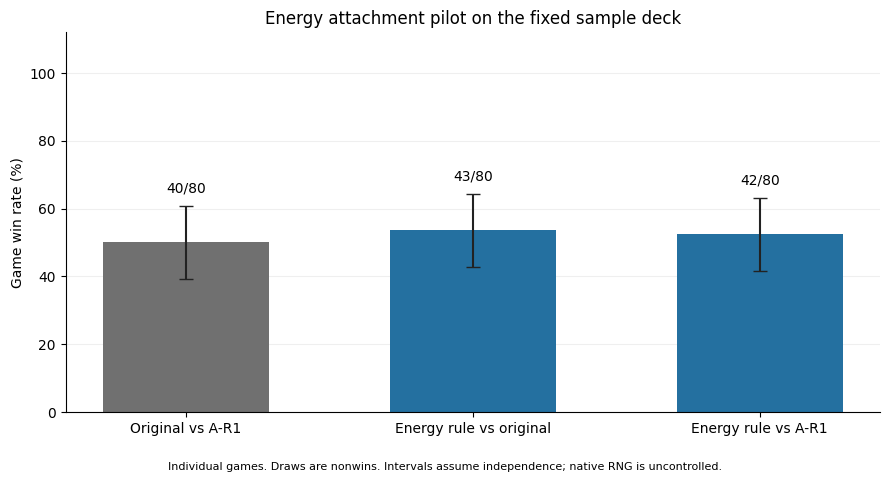

In [7]:
try:
    import matplotlib.pyplot as plt
    plt.rcParams.update({'figure.figsize': (9, 4.8), 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
    labels = {'original_vs_ar1': 'Original vs A-R1', 'energy_vs_original': 'Energy rule vs original',
              'energy_vs_ar1': 'Energy rule vs A-R1'}
    fig, ax = plt.subplots()
    for index, row in enumerate(summary_rows):
        if row['win_rate'] is None:
            ax.text(index, 5, 'No valid games', ha='center')
            continue
        rate, bounds = row['win_rate'], row['win_rate_wilson_95']
        ax.bar(index, rate*100, color=['#707070', '#2470A0', '#2470A0'][index], width=.58)
        ax.errorbar(index, rate*100, yerr=[[max(0, rate-bounds[0])*100], [max(0, bounds[1]-rate)*100]],
                    fmt='none', color='#222222', capsize=5)
        suffix = '' if row['complete_and_valid'] else ' partial'
        ax.text(index, min(105, bounds[1]*100+4), str(row['wins'])+'/'+str(row['valid'])+suffix, ha='center')
    ax.set_xticks(range(len(summary_rows)), [labels[row['comparison']] for row in summary_rows])
    ax.set_ylim(0, 112)
    ax.set_ylabel('Game win rate (%)')
    ax.set_title('Energy attachment pilot on the fixed sample deck')
    ax.grid(axis='y', alpha=.2)
    ax.set_axisbelow(True)
    fig.text(.5, .01, 'Individual games. Draws are nonwins. Intervals assume independence; native RNG is uncontrolled.', ha='center', fontsize=8)
    fig.tight_layout(rect=(0,.05,1,1))
    fig.savefig(output_dir/'battle_comparison.png', dpi=160, bbox_inches='tight')
    plt.show()
except Exception as error:
    save_json(output_dir/'plot_error.json', {'type': type(error).__name__, 'message': str(error)})
    print('Plot unavailable. CSV and JSON results are still saved:', error)


## 8. Save the run

Download the output ZIP and the executed notebook. Decision logs are in each batch and comparison folder. Join a decision's `game_id` with that folder's `games.csv` to inspect wins and losses. Energy attachment records include the visible observation and the reason for keeping or changing the target.

Keep this output within Team A. It contains private reference source, weights and detailed observations. The rule does not create a Kaggle submission package. If the pilot is promising, repeat on fresh evaluation games before changing the teacher or collecting a new training dataset. Keep unsuccessful results for the report as well.


In [8]:
save_json(output_dir/'completion.json', {'run_id': RUN_ID, 'protocol_id': PROTOCOL_ID,
          'all_checks_passed': all_passed, 'assessment': assessment})
archive_path = Path(shutil.make_archive(str(work_dir/('Energy_Rule_'+RUN_ID+'_outputs')), 'zip', output_dir))
print('Output archive:', archive_path)
print('Save the executed notebook through File > Download > Download .ipynb.')
files.download(str(archive_path))
files.download(str(output_dir/'comparison_results.csv'))
files.download(str(output_dir/'evaluation_summary.json'))


Output archive: /content/ptcg_energy_experiment/20261126T211344Z_3118d91a/Energy_Rule_20261126T211344Z_3118d91a_outputs.zip
Save the executed notebook through File > Download > Download .ipynb.
